# Exploración general de datos (EDA)

## 1. Importación de librerías y datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from itertools import combinations
import numpy as np

In [2]:
df = pd.read_csv("DATO_ANONIM_119_IITRIM2026.csv", sep=",")

df.head()

,CENSO_NUMERO,NOFORMULAR,DPTO_MPIO,ANO_CENSO,TRIMESTRE,DESTINO2,ESTADO_ACT,MOVIMIENTO,ESTRATO,LOCALIDAD2,...,UNIDEC_RANVIVI_6,AREA_RANVIVI_1,AREA_RANVIVI_2,AREA_RANVIVI_3,AREA_RANVIVI_4,AREA_RANVIVI_5,AREA_RANVIVI_6,AREA_VIP,AREA_VIS,AREA_NOVIS
0,44,7838,13001,2007,3,1,1,C,6,1,...,111,0.0,0.0,0.0,0.0,0.0,17730.0,NaN,NaN,17730.0
1,44,7839,17001,2007,3,5,1,C,4,7,...,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
2,44,7840,19001,2007,3,4,4,C,3,2,...,0,0.0,0.0,134.0,0.0,0.0,0.0,NaN,NaN,NaN
3,44,7841,41001,2007,3,4,1,C,2,10,...,0,60.0,0.0,0.0,0.0,0.0,0.0,60.0,NaN,NaN
4,44,7842,50001,2007,3,4,1,C,6,2,...,0,0.0,0.0,0.0,0.0,3981.0,0.0,NaN,NaN,3981.0


## 2. Conocimiento inicial de la base

In [3]:
# Número de filas y columnas
print("Filas y columnas:", df.shape)

# Primeras observaciones
df.head()

Filas y columnas: (3278119, 80)


,CENSO_NUMERO,NOFORMULAR,DPTO_MPIO,ANO_CENSO,TRIMESTRE,DESTINO2,ESTADO_ACT,MOVIMIENTO,ESTRATO,LOCALIDAD2,...,UNIDEC_RANVIVI_6,AREA_RANVIVI_1,AREA_RANVIVI_2,AREA_RANVIVI_3,AREA_RANVIVI_4,AREA_RANVIVI_5,AREA_RANVIVI_6,AREA_VIP,AREA_VIS,AREA_NOVIS
0,44,7838,13001,2007,3,1,1,C,6,1,...,111,0.0,0.0,0.0,0.0,0.0,17730.0,NaN,NaN,17730.0
1,44,7839,17001,2007,3,5,1,C,4,7,...,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
2,44,7840,19001,2007,3,4,4,C,3,2,...,0,0.0,0.0,134.0,0.0,0.0,0.0,NaN,NaN,NaN
3,44,7841,41001,2007,3,4,1,C,2,10,...,0,60.0,0.0,0.0,0.0,0.0,0.0,60.0,NaN,NaN
4,44,7842,50001,2007,3,4,1,C,6,2,...,0,0.0,0.0,0.0,0.0,3981.0,0.0,NaN,NaN,3981.0


In [4]:
# Tipos de datos y cantidad de registros no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3278119 entries, 0 to 3278118
Data columns (total 80 columns):
 #   Column             Dtype  
---  ------             -----  
 0   CENSO_NUMERO       int64  
 1   NOFORMULAR         int64  
 2   DPTO_MPIO          int64  
 3   ANO_CENSO          int64  
 4   TRIMESTRE          int64  
 5   DESTINO2           int64  
 6   ESTADO_ACT         int64  
 7   MOVIMIENTO         object 
 8   ESTRATO            int64  
 9   LOCALIDAD2         int64  
 10  AMPLIACION         float64
 11  MESINICIO          object 
 12  OB_FORMAL          float64
 13  USO                int64  
 14  USO_DOS            float64
 15  AREATOTZC          float64
 16  MESREINICI         float64
 17  ANOREINICI         float64
 18  MESCULMINA         float64
 19  ANOCULMINA         float64
 20  AREAUNITGA         float64
 21  UNIDADESGA         float64
 22  PRECIOUNIG         float64
 23  TIPOVALOR          float64
 24  SIS_CONSTR         float64
 25  MANO_OBRAP        

In [5]:
# Nombres de las variables y tipos de datos
print(df.columns)
print(df.dtypes)

Index(['CENSO_NUMERO', 'NOFORMULAR', 'DPTO_MPIO', 'ANO_CENSO', 'TRIMESTRE',
       'DESTINO2', 'ESTADO_ACT', 'MOVIMIENTO', 'ESTRATO', 'LOCALIDAD2',
       'AMPLIACION', 'MESINICIO', 'OB_FORMAL', 'USO', 'USO_DOS', 'AREATOTZC',
       'MESREINICI', 'ANOREINICI', 'MESCULMINA', 'ANOCULMINA', 'AREAUNITGA',
       'UNIDADESGA', 'PRECIOUNIG', 'TIPOVALOR', 'SIS_CONSTR', 'MANO_OBRAP',
       'MANO_OBRAT', 'MANO_OBRAF', 'AREAVENDIB', 'NUMUNIDEST', 'NUMUNIVEN',
       'NUMUNIXVEN', 'NRO_EDIFIC', 'NRO_PISOS', 'CAPITULO', 'GRADOAVANC',
       'TIPOVRDEST', 'PRECIOVTAX', 'AREATOTCO2', 'AREAVENUNI', 'RANVIVI',
       'MEZ_OBRA', 'CONCRETO', 'LIC_RADICADO_SN', 'C1_EXCAVACION',
       'C1_CIMENTACION', 'C1_DESAGUES', 'C2_ESTRUCTURA', 'C2_INST_HIDELEC',
       'C2_CUBIERTA', 'C3_MAMPOSTERIA', 'C3_PANETE', 'C4_PISO_ENCHAPE',
       'C4_CARP_METALICA', 'C4_CARP_MADERA', 'C4_CIELO_RASO',
       'C5_VID_CERRAJERIA', 'C5_PINTURA', 'C6_REM_EXTERIORES',
       'C6_REM_ACABADOS', 'C6_ASEO', 'CONS_ID', 'UNI_DEC_

## 3. Evaluación de la calidad de los datos

### 3.1. Completitud

In [6]:
completitud = pd.DataFrame({
    "Valores nulos": df.isna().sum(),
    "% Nulos": (df.isna().sum() / len(df) * 100).round(2),
    "% Completitud": (100 - df.isna().sum() / len(df) * 100).round(2)
})

# Mostrar únicamente columnas con al menos un valor nulo
completitud = completitud[completitud["Valores nulos"] > 0]

display(completitud.sort_values("% Completitud"))

,Valores nulos,% Nulos,% Completitud
MESREINICI,3194941,97.46,2.54
ANOREINICI,3194941,97.46,2.54
UNIDADESGA,3123263,95.28,4.72
AREAUNITGA,3122491,95.25,4.75
PRECIOUNIG,3122509,95.25,4.75
TIPOVALOR,3122548,95.25,4.75
MESCULMINA,2915075,88.93,11.07
ANOCULMINA,2915108,88.93,11.07
AREA_VIP,2536855,77.39,22.61
UNI_DEC_VIP,2536855,77.39,22.61


### 3.2. Consistencia

In [7]:
# Registros exactamente iguales en todas las columnas
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 27


In [8]:
# Hasta 15 valores más frecuentes de cada variable categórica
categoricas = df.select_dtypes(include=["object", "category", "bool"])

for col in categoricas.columns:
    print("Variable:", col)
    print(df[col].value_counts(dropna=False).head(15))
    print()

Variable: MOVIMIENTO
MOVIMIENTO
C    1803165
S     400892
N     392552
T     365677
I     234320
R      75118
A       6032
F        363
Name: count, dtype: int64

Variable: MESINICIO
MESINICIO
NaN                 98511
01AUG15:00:00:00    25221
01JAN15:00:00:00    25075
01JAN16:00:00:00    25049
01APR15:00:00:00    24319
01JAN14:00:00:00    24149
01JAN17:00:00:00    23989
01FEB15:00:00:00    23882
01MAR15:00:00:00    23840
01MAY15:00:00:00    23705
01FEB17:00:00:00    23324
01FEB14:00:00:00    22812
01JUN15:00:00:00    22748
01SEP15:00:00:00    22703
01FEB16:00:00:00    22163
Name: count, dtype: int64



### 3.3. Claridad

In [9]:
claridad = pd.DataFrame({
    "Tipo de dato": df.dtypes,
    "Valores únicos": df.nunique()
})

claridad

,Tipo de dato,Valores únicos
CENSO_NUMERO,int64,76
NOFORMULAR,int64,390033
DPTO_MPIO,int64,92
ANO_CENSO,int64,20
TRIMESTRE,int64,4
...,...,...
AREA_RANVIVI_5,float64,9435
AREA_RANVIVI_6,float64,8449
AREA_VIP,float64,2668
AREA_VIS,float64,5829


In [10]:
# Muestra de hasta 15 valores diferentes por columna
resumen_valores = pd.DataFrame({
    "Columna": df.columns,
    "Tipo de dato": df.dtypes.astype(str).values,
    "Valores únicos": [
        ", ".join(map(str, df[col].dropna().unique()[:15]))
        for col in df.columns
    ],
    "Total valores únicos": [
        df[col].nunique()
        for col in df.columns
    ]
})
pd.set_option("display.max_rows", None)

display(resumen_valores)

,Columna,Tipo de dato,Valores únicos,Total valores únicos
0,CENSO_NUMERO,int64,"44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55...",76
1,NOFORMULAR,int64,"7838, 7839, 7840, 7841, 7842, 7844, 7845, 7849...",390033
2,DPTO_MPIO,int64,"13001, 17001, 19001, 41001, 50001, 52001, 5487...",92
3,ANO_CENSO,int64,"2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014...",20
4,TRIMESTRE,int64,"3, 4, 1, 2",4
5,DESTINO2,int64,"1, 5, 4, 3, 2, 6",6
6,ESTADO_ACT,int64,"1, 4, 3, 2, 5, 7",6
7,MOVIMIENTO,object,"C, T, I, N, A, S, R, F",8
8,ESTRATO,int64,"6, 4, 3, 2, 5, 1",6
9,LOCALIDAD2,int64,"1, 7, 2, 10, 9, 0, 8, 6, 3, 4, 5, 11, 12, 13, 22",26


### 3.4. Formato

In [11]:
# Tipos de datos detectados al cargar la base
pd.set_option("display.max_rows", None)
display(df.dtypes)

CENSO_NUMERO           int64
NOFORMULAR             int64
DPTO_MPIO              int64
ANO_CENSO              int64
TRIMESTRE              int64
DESTINO2               int64
ESTADO_ACT             int64
MOVIMIENTO            object
ESTRATO                int64
LOCALIDAD2             int64
AMPLIACION           float64
MESINICIO             object
OB_FORMAL            float64
USO                    int64
USO_DOS              float64
AREATOTZC            float64
MESREINICI           float64
ANOREINICI           float64
MESCULMINA           float64
ANOCULMINA           float64
AREAUNITGA           float64
UNIDADESGA           float64
PRECIOUNIG           float64
TIPOVALOR            float64
SIS_CONSTR           float64
MANO_OBRAP             int64
MANO_OBRAT             int64
MANO_OBRAF           float64
AREAVENDIB           float64
NUMUNIDEST             int64
NUMUNIVEN            float64
NUMUNIXVEN           float64
NRO_EDIFIC           float64
NRO_PISOS              int64
CAPITULO      

## 3.4.1 Convertir tipos
Antes de poder analizar las variables a través de gráficas y tablas es necesario definir el tipo correcto a cada una, adicional se realiza una posible primera clasificación que será útil para definir si son útiles para resolver el problema de negocio

In [12]:
# 1. IDENTIFICACIÓN Y UBICACIÓN

df["CENSO_NUMERO"] = df["CENSO_NUMERO"].astype("Int64")
df["NOFORMULAR"] = df["NOFORMULAR"].astype("string")
df["DPTO_MPIO"] = df["DPTO_MPIO"].astype("string").str.zfill(5)
df["ANO_CENSO"] = df["ANO_CENSO"].astype("Int64")
df["TRIMESTRE"] = df["TRIMESTRE"].astype("category")

# 2. CARACTERÍSTICAS DE LA EDIFICACIÓN

df["DESTINO2"] = df["DESTINO2"].astype("category")
df["ESTADO_ACT"] = df["ESTADO_ACT"].astype("category")
df["MOVIMIENTO"] = df["MOVIMIENTO"].astype("category")
df["ESTRATO"] = df["ESTRATO"].astype("category")
df["LOCALIDAD2"] = df["LOCALIDAD2"].astype("category")

df["AMPLIACION"] = df["AMPLIACION"].astype("Int64").astype("category")
df["OB_FORMAL"] = df["OB_FORMAL"].astype("Int64").astype("category")
df["USO"] = df["USO"].astype("category")
df["USO_DOS"] = df["USO_DOS"].astype("Int64").astype("category")

# 3. FECHAS DE CONSTRUCCIÓN

df["MESINICIO"] = pd.to_datetime(df["MESINICIO"],format="%d%b%y:%H:%M:%S",errors="coerce")

df["MESREINICI"] = df["MESREINICI"].astype("Int64")
df["ANOREINICI"] = df["ANOREINICI"].astype("Int64")
df["MESCULMINA"] = df["MESCULMINA"].astype("Int64")
df["ANOCULMINA"] = df["ANOCULMINA"].astype("Int64")

# 4. ÁREAS Y PARQUEADEROS

df["AREATOTZC"] = df["AREATOTZC"].astype("float64")
df["AREAUNITGA"] = df["AREAUNITGA"].astype("float64")
df["UNIDADESGA"] = df["UNIDADESGA"].astype("Int64")
df["PRECIOUNIG"] = df["PRECIOUNIG"].astype("float64")
df["TIPOVALOR"] = df["TIPOVALOR"].astype("Int64").astype("category")

# 5. SISTEMA CONSTRUCTIVO Y MANO DE OBRA - Inicialmente pensaría en descartarlo

df["SIS_CONSTR"] = df["SIS_CONSTR"].astype("Int64").astype("category")
df["MANO_OBRAP"] = df["MANO_OBRAP"].astype("Int64")
df["MANO_OBRAT"] = df["MANO_OBRAT"].astype("Int64")
df["MANO_OBRAF"] = df["MANO_OBRAF"].astype("Int64")

# 6. UNIDADES Y CARACTERÍSTICAS DEL PROYECTO

df["AREAVENDIB"] = df["AREAVENDIB"].astype("float64")
df["NUMUNIDEST"] = df["NUMUNIDEST"].astype("Int64")
df["NUMUNIVEN"] = df["NUMUNIVEN"].astype("Int64")
df["NUMUNIXVEN"] = df["NUMUNIXVEN"].astype("Int64")
df["NRO_EDIFIC"] = df["NRO_EDIFIC"].astype("Int64")
df["NRO_PISOS"] = df["NRO_PISOS"].astype("Int64")

# 7. AVANCE, PRECIOS Y ÁREAS

df["CAPITULO"] = df["CAPITULO"].astype("category")
df["GRADOAVANC"] = df["GRADOAVANC"].astype("float64")

df["TIPOVRDEST"] = df["TIPOVRDEST"].astype("category")
df["PRECIOVTAX"] = df["PRECIOVTAX"].astype("float64")

df["AREATOTCO2"] = df["AREATOTCO2"].astype("float64")
df["AREAVENUNI"] = df["AREAVENUNI"].astype("float64")
df["RANVIVI"] = df["RANVIVI"].astype("Int64").astype("category")

# 8. CARACTERÍSTICAS ADICIONALES
df["MEZ_OBRA"] = df["MEZ_OBRA"].astype("Int64").astype("category")
df["CONCRETO"] = df["CONCRETO"].astype("Int64").astype("category")
df["LIC_RADICADO_SN"] = df["LIC_RADICADO_SN"].astype("Int64").astype("category")

# 9. PORCENTAJES DE AVANCE CONSTRUCTIVO - Inicialmente pensaría en descartarlo

df["C1_EXCAVACION"] = df["C1_EXCAVACION"].astype("float64")
df["C1_CIMENTACION"] = df["C1_CIMENTACION"].astype("float64")
df["C1_DESAGUES"] = df["C1_DESAGUES"].astype("float64")

df["C2_ESTRUCTURA"] = df["C2_ESTRUCTURA"].astype("float64")
df["C2_INST_HIDELEC"] = df["C2_INST_HIDELEC"].astype("float64")
df["C2_CUBIERTA"] = df["C2_CUBIERTA"].astype("float64")

df["C3_MAMPOSTERIA"] = df["C3_MAMPOSTERIA"].astype("float64")
df["C3_PANETE"] = df["C3_PANETE"].astype("float64")

df["C4_PISO_ENCHAPE"] = df["C4_PISO_ENCHAPE"].astype("float64")
df["C4_CARP_METALICA"] = df["C4_CARP_METALICA"].astype("float64")
df["C4_CARP_MADERA"] = df["C4_CARP_MADERA"].astype("float64")
df["C4_CIELO_RASO"] = df["C4_CIELO_RASO"].astype("float64")

df["C5_VID_CERRAJERIA"] = df["C5_VID_CERRAJERIA"].astype("float64")
df["C5_PINTURA"] = df["C5_PINTURA"].astype("float64")

df["C6_REM_EXTERIORES"] = df["C6_REM_EXTERIORES"].astype("float64")
df["C6_REM_ACABADOS"] = df["C6_REM_ACABADOS"].astype("float64")
df["C6_ASEO"] = df["C6_ASEO"].astype("float64")

# 10. IDENTIFICADOR Y TIPOS DE VIVIENDA

df["CONS_ID"] = df["CONS_ID"].astype("string")

df["UNI_DEC_VIP"] = df["UNI_DEC_VIP"].astype("Int64")
df["UNI_DEC_VIS"] = df["UNI_DEC_VIS"].astype("Int64")
df["UNI_DEC_NOVIS"] = df["UNI_DEC_NOVIS"].astype("Int64")

# 11. UNIDADES POR RANGO DE VIVIENDA - Inicialmente pensaría en descartarlo

df["UNIDEC_RANVIVI_1"] = df["UNIDEC_RANVIVI_1"].astype("Int64")
df["UNIDEC_RANVIVI_2"] = df["UNIDEC_RANVIVI_2"].astype("Int64")
df["UNIDEC_RANVIVI_3"] = df["UNIDEC_RANVIVI_3"].astype("Int64")
df["UNIDEC_RANVIVI_4"] = df["UNIDEC_RANVIVI_4"].astype("Int64")
df["UNIDEC_RANVIVI_5"] = df["UNIDEC_RANVIVI_5"].astype("Int64")
df["UNIDEC_RANVIVI_6"] = df["UNIDEC_RANVIVI_6"].astype("Int64")

# 12. ÁREAS POR RANGO DE VIVIENDA - Inicialmente pensaría en descartarlo

df["AREA_RANVIVI_1"] = df["AREA_RANVIVI_1"].astype("float64")
df["AREA_RANVIVI_2"] = df["AREA_RANVIVI_2"].astype("float64")
df["AREA_RANVIVI_3"] = df["AREA_RANVIVI_3"].astype("float64")
df["AREA_RANVIVI_4"] = df["AREA_RANVIVI_4"].astype("float64")
df["AREA_RANVIVI_5"] = df["AREA_RANVIVI_5"].astype("float64")
df["AREA_RANVIVI_6"] = df["AREA_RANVIVI_6"].astype("float64")

# 13. ÁREAS POR TIPO DE VIVIENDA

df["AREA_VIP"] = df["AREA_VIP"].astype("float64")
df["AREA_VIS"] = df["AREA_VIS"].astype("float64")
df["AREA_NOVIS"] = df["AREA_NOVIS"].astype("float64")


print(df.dtypes.to_string())


CENSO_NUMERO                  Int64
NOFORMULAR           string[python]
DPTO_MPIO            string[python]
ANO_CENSO                     Int64
TRIMESTRE                  category
DESTINO2                   category
ESTADO_ACT                 category
MOVIMIENTO                 category
ESTRATO                    category
LOCALIDAD2                 category
AMPLIACION                 category
MESINICIO            datetime64[ns]
OB_FORMAL                  category
USO                        category
USO_DOS                    category
AREATOTZC                   float64
MESREINICI                    Int64
ANOREINICI                    Int64
MESCULMINA                    Int64
ANOCULMINA                    Int64
AREAUNITGA                  float64
UNIDADESGA                    Int64
PRECIOUNIG                  float64
TIPOVALOR                  category
SIS_CONSTR                 category
MANO_OBRAP                    Int64
MANO_OBRAT                    Int64
MANO_OBRAF                  

In [13]:
# Muestra de hasta 15 valores diferentes por columna
resumen_valores = pd.DataFrame({
    "Columna": df.columns,
    "Tipo de dato": df.dtypes.astype(str).values,
    "Valores únicos": [
        ", ".join(map(str, df[col].dropna().unique()[:15]))
        for col in df.columns
    ],
    "Total valores únicos": [
        df[col].nunique()
        for col in df.columns
    ]
})
pd.set_option("display.max_rows", None)

display(resumen_valores)

,Columna,Tipo de dato,Valores únicos,Total valores únicos
0,CENSO_NUMERO,Int64,"44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55...",76
1,NOFORMULAR,string,"7838, 7839, 7840, 7841, 7842, 7844, 7845, 7849...",390033
2,DPTO_MPIO,string,"13001, 17001, 19001, 41001, 50001, 52001, 5487...",92
3,ANO_CENSO,Int64,"2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014...",20
4,TRIMESTRE,category,"3, 4, 1, 2",4
5,DESTINO2,category,"1, 5, 4, 3, 2, 6",6
6,ESTADO_ACT,category,"1, 4, 3, 2, 5, 7",6
7,MOVIMIENTO,category,"C, T, I, N, A, S, R, F",8
8,ESTRATO,category,"6, 4, 3, 2, 5, 1",6
9,LOCALIDAD2,category,"1, 7, 2, 10, 9, 0, 8, 6, 3, 4, 5, 11, 12, 13, 22",26


Revisando nuevamente el tipo de variable y la cantidad de información disponible se decide realizar una depuración inicial de variables justificada de la siguiente manera: PENDIENTE!!

In [14]:
dfprovisional = df[[
    # Identificación (5)
    "CONS_ID",
    "NOFORMULAR", #IDENTIFICADOR ÚNICO
    "DPTO_MPIO",
    "ANO_CENSO",
    "TRIMESTRE",
    "CENSO_NUMERO",

    # Características (6)
    "DESTINO2",
    "ESTADO_ACT",
    "MOVIMIENTO",
    "ESTRATO",
    "USO",
    "USO_DOS",

    # Comercialización (6)
    "NUMUNIDEST",
    "NUMUNIVEN",
    "NUMUNIXVEN",
    "UNI_DEC_VIP",
    "UNI_DEC_VIS",
    "UNI_DEC_NOVIS",

    # Precios y áreas (6)
    "TIPOVRDEST",
    "PRECIOVTAX",
    "AREAVENDIB",
    "AREAVENUNI",
    "AREATOTCO2",
    "RANVIVI",

    # Actividad constructora (7)
    "NRO_EDIFIC",
    "NRO_PISOS",
    "GRADOAVANC",
    "CAPITULO",
    "MESINICIO",
    "ANOCULMINA",
    "MESCULMINA"
]].copy()

# Verificar dimensiones y tipos de datos
print(dfprovisional.shape)
print(dfprovisional.dtypes)

# Visualizar los primeros registros
display(dfprovisional.head())

(3278119, 31)
CONS_ID          string[python]
NOFORMULAR       string[python]
DPTO_MPIO        string[python]
ANO_CENSO                 Int64
TRIMESTRE              category
CENSO_NUMERO              Int64
DESTINO2               category
ESTADO_ACT             category
MOVIMIENTO             category
ESTRATO                category
USO                    category
USO_DOS                category
NUMUNIDEST                Int64
NUMUNIVEN                 Int64
NUMUNIXVEN                Int64
UNI_DEC_VIP               Int64
UNI_DEC_VIS               Int64
UNI_DEC_NOVIS             Int64
TIPOVRDEST             category
PRECIOVTAX              float64
AREAVENDIB              float64
AREAVENUNI              float64
AREATOTCO2              float64
RANVIVI                category
NRO_EDIFIC                Int64
NRO_PISOS                 Int64
GRADOAVANC              float64
CAPITULO               category
MESINICIO        datetime64[ns]
ANOCULMINA                Int64
MESCULMINA                

,CONS_ID,NOFORMULAR,DPTO_MPIO,ANO_CENSO,TRIMESTRE,CENSO_NUMERO,DESTINO2,ESTADO_ACT,MOVIMIENTO,ESTRATO,...,AREAVENUNI,AREATOTCO2,RANVIVI,NRO_EDIFIC,NRO_PISOS,GRADOAVANC,CAPITULO,MESINICIO,ANOCULMINA,MESCULMINA
0,101836,7838,13001,2007,3,44,1,1,C,6,...,136.306306,17730.0,6,0,1,40.0,2,2007-01-01,<NA>,<NA>
1,107076,7839,17001,2007,3,44,5,1,C,4,...,150.000000,150.0,0,0,1,80.0,5,2007-01-01,<NA>,<NA>
2,113034,7840,19001,2007,3,44,4,4,C,3,...,134.000000,134.0,3,1,1,80.0,3,NaT,<NA>,<NA>
3,122210,7841,41001,2007,3,44,4,1,C,2,...,60.000000,60.0,1,1,1,77.0,3,2007-03-01,<NA>,<NA>
4,127942,7842,50001,2007,3,44,4,1,C,6,...,84.260870,3981.0,5,46,1,95.0,3,2006-11-01,<NA>,<NA>


In [15]:
print(dfprovisional.shape)
print(dfprovisional.columns.tolist())
dfprovisional.head()

(3278119, 31)
['CONS_ID', 'NOFORMULAR', 'DPTO_MPIO', 'ANO_CENSO', 'TRIMESTRE', 'CENSO_NUMERO', 'DESTINO2', 'ESTADO_ACT', 'MOVIMIENTO', 'ESTRATO', 'USO', 'USO_DOS', 'NUMUNIDEST', 'NUMUNIVEN', 'NUMUNIXVEN', 'UNI_DEC_VIP', 'UNI_DEC_VIS', 'UNI_DEC_NOVIS', 'TIPOVRDEST', 'PRECIOVTAX', 'AREAVENDIB', 'AREAVENUNI', 'AREATOTCO2', 'RANVIVI', 'NRO_EDIFIC', 'NRO_PISOS', 'GRADOAVANC', 'CAPITULO', 'MESINICIO', 'ANOCULMINA', 'MESCULMINA']


,CONS_ID,NOFORMULAR,DPTO_MPIO,ANO_CENSO,TRIMESTRE,CENSO_NUMERO,DESTINO2,ESTADO_ACT,MOVIMIENTO,ESTRATO,...,AREAVENUNI,AREATOTCO2,RANVIVI,NRO_EDIFIC,NRO_PISOS,GRADOAVANC,CAPITULO,MESINICIO,ANOCULMINA,MESCULMINA
0,101836,7838,13001,2007,3,44,1,1,C,6,...,136.306306,17730.0,6,0,1,40.0,2,2007-01-01,<NA>,<NA>
1,107076,7839,17001,2007,3,44,5,1,C,4,...,150.000000,150.0,0,0,1,80.0,5,2007-01-01,<NA>,<NA>
2,113034,7840,19001,2007,3,44,4,4,C,3,...,134.000000,134.0,3,1,1,80.0,3,NaT,<NA>,<NA>
3,122210,7841,41001,2007,3,44,4,1,C,2,...,60.000000,60.0,1,1,1,77.0,3,2007-03-01,<NA>,<NA>
4,127942,7842,50001,2007,3,44,4,1,C,6,...,84.260870,3981.0,5,46,1,95.0,3,2006-11-01,<NA>,<NA>


Se realiza nuevamente la evaluacion de calidad de los datos enfocandonos únicamente en estas columnas:

### 3.1. Completitud

La completitud indica cuánto dato está disponible en cada variable. Calculamos los valores nulos y sus porcentajes sin modificar la base.

In [16]:
completitud = pd.DataFrame({
    "Valores nulos": dfprovisional.isna().sum(),
    "% Nulos": (dfprovisional.isna().sum() / len(dfprovisional) * 100).round(2),
    "% Completitud": (100 - dfprovisional.isna().sum() / len(dfprovisional) * 100).round(2)
})

# Mostrar únicamente columnas con al menos un valor nulo
completitud = completitud[completitud["Valores nulos"] > 0]

display(completitud.sort_values("% Completitud"))

,Valores nulos,% Nulos,% Completitud
ANOCULMINA,2915108,88.93,11.07
MESCULMINA,2915075,88.93,11.07
UNI_DEC_VIP,2536855,77.39,22.61
UNI_DEC_VIS,2436482,74.33,25.67
UNI_DEC_NOVIS,2199924,67.11,32.89
USO_DOS,663141,20.23,79.77
MESINICIO,98511,3.01,96.99
RANVIVI,15815,0.48,99.52
NUMUNIVEN,5,0.00,100.00
NUMUNIXVEN,5,0.00,100.00


A continuación se realiza la exploración de variaables que tienen un porcentaje mayor a 20% para entender que pasa con esos registros

In [17]:
pd.crosstab(dfprovisional["ESTADO_ACT"],dfprovisional["ANOCULMINA"].isna(),normalize="index") * 100

ANOCULMINA,False,True
ESTADO_ACT,,
1,0.001568,99.998432
2,0.001486,99.998514
3,99.964355,0.035645
4,0.001235,99.998765
5,85.507246,14.492754
7,0.000000,100.000000


Las fechas de culminación aparecen principalmente en obras que han culminado, lo cual es coherente con la definición de la variable.

In [18]:
pd.crosstab(dfprovisional["USO"],dfprovisional["USO_DOS"].isna(),normalize="index") * 100

USO_DOS,False,True
USO,,
1,0.008648,99.991352
2,95.621971,4.378029


USO_DOS describe el destino de las edificaciones que no están destinadas a la venta: arrendamiento, donación o uso propio.

In [19]:
pd.crosstab(dfprovisional["DESTINO2"],dfprovisional["UNI_DEC_VIP"].isna(),normalize="index") * 100

UNI_DEC_VIP,False,True
DESTINO2,,
1,23.233149,76.766851
2,0.000000,100.000000
3,0.000000,100.000000
4,29.091825,70.908175
5,0.000000,100.000000
6,0.000000,100.000000


Observamos que:
- En apartamentos (DESTINO2 = 1), el 23.23 % tiene información VIP.
- En casas (DESTINO2 = 4), el 29.09 % tiene información VIP.
- En oficinas, comercio, bodegas y educación, el 100 % de los registros carece de información VIP.
Esto tiene sentido porque UNI_DEC_VIP corresponde a unidades de vivienda de interés prioritario.

Sin embargo, no podemos concluir que los registros sin información VIP correspondan a proyectos con cero unidades VIP. Solo sabemos que la variable no tiene información registrada.

Además, en apartamentos y casas todavía hay aproximadamente un 77 % y 71 % de valores faltantes, respectivamente.

In [20]:
# Seleccionar apartamentos y casas
df_vivienda = dfprovisional[
    dfprovisional["DESTINO2"].isin([1, 4])
]

# Revisar completitud de las variables por año
for col in ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]:

    tabla = df_vivienda.groupby("ANO_CENSO", observed=True)[col].apply(
        lambda x: x.notna().mean() * 100
    )

    print(f"\nPorcentaje de completitud: {col}")
    display(tabla.round(2))


Porcentaje de completitud: UNI_DEC_VIP


ANO_CENSO
2007    21.47
2008    22.63
2009    26.63
2010    31.59
2011    31.50
2012    28.29
2013    26.59
2014    25.10
2015    25.05
2016    24.14
2017    24.54
2018    24.82
2019    26.40
2020    29.70
2021    30.44
2022    29.16
2023    27.83
2024    27.52
2025    27.11
2026    27.66
Name: UNI_DEC_VIP, dtype: float64


Porcentaje de completitud: UNI_DEC_VIS


ANO_CENSO
2007    23.56
2008    23.84
2009    24.32
2010    24.74
2011    26.74
2012    27.97
2013    29.01
2014    30.09
2015    30.88
2016    31.54
2017    32.40
2018    33.78
2019    34.83
2020    32.59
2021    31.26
2022    30.98
2023    31.44
2024    31.89
2025    30.68
2026    29.63
Name: UNI_DEC_VIS, dtype: float64


Porcentaje de completitud: UNI_DEC_NOVIS


ANO_CENSO
2007    43.85
2008    43.52
2009    40.51
2010    36.61
2011    36.49
2012    38.82
2013    40.13
2014    41.54
2015    41.28
2016    41.55
2017    40.41
2018    38.83
2019    36.82
2020    35.45
2021    36.74
2022    38.63
2023    39.72
2024    39.82
2025    42.00
2026    43.05
Name: UNI_DEC_NOVIS, dtype: float64

In [21]:
df_vivienda["UNI_DEC_VIP"].value_counts(dropna=False).head(15)

UNI_DEC_VIP
<NA>    1993279
1        555600
2         84113
3         20565
4         20538
20        13663
24         7456
6          6955
5          3671
8          2660
10         2379
40         2055
12         1576
30         1439
16         1389
Name: count, dtype: Int64

In [22]:
# Cantidad de registros con valor cero
print("VIP:", (df_vivienda["UNI_DEC_VIP"] == 0).sum())
print("VIS:", (df_vivienda["UNI_DEC_VIS"] == 0).sum())
print("No VIS:", (df_vivienda["UNI_DEC_NOVIS"] == 0).sum())

VIP: 0
VIS: 0
No VIS: 0


Como tenemos la variable NUMUNIDEST (número total de unidades), podemos comprobar si coincide con la suma de las unidades VIP, VIS y No VIS.

In [23]:
# Sumar las unidades por tipo de vivienda
suma_unidades = df_vivienda[
    ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]
].fillna(0).sum(axis=1)

# Comparar con el total de unidades
print("Coinciden:", (suma_unidades == df_vivienda["NUMUNIDEST"]).sum())

print("No coinciden:", (suma_unidades != df_vivienda["NUMUNIDEST"]).sum())

# Registros sin información en ninguna de las tres variables
print("Sin clasificación:", df_vivienda[
    ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]
].isna().all(axis=1).sum())

Coinciden: 2637304
No coinciden: 97239
Sin clasificación: 97239


Se encuentra evidencia de que los nulos de las tres variables pueden representar categorías de vivienda que no están presentes en el registro

In [24]:
# Registros sin ninguna clasificación
sin_clasificacion = df_vivienda[
    ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]
].isna().all(axis=1)

# Registros donde la suma coincide
coincide = (
    df_vivienda[
        ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]
    ].fillna(0).sum(axis=1)
    == df_vivienda["NUMUNIDEST"]
)

# Comparar ambas condiciones
pd.crosstab(sin_clasificacion, coincide)

col_0,False,True
row_0,,
False,0,2637304
True,97239,0


En el 100 % de los registros de apartamentos y casas que tienen al menos una de las tres clasificaciones informadas, se cumple que VIP+VID+NOVIS=NUMUNIDEST, si consideraramos temporalmente los valores faltantes como ceros.

Por lo tanto se decide lo siguiente:
• Reemplazar los nulos por cero únicamente en los registros cuya suma de unidades coincide con NUMUNIDEST y se tiene el DESTINO2 =1 o =4, es decir casa o apto. Esto estaría respaldado por una regla de consistencia.
• Mantener como nulos los 97.239 registros sin clasificación, porque no podemos determinar cómo se distribuyen sus unidades entre VIP, VIS y No VIS.

Se identificaron valores faltantes en las variables correspondientes al número de unidades de vivienda VIP, VIS y No VIS. Mediante una validación de consistencia se encontró que, en los 2.637.304 registros residenciales con al menos una clasificación informada, la suma de las tres categorías coincidía con el número total de unidades al considerar temporalmente los valores faltantes como ceros. En consecuencia, se estableció una regla de imputación condicional para dichos registros. Los 97.239 registros sin ninguna clasificación se conservaron con valores faltantes, al no contar con información suficiente para determinar su distribución.


In [25]:

# Crear copia del DataFrame
df_tratado = dfprovisional.copy()

# Variables de clasificación de vivienda
columnas = ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]

# Identificar viviendas con alguna clasificación
condicion = (
    df_tratado["DESTINO2"].isin([1, 4]) &
    df_tratado[columnas].notna().any(axis=1)
)

# Reemplazar nulos por cero únicamente en esos registros
df_tratado.loc[condicion, columnas] = (
    df_tratado.loc[condicion, columnas].fillna(0)
)


In [26]:
completitud = pd.DataFrame({
    "Valores nulos": df_tratado.isna().sum(),
    "% Nulos": (df_tratado.isna().sum() / len(df_tratado) * 100).round(2),
    "% Completitud": (100 - df_tratado.isna().sum() / len(df_tratado) * 100).round(2)
})

# Mostrar únicamente columnas con al menos un valor nulo
completitud = completitud[completitud["Valores nulos"] > 0]

display(completitud.sort_values("% Completitud"))

,Valores nulos,% Nulos,% Completitud
ANOCULMINA,2915108,88.93,11.07
MESCULMINA,2915075,88.93,11.07
USO_DOS,663141,20.23,79.77
UNI_DEC_VIP,640815,19.55,80.45
UNI_DEC_VIS,640815,19.55,80.45
UNI_DEC_NOVIS,640815,19.55,80.45
MESINICIO,98511,3.01,96.99
RANVIVI,15815,0.48,99.52
NUMUNIVEN,5,0.00,100.00
NUMUNIXVEN,5,0.00,100.00


In [27]:

# Agrupar los destinos de edificación
destino = df_tratado["DESTINO2"].astype("string").replace({
    "1": "Vivienda (1 y 4)",
    "4": "Vivienda (1 y 4)",
    "2": "Oficinas",
    "3": "Comercio",
    "5": "Bodegas",
    "6": "Educación"
})

# Crear tabla cruzada
tabla = pd.crosstab(
    destino,
    df_tratado["UNI_DEC_VIP"].isna()
)

# Renombrar columnas
tabla = tabla.reindex(columns=[False, True], fill_value=0)
tabla.columns = ["Con información", "Nulos"]

# Agregar subtotal no residencial
tabla.loc["Subtotal no residencial"] = (
    tabla.drop(index="Vivienda (1 y 4)").sum()
)

# Agregar total general
tabla.loc["Total general"] = (
    tabla.drop(index="Subtotal no residencial").sum()
)

# Calcular totales y porcentajes por fila
tabla["Total"] = tabla["Con información"] + tabla["Nulos"]

tabla["% Completitud"] = (
    tabla["Con información"] / tabla["Total"] * 100
).round(2)

tabla["% Nulos"] = (
    tabla["Nulos"] / tabla["Total"] * 100
).round(2)

display(tabla)



,Con información,Nulos,Total,% Completitud,% Nulos
DESTINO2,,,,,
Bodegas,0,100359,100359,0.00,100.00
Comercio,0,255992,255992,0.00,100.00
Educación,0,153776,153776,0.00,100.00
Oficinas,0,33449,33449,0.00,100.00
Vivienda (1 y 4),2637304,97239,2734543,96.44,3.56
Subtotal no residencial,0,543576,543576,0.00,100.00
Total general,2637304,640815,3278119,80.45,19.55


Se concluye que no se van a tratar los datos nulos para edificaciones no residenciales debido a que el campo es numérico por lo que no se van a imputar valores de texto, y por otro lado el problema de negocio está enfocada en proyectos de vivienda por lo que inicialmente se esperaría que no afectara posteriormente el análisis

### 3.2. Consistencia

Buscamos registros exactamente duplicados y diferencias en cómo aparecen escritas las categorías. Las estadísticas numéricas de la sección 4 ayudarán a revisar posibles valores incoherentes (por ejemplo, áreas negativas).

In [28]:
# Registros exactamente iguales en todas las columnas
print("Registros duplicados:", df_tratado.duplicated().sum())

Registros duplicados: 27


Dado que se mantienen los mismos 27 registros duplicados que en la base original se eliminan:

In [29]:
# Guardar copia antes de eliminar duplicados
df_antes_duplicados = df_tratado.copy()

# Eliminar registros exactamente duplicados
df_tratado = df_tratado.drop_duplicates().copy()

# Verificar resultado
print("Registros eliminados:", len(df_antes_duplicados) - len(df_tratado))
print("Duplicados restantes:", df_tratado.duplicated().sum())
print("Registros finales:", len(df_tratado))

Registros eliminados: 27
Duplicados restantes: 0
Registros finales: 3278092


## 3.4.2 Validación de granularidad

In [30]:

# Opción 1: Obra por trimestre
print("Duplicados obra-trimestre:",
    df_tratado.duplicated(
        subset=["NOFORMULAR", "ANO_CENSO", "TRIMESTRE"]
    ).sum()
)

# Opción 2: Obra, destino y trimestre
print("Duplicados obra-destino-trimestre:",
    df_tratado.duplicated(
        subset=["NOFORMULAR", "DESTINO2", "ANO_CENSO", "TRIMESTRE"]
    ).sum()
)


Duplicados obra-trimestre: 182250
Duplicados obra-destino-trimestre: 405


In [31]:
print(
    "Duplicados incluyendo CONS_ID:",
    df_tratado.duplicated(
        subset=[
            "NOFORMULAR",
            "CONS_ID",
            "DESTINO2",
            "ANO_CENSO",
            "TRIMESTRE"
        ]
    ).sum()
)

Duplicados incluyendo CONS_ID: 405


In [32]:
# Columnas que estamos evaluando como clave
claves = [
    "NOFORMULAR",
    "ANO_CENSO",
    "TRIMESTRE",
    "DESTINO2"
]

# Identificar registros con claves repetidas
duplicados = df_tratado[
    df_tratado.duplicated(subset=claves, keep=False)
]

# Mostrar algunos ejemplos
display(
    duplicados[[
        "NOFORMULAR",
        "CONS_ID",
        "CENSO_NUMERO",
        "ANO_CENSO",
        "TRIMESTRE",
        "DESTINO2",
        "DPTO_MPIO",
        "NUMUNIDEST",
        "AREATOTCO2"
    ]].sort_values(claves).head(20)
)

,NOFORMULAR,CONS_ID,CENSO_NUMERO,ANO_CENSO,TRIMESTRE,DESTINO2,DPTO_MPIO,NUMUNIDEST,AREATOTCO2
442529,128051,309207,64,2012,3,6,08001,1,5067.0
442531,128051,309207,64,2012,3,6,08001,1,6428.0
474046,128051,309207,65,2012,4,6,08001,1,5067.0
474047,128051,309207,65,2012,4,6,08001,1,6428.0
506840,128051,309207,66,2013,1,6,08001,1,5067.0
506841,128051,309207,66,2013,1,6,08001,1,6428.0
540475,128051,309207,67,2013,2,6,08001,1,5067.0
540476,128051,309207,67,2013,2,6,08001,1,6428.0
575172,128051,309207,68,2013,3,6,08001,1,5067.0
575174,128051,309207,68,2013,3,6,08001,1,6428.0


In [33]:
# Seleccionar la obra del ejemplo
caso = df_tratado[
    (df_tratado["NOFORMULAR"].astype("string") == "128051") &
    (df_tratado["ANO_CENSO"] == 2012) &
    (df_tratado["TRIMESTRE"] == 3) &
    (df_tratado["DESTINO2"] == "Educación")
]

# Mostrar solo las columnas con diferencias
diferencias = caso.columns[caso.nunique(dropna=False) > 1]

display(caso[diferencias].T)


""


In [34]:

# Variables utilizadas para identificar los duplicados
claves = [
    "NOFORMULAR",
    "CONS_ID",
    "ANO_CENSO",
    "TRIMESTRE",
    "DESTINO2"
]

# Identificar las combinaciones repetidas en df_tratado
grupos = df_tratado.loc[
    df_tratado.duplicated(subset=claves, keep=False),
    claves
].drop_duplicates().copy()

# Recuperar los códigos originales de DESTINO2
grupos["DESTINO2"] = grupos["DESTINO2"].astype("string").replace({
    "Apartamentos": "1",
    "Oficinas": "2",
    "Comercio": "3",
    "Casas": "4",
    "Bodegas": "5",
    "Educación": "6"
})

# Buscar los formularios en la base original
originales = df[
    df["NOFORMULAR"].astype("string").isin(
        grupos["NOFORMULAR"].astype("string")
    )
].copy()

# Conservar el índice original
originales["INDICE_ORIGINAL"] = originales.index

# Igualar tipos para realizar el cruce
for col in claves:
    grupos[col] = grupos[col].astype("string")
    originales[col] = originales[col].astype("string")

# Recuperar los registros completos
df_405_original = originales.merge(
    grupos,
    on=claves,
    how="inner"
)

# Verificar resultados
print("Registros recuperados:", len(df_405_original))
print("Columnas recuperadas:", df_405_original.shape[1])

# Visualizar los primeros registros con todas sus variables
display(df_405_original.head(10).T)


Registros recuperados: 797
Columnas recuperadas: 81


,0,1,2,3,4,5,6,7,8,9
CENSO_NUMERO,45,45,46,46,47,47,47,47,47,47
NOFORMULAR,152778,152778,152778,152778,152778,152778,155665,155665,156836,156836
DPTO_MPIO,05001,05001,05001,05001,05001,05001,05001,05001,05001,05001
ANO_CENSO,2007,2007,2008,2008,2008,2008,2008,2008,2008,2008
TRIMESTRE,4,4,1,1,2,2,2,2,2,2
DESTINO2,6,6,6,6,6,6,6,6,6,6
ESTADO_ACT,1,1,1,1,1,1,1,1,1,1
MOVIMIENTO,N,N,C,C,C,C,N,N,N,N
ESTRATO,4,4,4,4,4,4,6,6,4,4
LOCALIDAD2,0,0,0,0,0,0,14,14,10,10


In [35]:
df_405_original.to_excel(
    "revision_duplicados_ceed.xlsx",
    index=False
)

In [36]:
# Contar cuántos grupos presentan diferencias en cada variable
diferencias = df_405_original.groupby(claves, dropna=False).nunique(dropna=False)

# Mostrar las variables que presentan diferencias
display(
    (diferencias > 1).sum().sort_values(ascending=False).head(30)
)

INDICE_ORIGINAL      392
AREATOTCO2           387
AREAVENUNI           387
AREAVENDIB           387
PRECIOVTAX           214
NRO_PISOS            183
GRADOAVANC            89
C4_CARP_METALICA      53
C3_MAMPOSTERIA        50
C5_VID_CERRAJERIA     50
C4_PISO_ENCHAPE       49
C3_PANETE             48
C4_CARP_MADERA        48
CAPITULO              45
C2_ESTRUCTURA         41
C2_INST_HIDELEC       39
C2_CUBIERTA           38
C4_CIELO_RASO         36
C5_PINTURA            32
SIS_CONSTR             9
C1_DESAGUES            7
MESINICIO              6
C1_CIMENTACION         4
C1_EXCAVACION          3
C6_REM_EXTERIORES      3
TIPOVRDEST             2
C6_REM_ACABADOS        1
MESREINICI             1
MESCULMINA             1
C6_ASEO                1
dtype: int64

In [37]:

# Comparar las variables principales dentro de los grupos
claves = [
    "NOFORMULAR", "CONS_ID",
    "ANO_CENSO", "TRIMESTRE", "DESTINO2"
]

variables = [
    "NUMUNIDEST",
    "NUMUNIVEN",
    "NUMUNIXVEN",
    "NRO_EDIFIC",
    "AREATOTCO2",
    "AREAVENUNI",
    "AREAVENDIB",
    "PRECIOVTAX"
]

# Contar grupos con diferencias por variable
comparacion = df_405_original.groupby(
    claves, dropna=False
)[variables].nunique(dropna=False)

display((comparacion > 1).sum().sort_values(ascending=False))


AREATOTCO2    387
AREAVENUNI    387
AREAVENDIB    387
PRECIOVTAX    214
NUMUNIDEST      0
NUMUNIVEN       0
NUMUNIXVEN      0
NRO_EDIFIC      0
dtype: int64

In [38]:
columnas = [
    "NOFORMULAR",
    "CONS_ID",
    "ANO_CENSO",
    "TRIMESTRE",
    "DESTINO2",
    "NUMUNIDEST",
    "NRO_EDIFIC",
    "NRO_PISOS",
    "AREATOTCO2",
    "AREAVENDIB",
    "AREAVENUNI",
    "PRECIOVTAX",
    "CAPITULO",
    "GRADOAVANC"
]

display(df.loc[[442529, 442531], columnas].T)


,442529,442531
NOFORMULAR,128051,128051
CONS_ID,309207,309207
ANO_CENSO,2012,2012
TRIMESTRE,3,3
DESTINO2,6,6
NUMUNIDEST,1,1
NRO_EDIFIC,1,1
NRO_PISOS,1,1
AREATOTCO2,5067.0,6428.0
AREAVENDIB,5067.0,6428.0


In [39]:
display(df.loc[[442529, 442531]].T)

,442529,442531
CENSO_NUMERO,64,64
NOFORMULAR,128051,128051
DPTO_MPIO,08001,08001
ANO_CENSO,2012,2012
TRIMESTRE,3,3
DESTINO2,6,6
ESTADO_ACT,1,1
MOVIMIENTO,N,N
ESTRATO,6,6
LOCALIDAD2,0,0


Se confirma que hay registros que tienen el mismo identificador y periodo pero aún así tienen distinta información de área o avance registrada, procede a crearse una llaveunica para identificar estos registros y proceder a su eliminación.

La base de datos del Censo de Edificaciones presenta una estructura longitudinal con periodicidad trimestral. Cada registro contiene información constructiva y comercial asociada a una obra y un destino específico. Una misma obra puede presentar múltiples registros por destino y período, con diferencias en características físicas, precios y avances constructivos. Por tanto, la granularidad corresponde a registros de producción constructiva asociados a obras, destinos y períodos censales, sin que necesariamente exista una relación uno a uno entre filas y obras.

In [40]:
# Crear llave compuesta
df_tratado["LLAVE_UNICA"] = (
    df_tratado["NOFORMULAR"].astype("string") + "_" +
    df_tratado["DESTINO2"].astype("string") + "_" +
    df_tratado["ANO_CENSO"].astype("string") + "_" +
    df_tratado["TRIMESTRE"].astype("string")
)

# Visualizar resultado
display(df_tratado[[
    "LLAVE_UNICA",
    "NOFORMULAR",
    "DESTINO2",
    "ANO_CENSO",
    "TRIMESTRE"
]].head())

,LLAVE_UNICA,NOFORMULAR,DESTINO2,ANO_CENSO,TRIMESTRE
0,7838_1_2007_3,7838,1,2007,3
1,7839_5_2007_3,7839,5,2007,3
2,7840_4_2007_3,7840,4,2007,3
3,7841_4_2007_3,7841,4,2007,3
4,7842_4_2007_3,7842,4,2007,3


In [41]:
df_tratado.head(5)

,CONS_ID,NOFORMULAR,DPTO_MPIO,ANO_CENSO,TRIMESTRE,CENSO_NUMERO,DESTINO2,ESTADO_ACT,MOVIMIENTO,ESTRATO,...,AREATOTCO2,RANVIVI,NRO_EDIFIC,NRO_PISOS,GRADOAVANC,CAPITULO,MESINICIO,ANOCULMINA,MESCULMINA,LLAVE_UNICA
0,101836,7838,13001,2007,3,44,1,1,C,6,...,17730.0,6,0,1,40.0,2,2007-01-01,<NA>,<NA>,7838_1_2007_3
1,107076,7839,17001,2007,3,44,5,1,C,4,...,150.0,0,0,1,80.0,5,2007-01-01,<NA>,<NA>,7839_5_2007_3
2,113034,7840,19001,2007,3,44,4,4,C,3,...,134.0,3,1,1,80.0,3,NaT,<NA>,<NA>,7840_4_2007_3
3,122210,7841,41001,2007,3,44,4,1,C,2,...,60.0,1,1,1,77.0,3,2007-03-01,<NA>,<NA>,7841_4_2007_3
4,127942,7842,50001,2007,3,44,4,1,C,6,...,3981.0,5,46,1,95.0,3,2006-11-01,<NA>,<NA>,7842_4_2007_3


In [42]:

# DEPURACIÓN DE REGISTROS INCONSISTENTES

registros_iniciales = len(df_tratado)

# 1. Eliminar registros con municipio 00000

condicion_municipio = (
    df_tratado["DPTO_MPIO"].astype("string") == "00000"
)

eliminados_municipio = condicion_municipio.sum()

df_tratado = df_tratado.loc[
    ~condicion_municipio.fillna(False)
].copy()


# 2. Eliminar grupos con llave duplicada

claves = [
    "NOFORMULAR",
    "DESTINO2",
    "ANO_CENSO",
    "TRIMESTRE"
]

# keep=False identifica todos los registros
# pertenecientes a grupos con claves repetidas

condicion_duplicados = df_tratado.duplicated(
    subset=claves,
    keep=False
)

eliminados_duplicados = condicion_duplicados.sum()

df_tratado = df_tratado.loc[
    ~condicion_duplicados
].copy()


# 3. Verificar resultados

print("Registros iniciales:", registros_iniciales)
print("Eliminados por municipio 00000:", eliminados_municipio)
print("Eliminados por llaves ambiguas:", eliminados_duplicados)
print("Registros finales:", len(df_tratado))

print(
    "Llaves duplicadas restantes:",
    df_tratado.duplicated(subset=claves).sum()
)

print(
    "Códigos 00000 restantes:",
    (df_tratado["DPTO_MPIO"] == "00000").sum()
)


Registros iniciales: 3278092
Eliminados por municipio 00000: 34577
Eliminados por llaves ambiguas: 659
Registros finales: 3242856
Llaves duplicadas restantes: 0
Códigos 00000 restantes: 0


## 4. Descripción estadística de variables numéricas

Resumen de media, desviación estándar, mínimos, máximos y cuartiles.

In [43]:
numericas = df_tratado.select_dtypes(include="number")

if numericas.shape[1] > 0:
    display(numericas.describe().style.format("{:,.0f}"))
else:
    print("Esta base no tiene columnas numéricas reconocidas por pandas.")

,ANO_CENSO,CENSO_NUMERO,NUMUNIDEST,NUMUNIVEN,NUMUNIXVEN,UNI_DEC_VIP,UNI_DEC_VIS,UNI_DEC_NOVIS,PRECIOVTAX,AREAVENDIB,AREAVENUNI,AREATOTCO2,NRO_EDIFIC,NRO_PISOS,GRADOAVANC,ANOCULMINA,MESCULMINA
count,"3,242,856","3,242,856","3,242,856","3,242,851","3,242,851","2,621,272","2,621,272","2,621,272","3,242,842","3,242,856","3,242,856","3,242,856","3,242,829","3,242,856","3,242,852","359,560","359,594"
mean,"2,018",88,7,1,1,1,3,4,"1,565",707,244,812,1,2,59,"2,017",7
std,5,20,24,8,7,8,16,19,"1,414","2,457","1,514","3,110",6,3,31,10,4
min,"2,007",44,1,0,0,0,0,0,1,1,1,1,0,1,0,0,0
25%,"2,015",74,1,0,0,0,0,0,690,78,60,78,1,1,31,"2,013",3
50%,"2,019",90,1,0,0,0,0,0,"1,100",140,84,140,1,1,60,"2,018",7
75%,"2,022",105,2,0,0,1,1,1,"2,000",312,144,327,1,2,90,"2,022",10
max,"2,026",119,"2,773","2,073","2,773",559,630,654,"32,000","165,882","165,882","208,000",504,83,100,"2,026",12


**Para analizar:** ¿Hay valores extremos, escalas muy diferentes o cifras que no tienen sentido para la definición de una variable? Los códigos de identificación no deben interpretarse como magnitudes.

## 5. Exploración gráfica de variables numéricas

Primero se revisan los histogramas; luego, los diagramas de caja. Ambos procedimientos aparecen en los talleres.

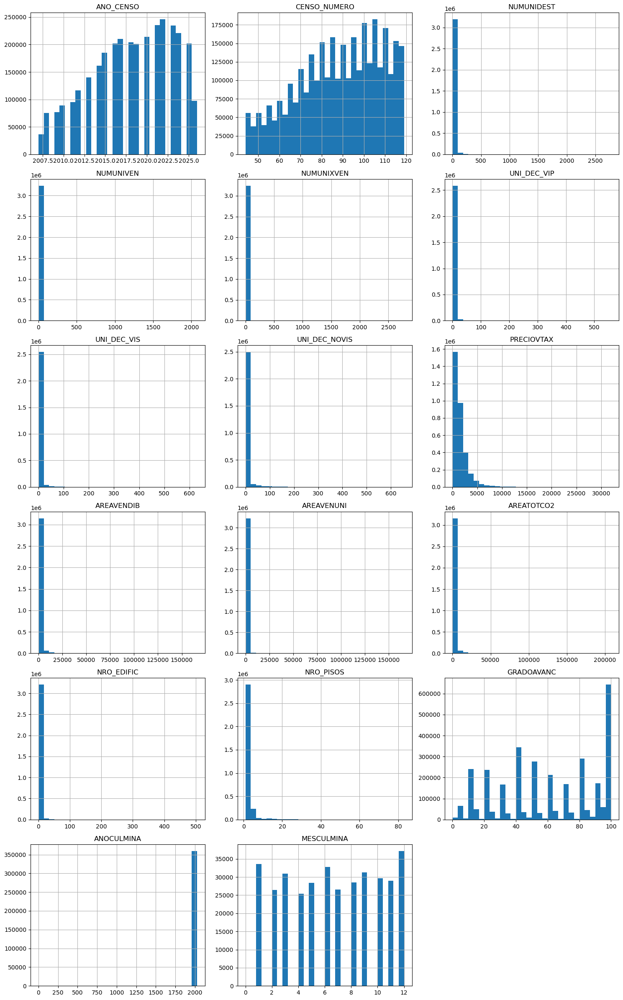

In [44]:
# Histogramas de las columnas numéricas
if numericas.shape[1] > 0:

    filas = math.ceil(numericas.shape[1] / 3)

    numericas.hist(figsize=(15, 4 * filas),bins=30,layout=(filas, 3)    )

    plt.tight_layout()
    plt.show()

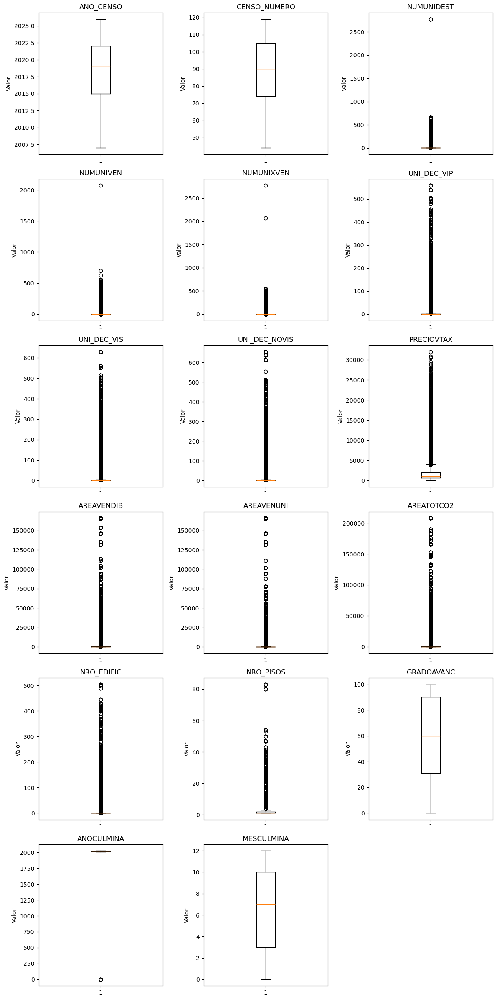

In [45]:
# Diagramas de caja por variable numérica
if numericas.shape[1] > 0:
    columnas = 3
    filas = math.ceil(numericas.shape[1] / columnas)

    plt.figure(figsize=(12, 4 * filas))

    for i, col in enumerate(numericas.columns):
        plt.subplot(filas, columnas, i + 1)
        plt.boxplot(numericas[col].dropna())
        plt.title(col)
        plt.ylabel("Valor")

    plt.tight_layout()
    plt.show()

**Para analizar:** ¿Cómo se distribuyen las variables? ¿Hay asimetrías, concentraciones o posibles valores atípicos? Un punto fuera del diagrama de caja no significa necesariamente un error.

## 6. Exploración de variables categóricas

Se identifican las frecuencias más frecuentes. Los gráficos muestran **hasta tres columnas categóricas** para que la salida no sea demasiado extensa; puedes cambiar `[:3]` según tu necesidad.

Para comprender correctamente como se distribuyen estas variables vamos a incluir sus nombres:

In [46]:
df_tratado2 = df_tratado.copy()

# 1. DESTINO DE LA EDIFICACIÓN

df_tratado2["DESTINO2"] = df_tratado["DESTINO2"].astype("string").replace({
    "1": "Apartamentos",
    "2": "Oficinas",
    "3": "Comercio",
    "4": "Casas",
    "5": "Bodegas",
    "6": "Educación",
    "7": "Hoteles",
    "8": "Hospitales y centros asistenciales",
    "9": "Administración pública",
    "10": "Otros"
}).astype("category")

# 2. ESTADO ACTUAL DE LA OBRA

df_tratado2["ESTADO_ACT"] = df_tratado["ESTADO_ACT"].astype("string").replace({
    "1": "En proceso",
    "2": "Paralizada completa",
    "3": "Culminada completa",
    "4": "Paralizada incompleta",
    "5": "Culminada incompleta",
    "6": "Demolida",
    "7": "Suspendida"
}).astype("category")

# 3. MOVIMIENTO DE LA OBRA

df_tratado2["MOVIMIENTO"] = df_tratado["MOVIMIENTO"].astype("string").replace({
    "N": "Obra nueva",
    "C": "Continúa en estado anterior",
    "F": "Reinicio después de suspensión",
    "I": "Paraliza actividad",
    "A": "Ampliación de cobertura",
    "R": "Reinicia actividad",
    "S": "Obra suspendida",
    "T": "Obra culminada",
    "D": "Obra demolida"
}).astype("category")

# 4. ESTRATO SOCIOECONÓMICO

df_tratado2["ESTRATO"] = df_tratado["ESTRATO"].astype("string").replace({
    "1": "Estrato 1",
    "2": "Estrato 2",
    "3": "Estrato 3",
    "4": "Estrato 4",
    "5": "Estrato 5",
    "6": "Estrato 6"
}).astype("category")

# 5. DESTINO PARA VENTA

df_tratado2["USO"] = df_tratado["USO"].astype("string").replace({
    "1": "Sí venta",
    "2": "No venta"
}).astype("category")


# 6. DESTINO CUANDO NO ES PARA VENTA

df_tratado2["USO_DOS"] = df_tratado["USO_DOS"].astype("string").replace({
    "1": "Arrendamiento",
    "2": "Donación",
    "3": "Uso propio"
}).astype("category")


# 7. PRECIO IMPUTADO DEL DESTINO

df_tratado2["TIPOVRDEST"] = df_tratado["TIPOVRDEST"].astype("string").replace({
    "1": "Sí",
    "2": "No",
    "5440": "Código 5440 (revisar)"
}).astype("category")

# 8. RANGO DE VALOR DE VIVIENDA

#Estos rangos están definidos en salarios mínimos de acuerdo con el municipio, por lo que inicialmente no se hace una inputación mas profunda.

df_tratado2["RANVIVI"] = df_tratado["RANVIVI"].astype("string").replace({
    "0": "Rango 0",
    "1": "Rango 1",
    "2": "Rango 2",
    "3": "Rango 3",
    "4": "Rango 4",
    "5": "Rango 5",
    "6": "Rango 6"
}).astype("category")

# 9. CAPÍTULO CONSTRUCTIVO

df_tratado2["CAPITULO"] = df_tratado["CAPITULO"].astype("string").replace({
    "1": "Excavación y cimentación",
    "2": "Estructura y cubierta",
    "3": "Mampostería y pañete",
    "4": "Acabados nivel 1",
    "5": "Acabados nivel 2",
    "6": "Acabados nivel 3"
}).astype("category")


# ==========================================
# VERIFICAR RESULTADO
# ==========================================

columnas_categoricas = [
    "DESTINO2", "ESTADO_ACT", "MOVIMIENTO",
    "ESTRATO", "USO", "USO_DOS",
    "TIPOVRDEST", "RANVIVI", "CAPITULO"
]

display(df_tratado2[columnas_categoricas].head(10))

print(df_tratado2[columnas_categoricas].dtypes)


,DESTINO2,ESTADO_ACT,MOVIMIENTO,ESTRATO,USO,USO_DOS,TIPOVRDEST,RANVIVI,CAPITULO
0,Apartamentos,En proceso,Continúa en estado anterior,Estrato 6,Sí venta,<NA>,No,Rango 6,Estructura y cubierta
1,Bodegas,En proceso,Continúa en estado anterior,Estrato 4,No venta,Uso propio,Sí,Rango 0,Acabados nivel 2
2,Casas,Paralizada incompleta,Continúa en estado anterior,Estrato 3,No venta,Uso propio,No,Rango 3,Mampostería y pañete
3,Casas,En proceso,Continúa en estado anterior,Estrato 2,No venta,Uso propio,Sí,Rango 1,Mampostería y pañete
4,Casas,En proceso,Continúa en estado anterior,Estrato 6,Sí venta,<NA>,Sí,Rango 5,Mampostería y pañete
5,Apartamentos,En proceso,Continúa en estado anterior,Estrato 5,Sí venta,<NA>,No,Rango 5,Acabados nivel 1
6,Casas,Culminada completa,Obra culminada,Estrato 2,No venta,Uso propio,Sí,Rango 2,Acabados nivel 3
7,Comercio,En proceso,Continúa en estado anterior,Estrato 4,No venta,Uso propio,Sí,Rango 0,Mampostería y pañete
8,Apartamentos,En proceso,Continúa en estado anterior,Estrato 6,Sí venta,<NA>,No,Rango 6,Estructura y cubierta
9,Comercio,En proceso,Continúa en estado anterior,Estrato 3,No venta,Uso propio,Sí,Rango 0,Acabados nivel 1


DESTINO2      category
ESTADO_ACT    category
MOVIMIENTO    category
ESTRATO       category
USO           category
USO_DOS       category
TIPOVRDEST    category
RANVIVI       category
CAPITULO      category
dtype: object


Para nombrar los municipios vamos a cargar la base con los nombre y códigos:

In [47]:
MUNI= pd.read_excel("BaseMunicipiosDIVIPOLA.xlsx")

MUNI.head()

,cod_depto,cod_muni,DEPTO+MPIO,Departamento,Municipio,cobertura
0,5,1,5001,Antioquia,Medellín,77
1,5,79,5079,Antioquia,Barbosa,77
2,5,88,5088,Antioquia,Bello,77
3,5,129,5129,Antioquia,Caldas,77
4,5,212,5212,Antioquia,Copacabana,77


In [48]:
# Asegurar que los códigos tengan el mismo formato
df_tratado2["DPTO_MPIO"] = df_tratado2["DPTO_MPIO"].astype("string").str.zfill(5)
MUNI["DEPTO+MPIO"] = MUNI["DEPTO+MPIO"].astype("string").str.zfill(5)

# Cruzar las tablas
df_tratado2 = df_tratado2.merge(
    MUNI[["DEPTO+MPIO", "Departamento", "Municipio"]].drop_duplicates(),
    left_on="DPTO_MPIO",
    right_on="DEPTO+MPIO",
    how="left",
    validate="many_to_one"
)

# Eliminar la columna duplicada del código
df_tratado2 = df_tratado2.drop(columns="DEPTO+MPIO")

# Verificar resultado
display(df_tratado2[["DPTO_MPIO", "Departamento", "Municipio"]].head(10))


,DPTO_MPIO,Departamento,Municipio
0,13001,Bolívar,Cartagena de Indias
1,17001,Caldas,Manizales
2,19001,Cauca,Popayán
3,41001,Huila,Neiva
4,50001,Meta,Villavicencio
5,52001,Nariño,Pasto
6,54874,Norte de Santander,Villa del Rosario
7,73001,Tolima,Ibagué
8,13001,Bolívar,Cartagena de Indias
9,17001,Caldas,Manizales


In [49]:
print("Registros originales:", len(df_tratado))
print("Registros después del cruce:", len(df_tratado2))

print("Municipios sin identificar:",
      df_tratado2["Municipio"].isna().sum())

Registros originales: 3242856
Registros después del cruce: 3242856
Municipios sin identificar: 0


In [50]:
df_tratado2.loc[
    df_tratado2["Municipio"].isna(),
    "DPTO_MPIO"
].value_counts()

Series([], Name: count, dtype: Int64)

Se identifica que algunos municipios están identificados con el código código 00000 que no corresponde a un municipio válido dentro de la codificación DIVIPOLA habitual, dado que sólo corresponde al 1.05% de los registros, se podría considerar eliminarnos.

In [51]:
pd.crosstab(
    df_tratado2["ANO_CENSO"],
    df_tratado2["DPTO_MPIO"] == "00000"
)

DPTO_MPIO,False
ANO_CENSO,
2007,36562
2008,74938
2009,76823
2010,88802
2011,95255
2012,116392
2013,140152
2014,161707
2015,184993


No se concentran en un año específico

In [52]:
categoricas = df_tratado2.select_dtypes(include=["object", "category", "bool", "string"]).drop(columns=["CONS_ID","NOFORMULAR","DPTO_MPIO","LLAVE_UNICA"])

In [53]:
categoricas.columns

Index(['TRIMESTRE', 'DESTINO2', 'ESTADO_ACT', 'MOVIMIENTO', 'ESTRATO', 'USO',
       'USO_DOS', 'TIPOVRDEST', 'RANVIVI', 'CAPITULO', 'Departamento',
       'Municipio'],
      dtype='object')

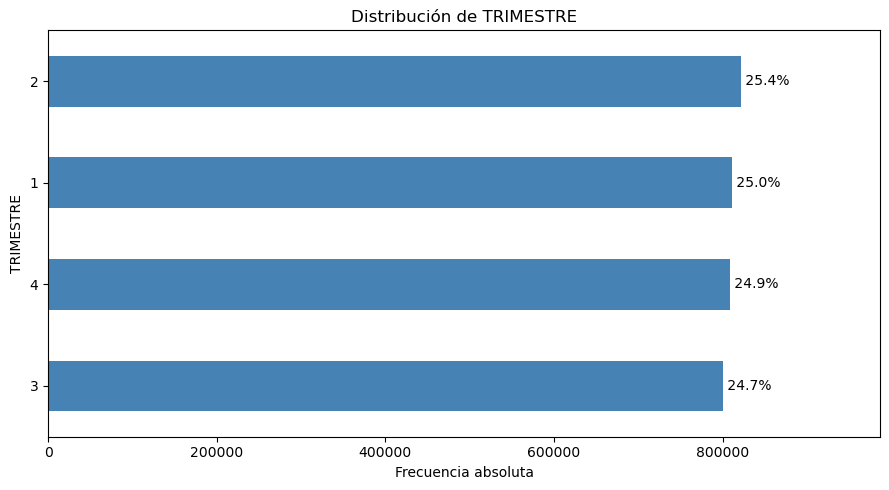

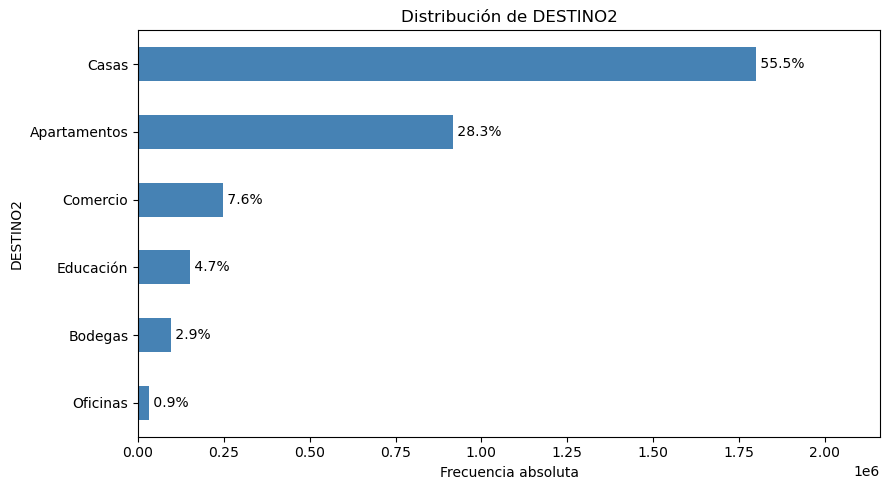

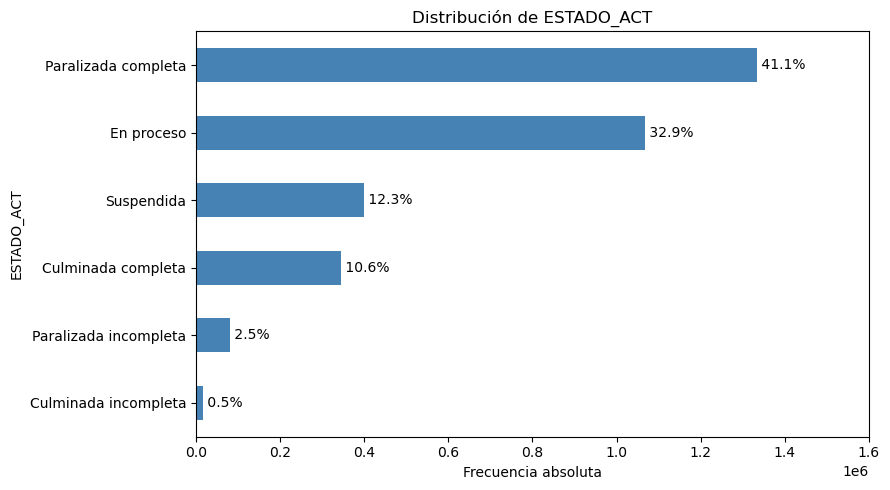

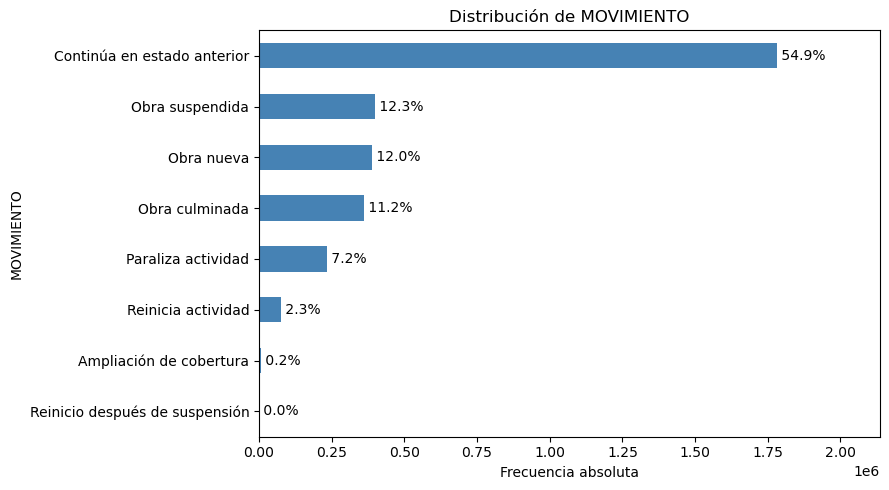

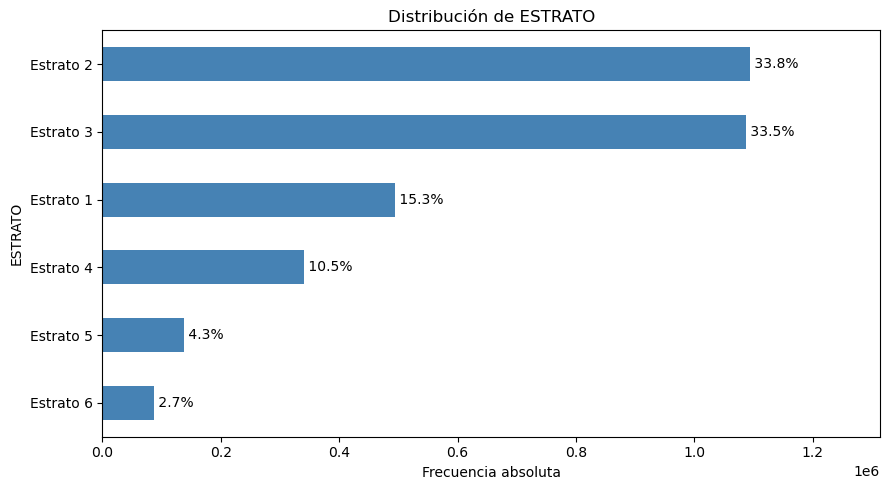

...

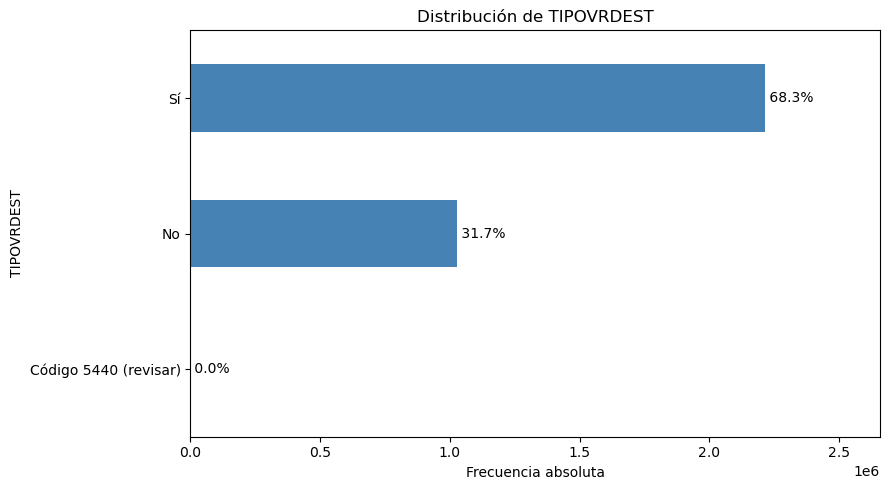

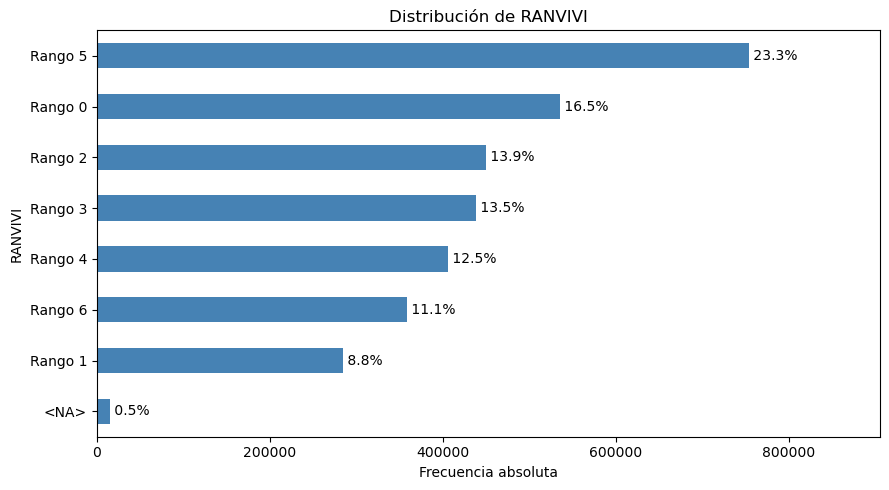

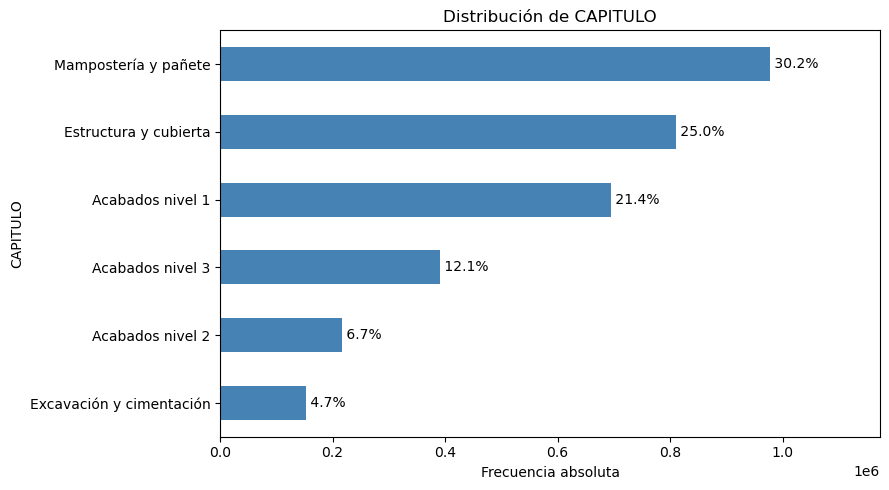

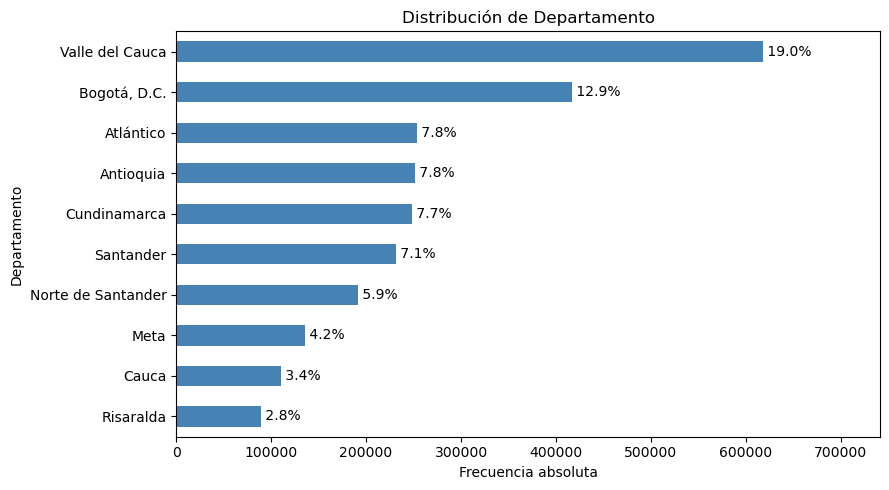

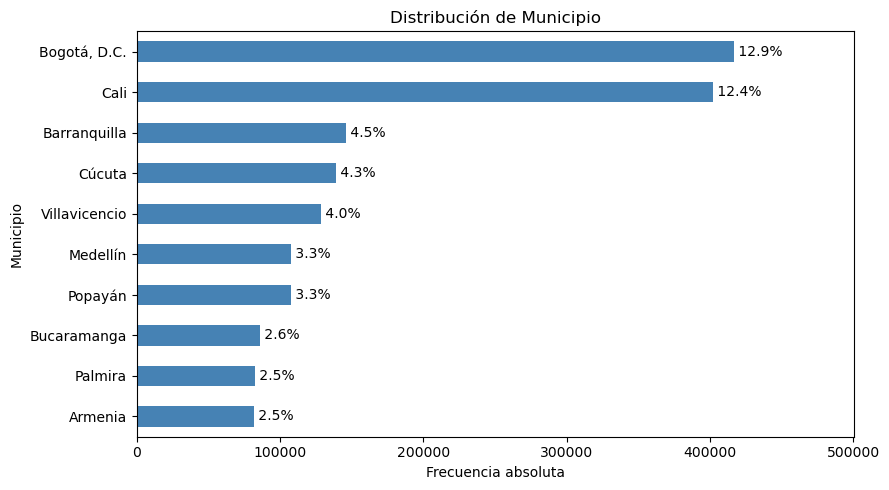

In [54]:
for col in categoricas.columns:

    frecuencias = df_tratado2[col].value_counts(
        dropna=False
    ).head(10).sort_values()

    ax = frecuencias.plot(
        kind="barh",
        figsize=(9, 5),
        color="steelblue"
    )

    # Agregar porcentajes al final de cada barra
    for i, valor in enumerate(frecuencias):
        porcentaje = (valor / len(df_tratado2)) * 100
        ax.text(valor, i, f" {porcentaje:.1f}%", va="center")

    plt.title(f"Distribución de {col}")
    plt.xlabel("Frecuencia absoluta")
    plt.ylabel(col)
    plt.xlim(0, frecuencias.max() * 1.20)
    plt.tight_layout()
    plt.show()


Tabla cruzada: TRIMESTRE vs DESTINO2


DESTINO2,Apartamentos,Bodegas,Casas,Comercio,Educación,Oficinas
TRIMESTRE,,,,,,
1,28.39,2.91,55.40,7.63,4.72,0.95
2,28.65,2.94,55.19,7.63,4.66,0.94
3,27.90,2.92,56.01,7.54,4.68,0.95
4,28.22,2.91,55.56,7.60,4.77,0.95


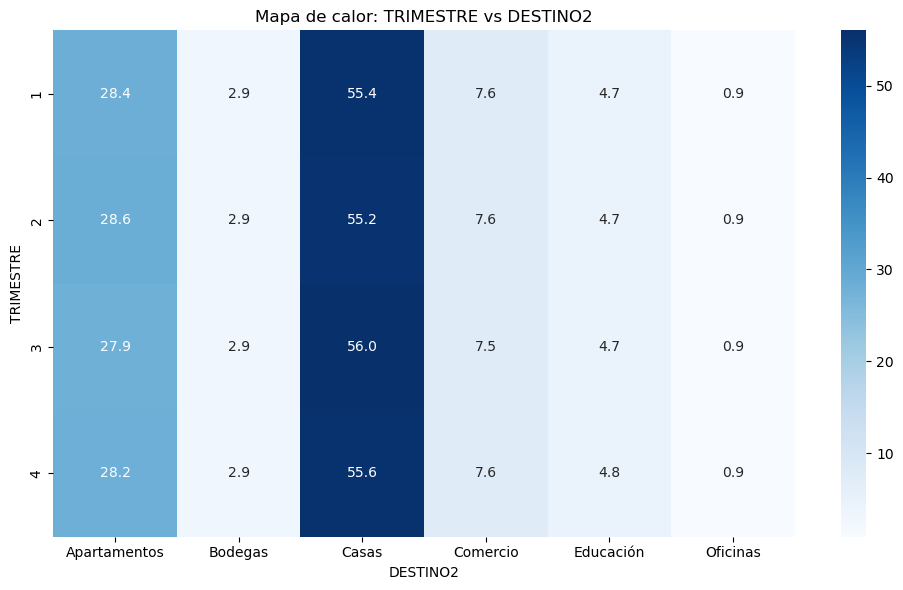


Tabla cruzada: TRIMESTRE vs ESTADO_ACT


ESTADO_ACT,Culminada completa,Culminada incompleta,En proceso,Paralizada completa,Paralizada incompleta,Suspendida
TRIMESTRE,,,,,,
1,10.41,0.61,33.03,41.09,2.44,12.41
2,10.31,0.62,32.92,41.53,2.49,12.12
3,10.51,0.47,33.26,40.87,2.53,12.35
4,11.26,0.48,32.37,41.00,2.50,12.40


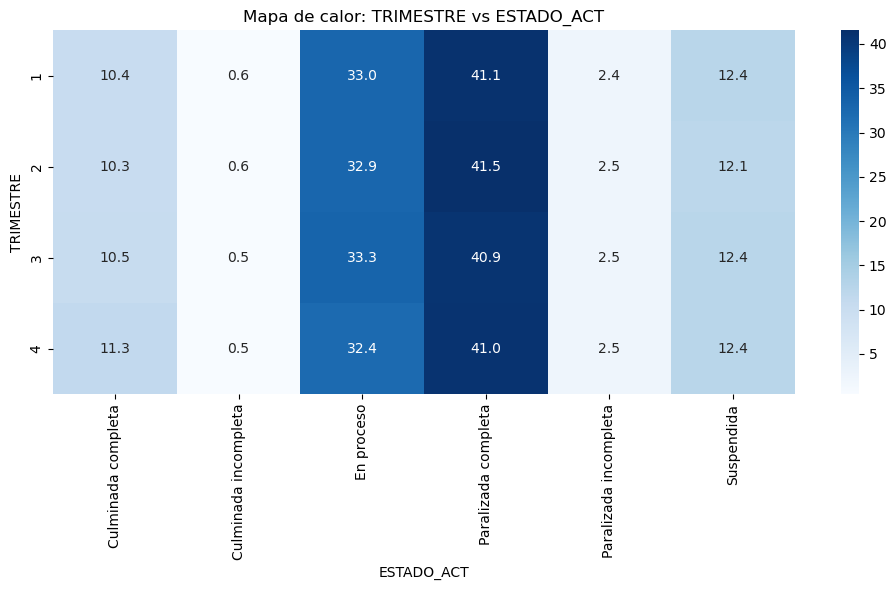


Tabla cruzada: TRIMESTRE vs MOVIMIENTO


MOVIMIENTO,Ampliación de cobertura,Continúa en estado anterior,Obra culminada,Obra nueva,Obra suspendida,Paraliza actividad,Reinicia actividad,Reinicio después de suspensión
TRIMESTRE,,,,,,,,
1,0.17,55.08,11.02,12.17,12.41,6.86,2.27,0.01
2,0.20,54.86,10.94,12.14,12.12,7.50,2.23,0.01
3,0.23,54.96,10.98,11.96,12.35,7.04,2.48,0.01
4,0.13,54.66,11.74,11.68,12.40,7.22,2.15,0.01


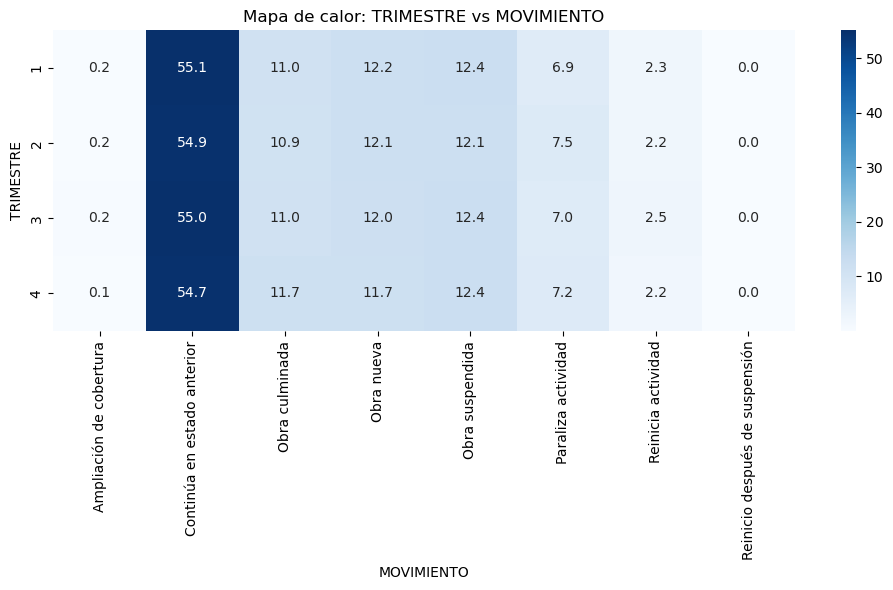


Tabla cruzada: TRIMESTRE vs ESTRATO


ESTRATO,Estrato 1,Estrato 2,Estrato 3,Estrato 4,Estrato 5,Estrato 6
TRIMESTRE,,,,,,
1,15.32,33.79,33.46,10.49,4.24,2.70
2,15.34,33.84,33.41,10.49,4.23,2.68
3,15.17,33.67,33.59,10.55,4.27,2.75
4,15.20,33.70,33.56,10.55,4.26,2.72


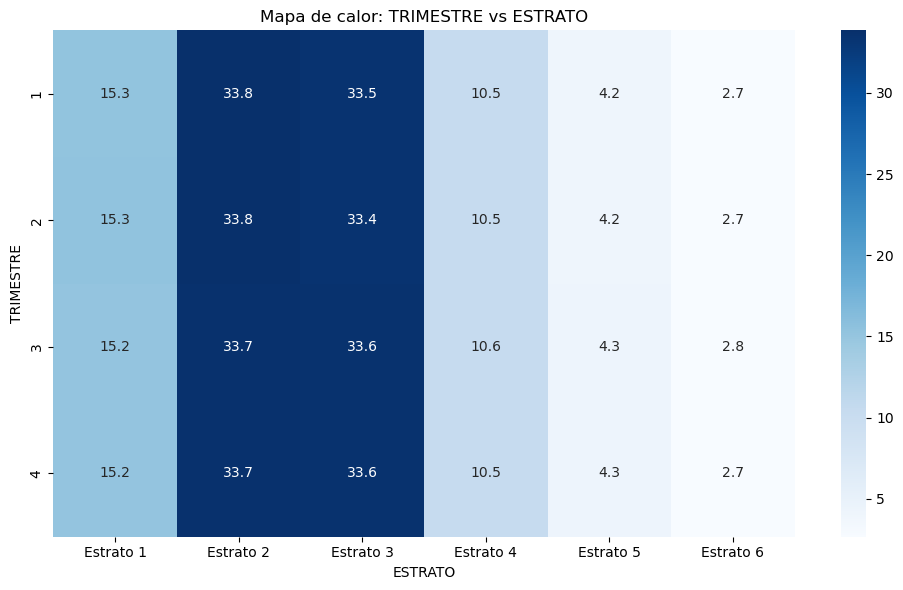


Tabla cruzada: TRIMESTRE vs USO


USO,No venta,Sí venta
TRIMESTRE,,
1,83.74,16.26
2,83.68,16.32
3,83.65,16.35
4,83.60,16.40


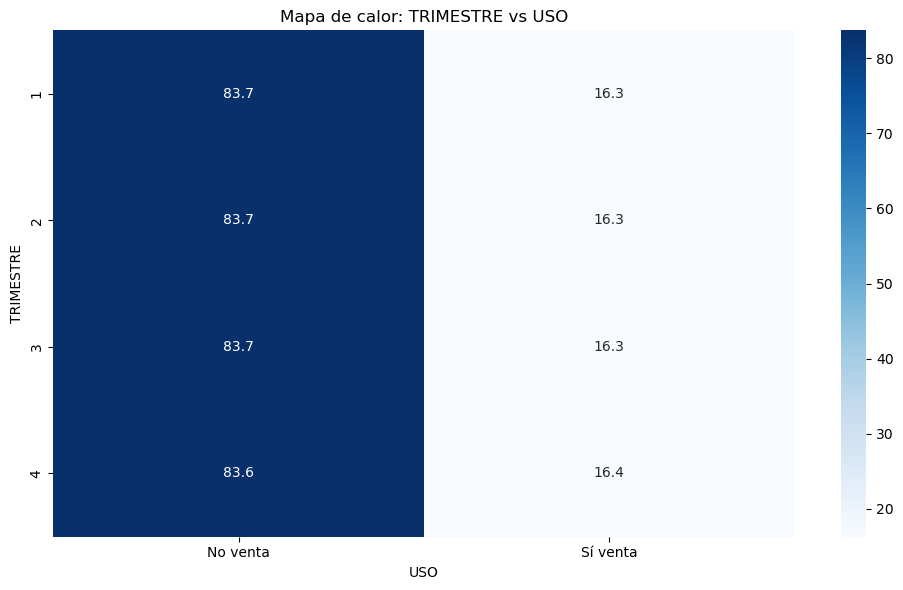


Tabla cruzada: TRIMESTRE vs USO_DOS


USO_DOS,Arrendamiento,Donación,Uso propio
TRIMESTRE,,,
1,22.06,0.36,77.58
2,22.48,0.36,77.15
3,21.13,0.37,78.50
4,21.68,0.35,77.97


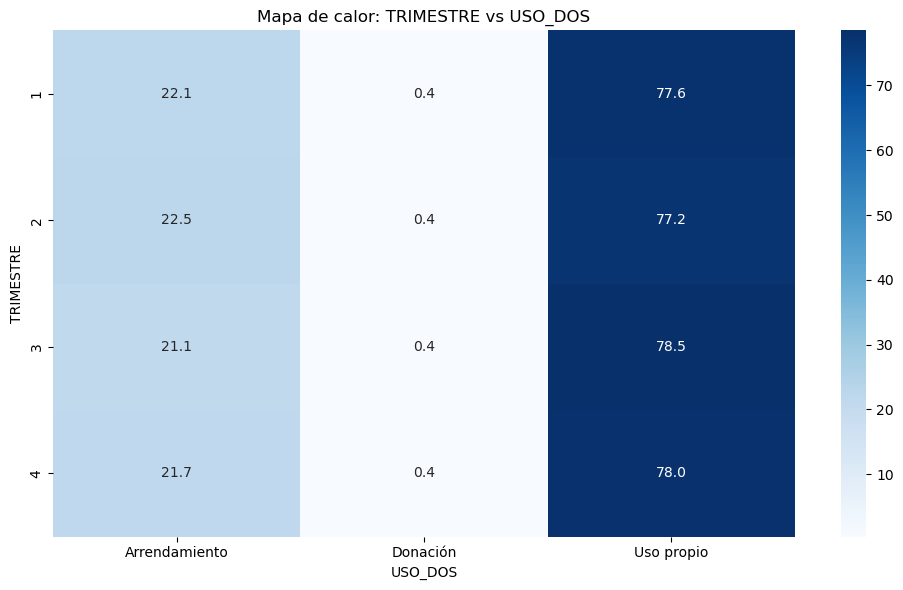


Tabla cruzada: TRIMESTRE vs TIPOVRDEST


TIPOVRDEST,Código 5440 (revisar),No,Sí
TRIMESTRE,,,
1,0.0,31.40,68.60
2,0.0,31.42,68.58
3,0.0,32.22,67.78
4,0.0,31.77,68.23


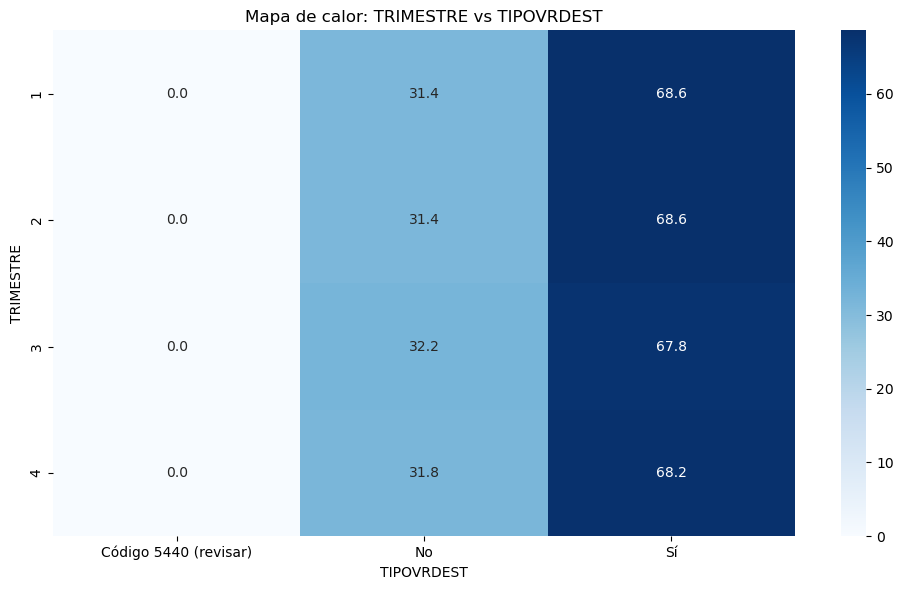


Tabla cruzada: TRIMESTRE vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 4,Rango 5,Rango 6
TRIMESTRE,,,,,,,
1,16.64,8.78,13.98,13.59,12.57,23.36,11.08
2,16.52,8.78,14.07,13.59,12.61,23.32,11.11
3,16.54,8.90,13.86,13.58,12.61,23.35,11.16
4,16.64,8.75,13.84,13.58,12.54,23.49,11.16


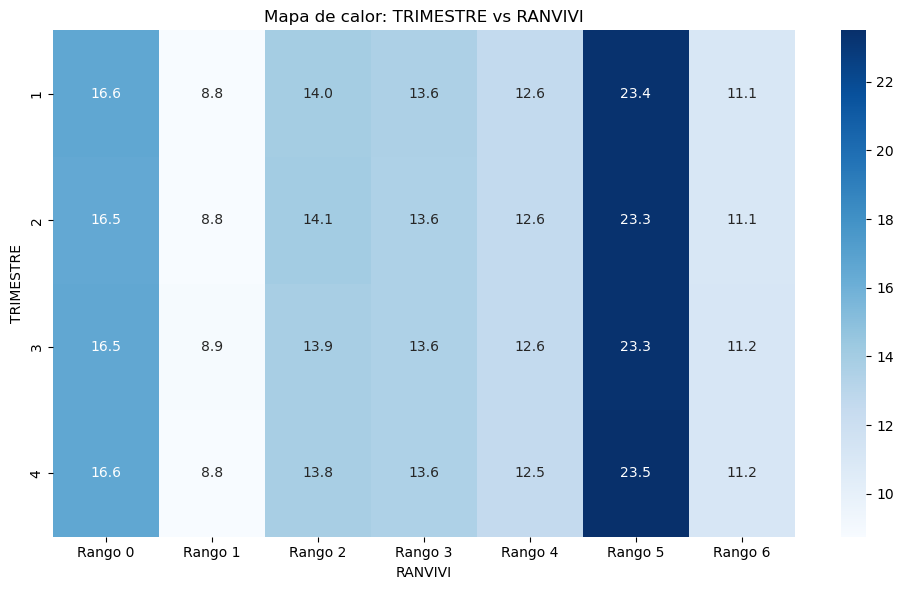


Tabla cruzada: TRIMESTRE vs CAPITULO


CAPITULO,Acabados nivel 1,Acabados nivel 2,Acabados nivel 3,Estructura y cubierta,Excavación y cimentación,Mampostería y pañete
TRIMESTRE,,,,,,
1,21.48,6.68,11.90,25.02,4.83,30.10
2,21.30,6.58,11.76,25.39,4.82,30.15
3,21.52,6.74,11.97,24.95,4.66,30.16
4,21.49,6.71,12.62,24.52,4.47,30.19


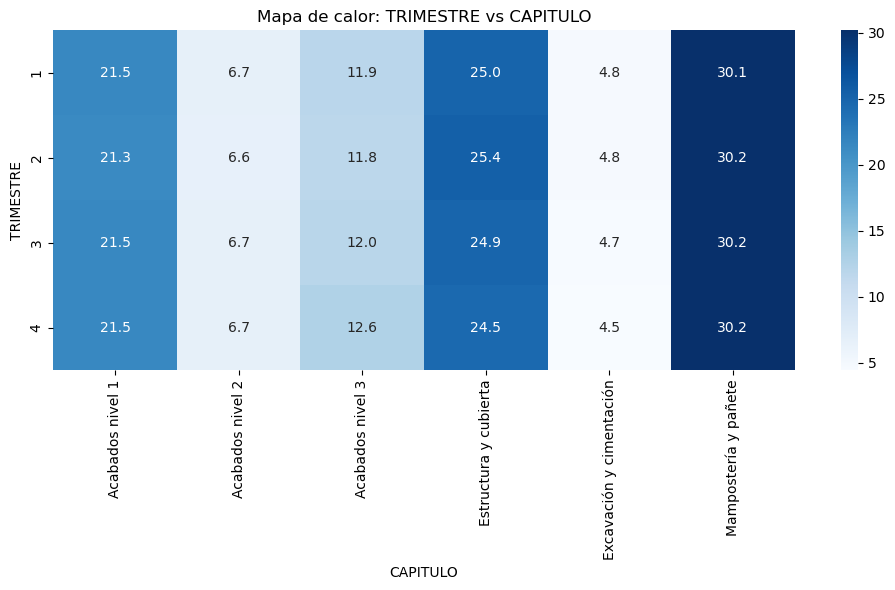


Tabla cruzada: DESTINO2 vs ESTADO_ACT


ESTADO_ACT,Culminada completa,Culminada incompleta,En proceso,Paralizada completa,Paralizada incompleta,Suspendida
DESTINO2,,,,,,
Apartamentos,11.09,0.27,43.14,39.17,1.78,4.56
Bodegas,13.50,0.46,38.46,36.91,3.39,7.28
Casas,9.81,0.76,23.86,44.42,2.71,18.44
Comercio,12.26,0.34,42.98,36.08,3.21,5.13
Educación,12.54,0.20,52.87,28.39,2.40,3.59
Oficinas,12.89,0.21,59.06,22.83,2.91,2.10


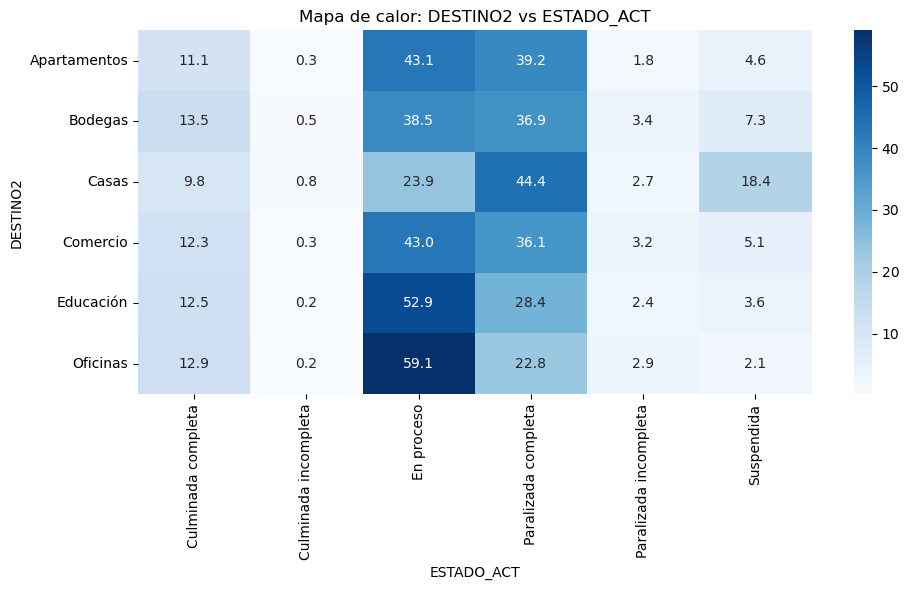


Tabla cruzada: DESTINO2 vs MOVIMIENTO


MOVIMIENTO,Ampliación de cobertura,Continúa en estado anterior,Obra culminada,Obra nueva,Obra suspendida,Paraliza actividad,Reinicia actividad,Reinicio después de suspensión
DESTINO2,,,,,,,,
Apartamentos,0.25,61.74,11.35,12.94,4.56,6.79,2.35,0.02
Bodegas,0.34,53.57,13.96,14.90,7.28,7.45,2.50,0.00
Casas,0.11,50.33,10.57,10.96,18.44,7.50,2.09,0.01
Comercio,0.25,57.92,12.60,13.92,5.13,7.33,2.83,0.02
Educación,0.41,61.69,12.74,13.18,3.59,5.35,3.04,0.01
Oficinas,0.48,63.38,13.10,13.43,2.10,4.94,2.58,0.00


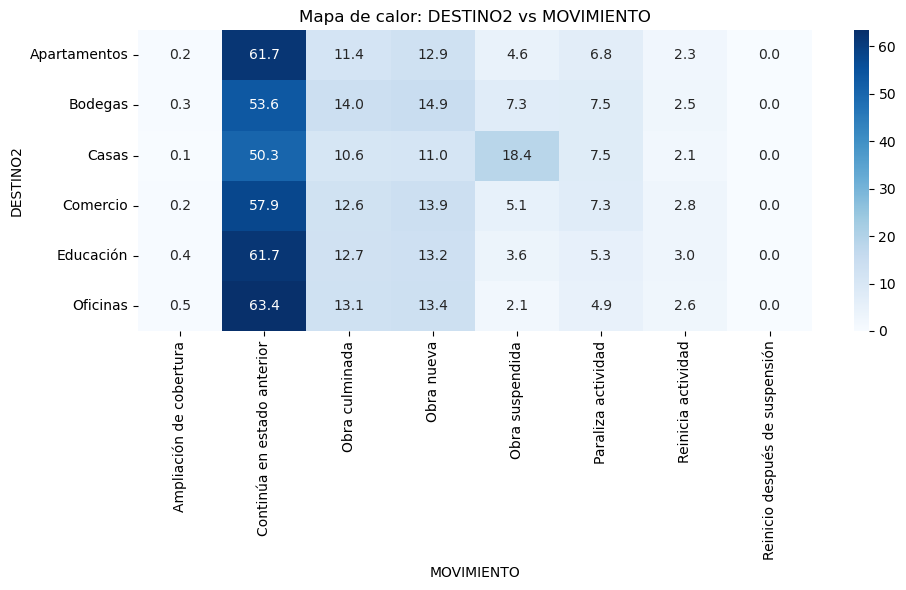


Tabla cruzada: DESTINO2 vs ESTRATO


ESTRATO,Estrato 1,Estrato 2,Estrato 3,Estrato 4,Estrato 5,Estrato 6
DESTINO2,,,,,,
Apartamentos,9.94,29.79,39.78,12.63,4.97,2.90
Bodegas,13.26,29.10,46.36,7.97,1.01,2.31
Casas,19.87,38.83,27.71,8.22,3.20,2.17
Comercio,7.85,23.12,45.96,14.08,6.16,2.82
Educación,8.61,22.84,35.78,18.39,8.57,5.81
Oficinas,2.58,8.03,35.36,22.56,17.77,13.70


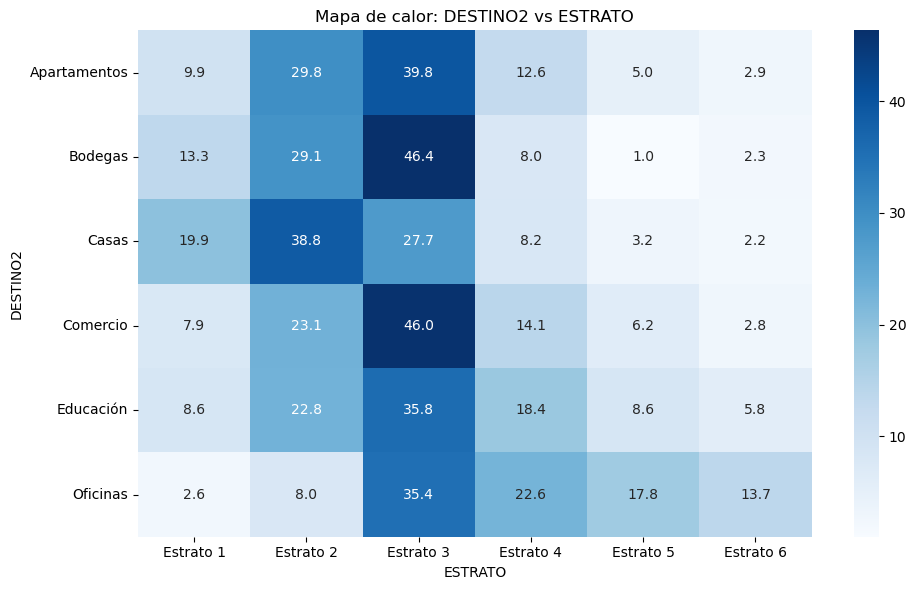


Tabla cruzada: DESTINO2 vs USO


USO,No venta,Sí venta
DESTINO2,,
Apartamentos,63.59,36.41
Bodegas,94.92,5.08
Casas,92.21,7.79
Comercio,82.73,17.27
Educación,100.00,0.00
Oficinas,73.96,26.04


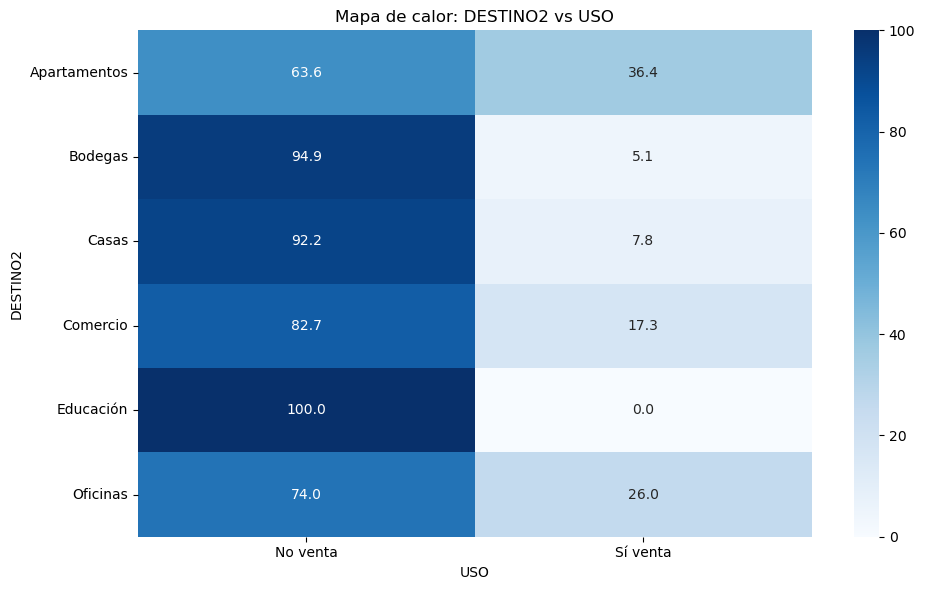


Tabla cruzada: DESTINO2 vs USO_DOS


USO_DOS,Arrendamiento,Donación,Uso propio
DESTINO2,,,
Apartamentos,59.16,1.03,39.82
Bodegas,34.87,0.00,65.12
Casas,4.59,0.16,95.26
Comercio,59.07,0.06,40.87
Educación,1.10,0.57,98.33
Oficinas,39.73,0.09,60.18


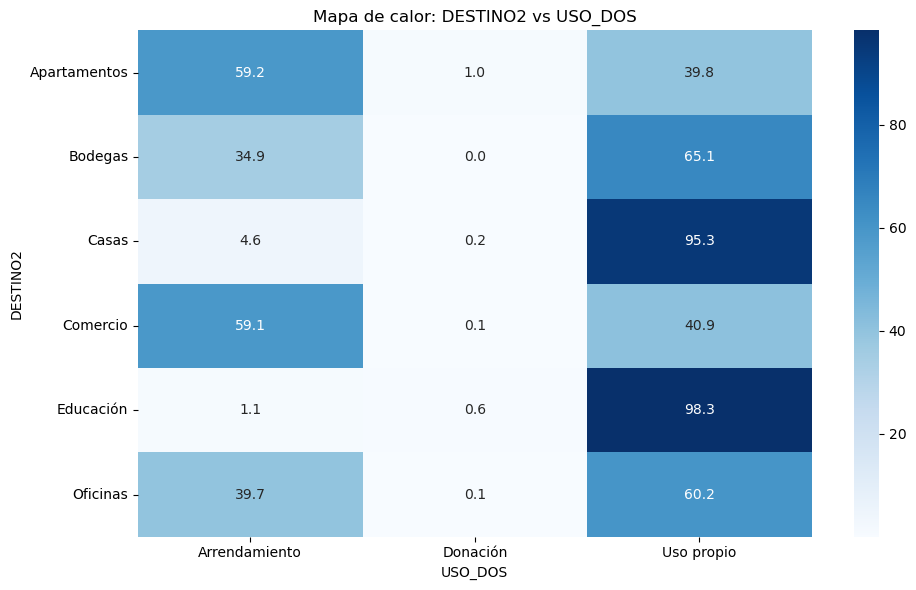


Tabla cruzada: DESTINO2 vs TIPOVRDEST


TIPOVRDEST,Código 5440 (revisar),No,Sí
DESTINO2,,,
Apartamentos,0.0,15.96,84.04
Bodegas,0.0,30.05,69.95
Casas,0.0,42.51,57.49
Comercio,0.0,21.89,78.11
Educación,0.0,18.37,81.63
Oficinas,0.0,17.57,82.43


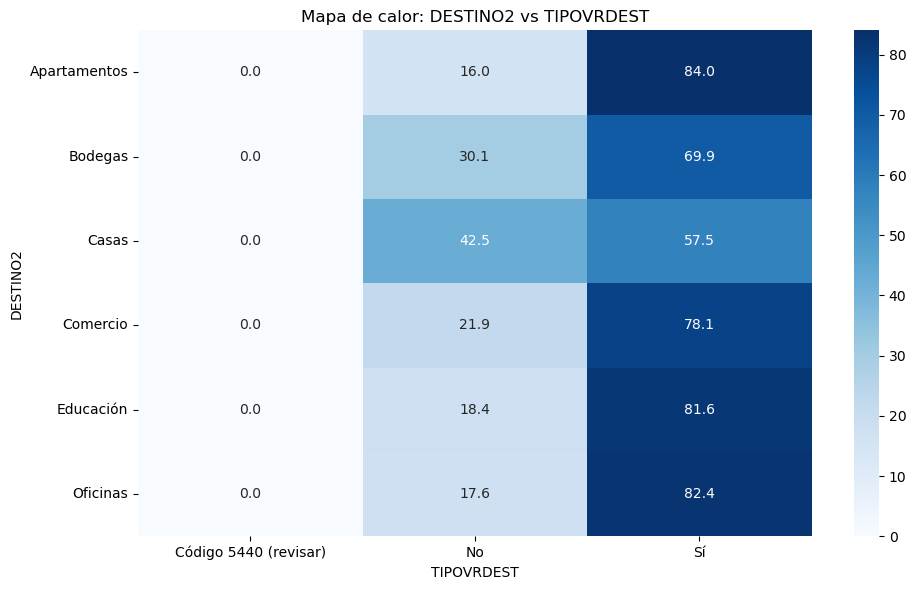


Tabla cruzada: DESTINO2 vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 4,Rango 5,Rango 6
DESTINO2,,,,,,,
Apartamentos,0.28,4.99,16.95,15.97,18.27,32.34,11.21
Bodegas,100.00,0.00,0.00,0.00,0.00,0.00,0.00
Casas,0.58,13.30,16.46,16.33,13.36,25.64,14.32
Comercio,100.00,0.00,0.00,0.00,0.00,0.00,0.00
Educación,100.00,0.00,0.00,0.00,0.00,0.00,0.00
Oficinas,100.00,0.00,0.00,0.00,0.00,0.00,0.00


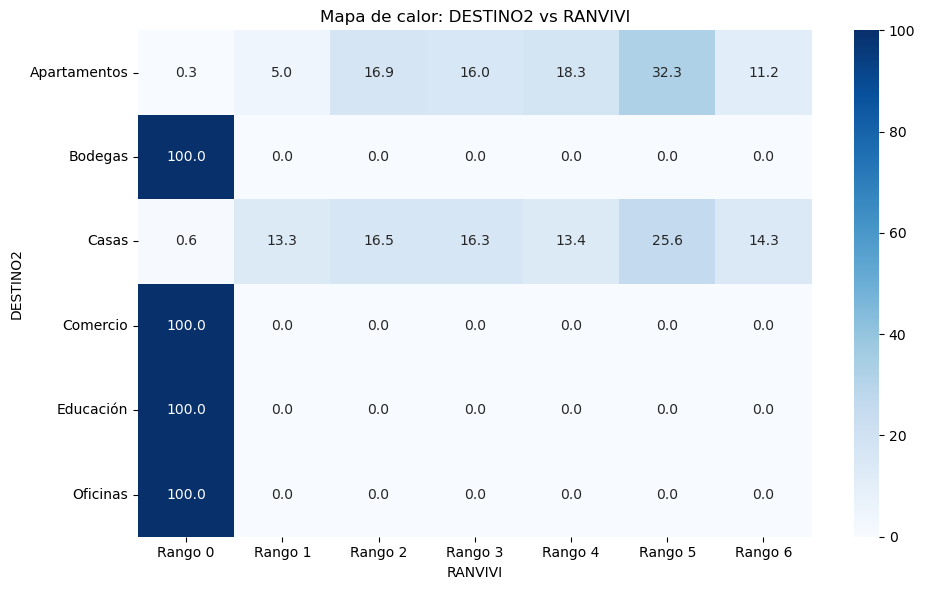


Tabla cruzada: DESTINO2 vs CAPITULO


CAPITULO,Acabados nivel 1,Acabados nivel 2,Acabados nivel 3,Estructura y cubierta,Excavación y cimentación,Mampostería y pañete
DESTINO2,,,,,,
Apartamentos,20.84,6.58,12.41,26.93,6.38,26.85
Bodegas,14.40,6.03,14.89,33.07,5.94,25.67
Casas,22.81,6.25,11.14,22.82,3.12,33.86
Comercio,19.56,9.04,14.38,26.86,6.14,24.01
Educación,17.54,8.50,14.67,29.63,8.77,20.89
Oficinas,15.96,8.49,15.40,29.19,10.71,20.25


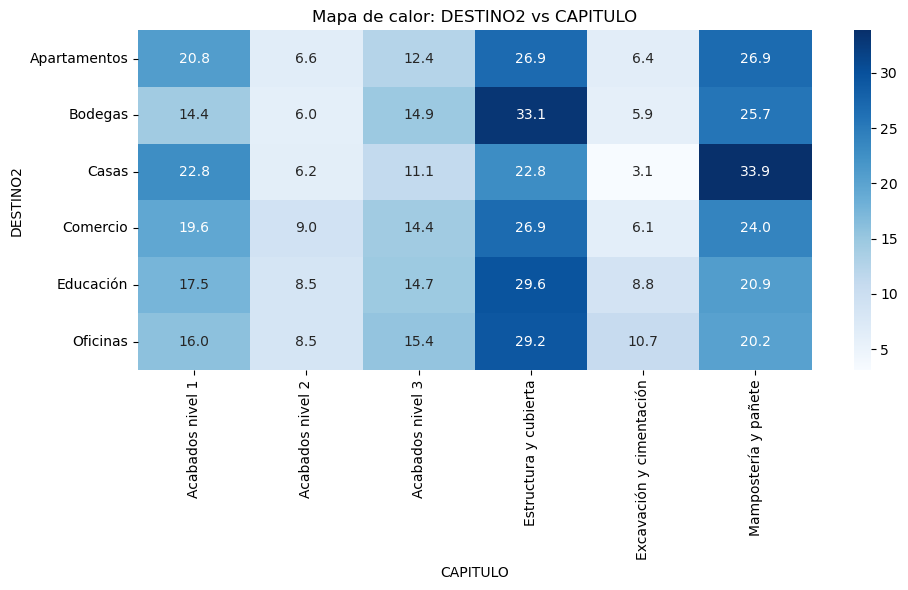


Tabla cruzada: ESTADO_ACT vs MOVIMIENTO


MOVIMIENTO,Ampliación de cobertura,Continúa en estado anterior,Obra culminada,Obra nueva,Obra suspendida,Paraliza actividad,Reinicia actividad,Reinicio después de suspensión
ESTADO_ACT,,,,,,,,
Culminada completa,0.00,0.00,100.0,0.00,0.0,0.0,0.00,0.00
Culminada incompleta,0.00,0.00,100.0,0.00,0.0,0.0,0.00,0.00
En proceso,0.56,57.01,0.0,35.46,0.0,0.0,6.94,0.03
Paralizada completa,0.00,82.60,0.0,0.00,0.0,17.4,0.00,0.00
Paralizada incompleta,0.00,86.96,0.0,13.04,0.0,0.0,0.00,0.00
Suspendida,0.00,0.00,0.0,0.00,100.0,0.0,0.00,0.00


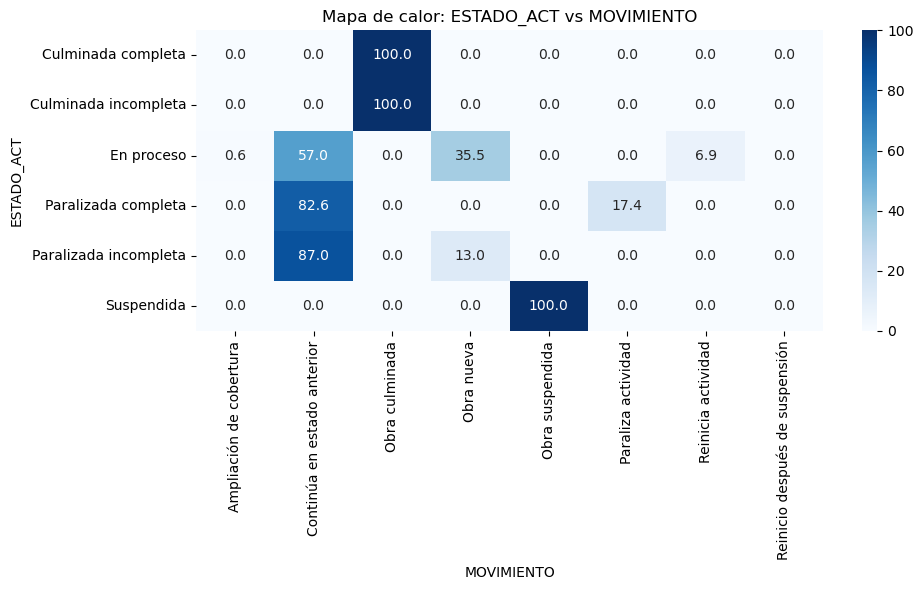


Tabla cruzada: ESTADO_ACT vs ESTRATO


ESTRATO,Estrato 1,Estrato 2,Estrato 3,Estrato 4,Estrato 5,Estrato 6
ESTADO_ACT,,,,,,
Culminada completa,10.49,31.77,37.07,12.59,4.91,3.17
Culminada incompleta,19.90,32.82,38.41,6.80,1.53,0.55
En proceso,7.62,25.07,37.25,16.53,7.90,5.62
Paralizada completa,19.73,40.40,29.83,6.81,2.19,1.05
Paralizada incompleta,4.54,6.27,67.10,15.01,4.76,2.32
Suspendida,26.83,42.03,25.71,4.33,0.85,0.26


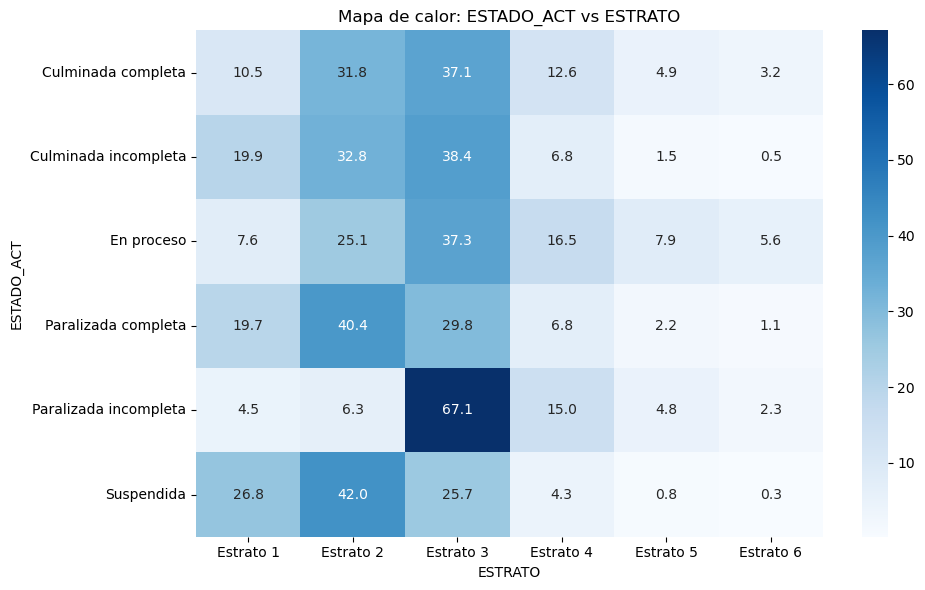


Tabla cruzada: ESTADO_ACT vs USO


USO,No venta,Sí venta
ESTADO_ACT,,
Culminada completa,77.77,22.23
Culminada incompleta,98.21,1.79
En proceso,66.15,33.85
Paralizada completa,93.90,6.10
Paralizada incompleta,95.89,4.11
Suspendida,98.26,1.74


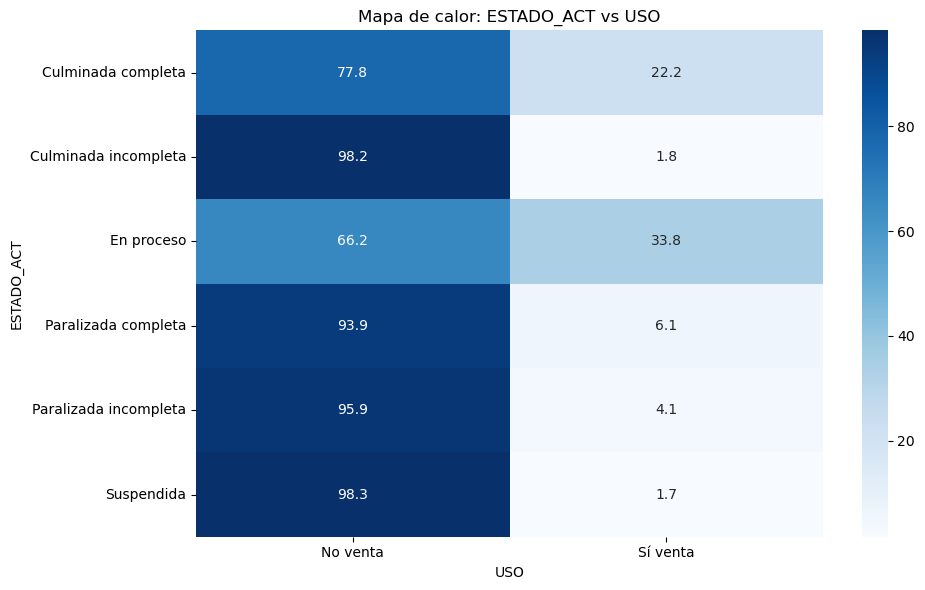


Tabla cruzada: ESTADO_ACT vs USO_DOS


USO_DOS,Arrendamiento,Donación,Uso propio
ESTADO_ACT,,,
Culminada completa,21.70,0.87,77.43
Culminada incompleta,11.94,0.03,88.03
En proceso,26.89,0.84,72.27
Paralizada completa,23.86,0.10,76.04
Paralizada incompleta,20.18,0.16,79.66
Suspendida,7.75,0.04,92.21


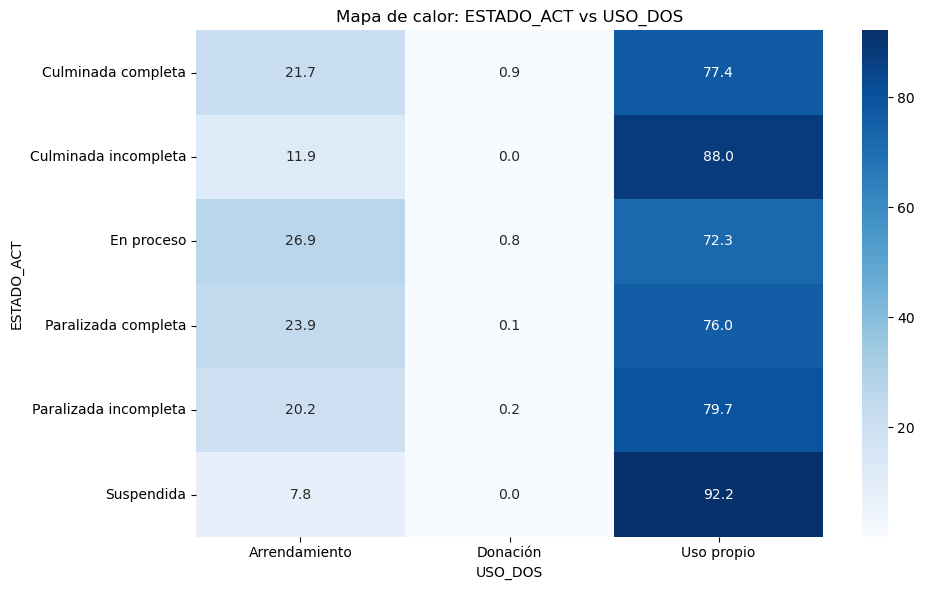


Tabla cruzada: ESTADO_ACT vs TIPOVRDEST


TIPOVRDEST,Código 5440 (revisar),No,Sí
ESTADO_ACT,,,
Culminada completa,0.0,8.04,91.96
Culminada incompleta,0.0,76.41,23.59
En proceso,0.0,4.41,95.59
Paralizada completa,0.0,39.23,60.77
Paralizada incompleta,0.0,70.03,29.97
Suspendida,0.0,90.06,9.94


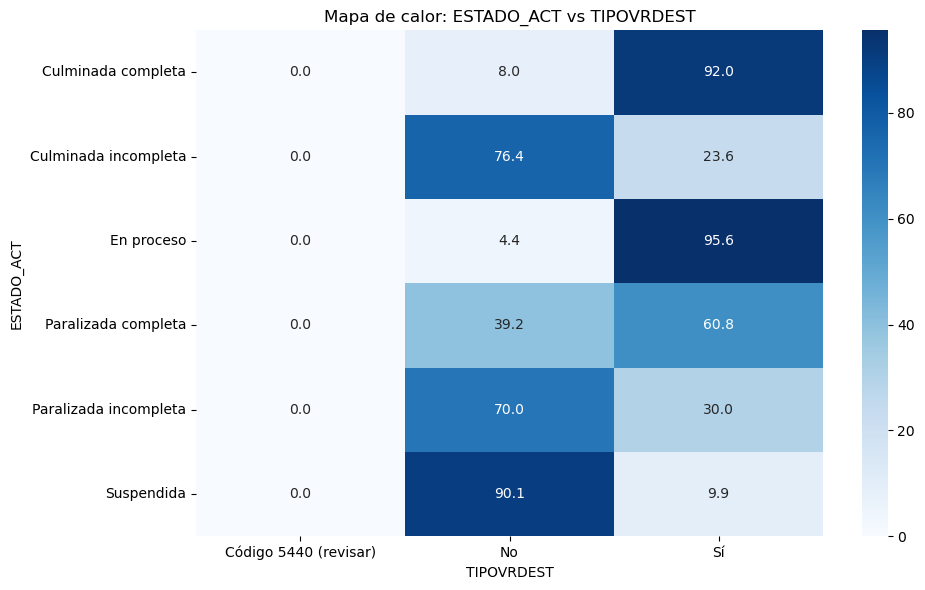


Tabla cruzada: ESTADO_ACT vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 4,Rango 5,Rango 6
ESTADO_ACT,,,,,,,
Culminada completa,19.19,7.20,11.84,11.89,12.66,24.27,12.96
Culminada incompleta,12.79,13.23,14.81,17.93,13.65,21.11,6.47
En proceso,22.71,4.13,8.69,9.10,11.42,25.57,18.37
Paralizada completa,13.07,10.72,17.66,15.45,13.13,22.85,7.12
Paralizada incompleta,28.97,2.80,5.29,8.53,9.89,28.07,16.45
Suspendida,7.61,17.14,18.83,21.46,14.24,17.79,2.93


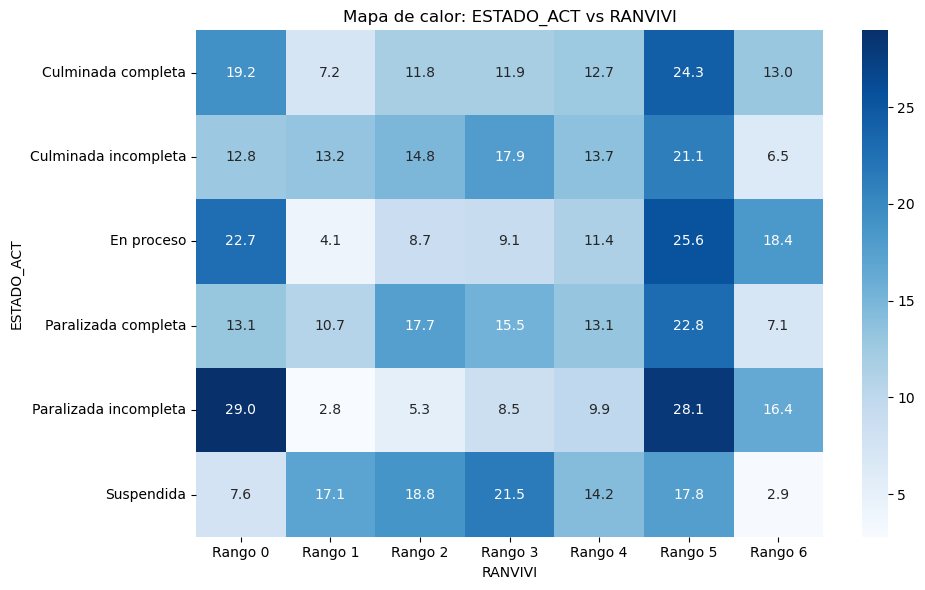


Tabla cruzada: ESTADO_ACT vs CAPITULO


CAPITULO,Acabados nivel 1,Acabados nivel 2,Acabados nivel 3,Estructura y cubierta,Excavación y cimentación,Mampostería y pañete
ESTADO_ACT,,,,,,
Culminada completa,0.00,0.00,100.00,0.00,0.00,0.00
Culminada incompleta,0.00,0.00,100.00,0.00,0.00,0.00
En proceso,17.71,8.15,1.73,39.11,11.15,22.16
Paralizada completa,27.63,7.70,0.72,22.81,1.80,39.34
Paralizada incompleta,15.72,3.48,0.45,41.44,8.48,30.42
Suspendida,31.38,6.04,0.12,13.76,0.61,48.09


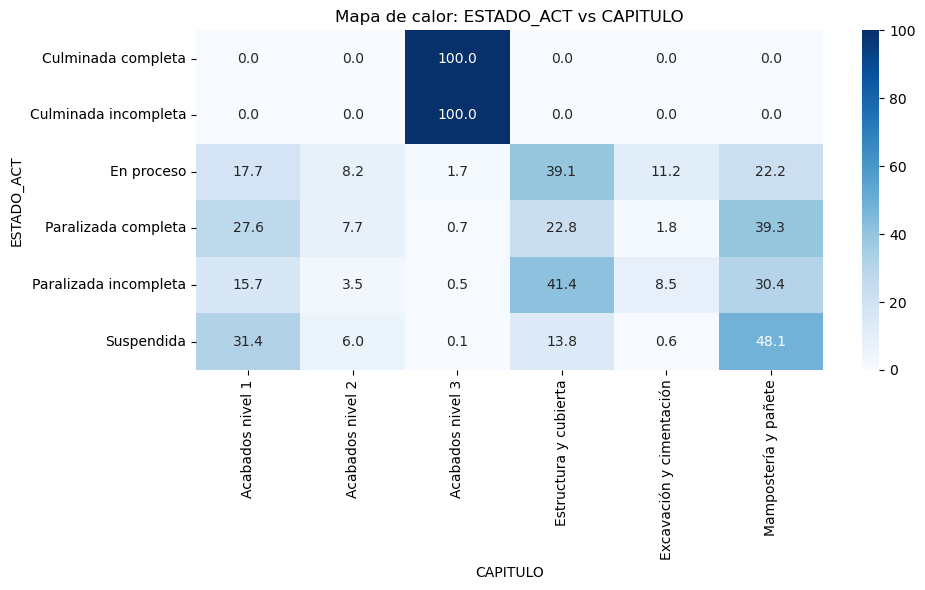


Tabla cruzada: MOVIMIENTO vs ESTRATO


ESTRATO,Estrato 1,Estrato 2,Estrato 3,Estrato 4,Estrato 5,Estrato 6
MOVIMIENTO,,,,,,
Ampliación de cobertura,6.96,26.30,42.63,13.06,5.49,5.56
Continúa en estado anterior,14.39,32.25,33.75,11.34,4.94,3.34
Obra culminada,10.95,31.82,37.14,12.30,4.75,3.04
Obra nueva,11.66,31.99,36.85,12.01,4.65,2.84
Obra suspendida,26.83,42.03,25.71,4.33,0.85,0.26
Paraliza actividad,16.31,37.94,32.68,8.73,3.01,1.33
Reinicia actividad,11.18,31.36,36.37,13.05,5.40,2.63
Reinicio después de suspensión,17.91,33.61,34.71,11.29,1.93,0.55


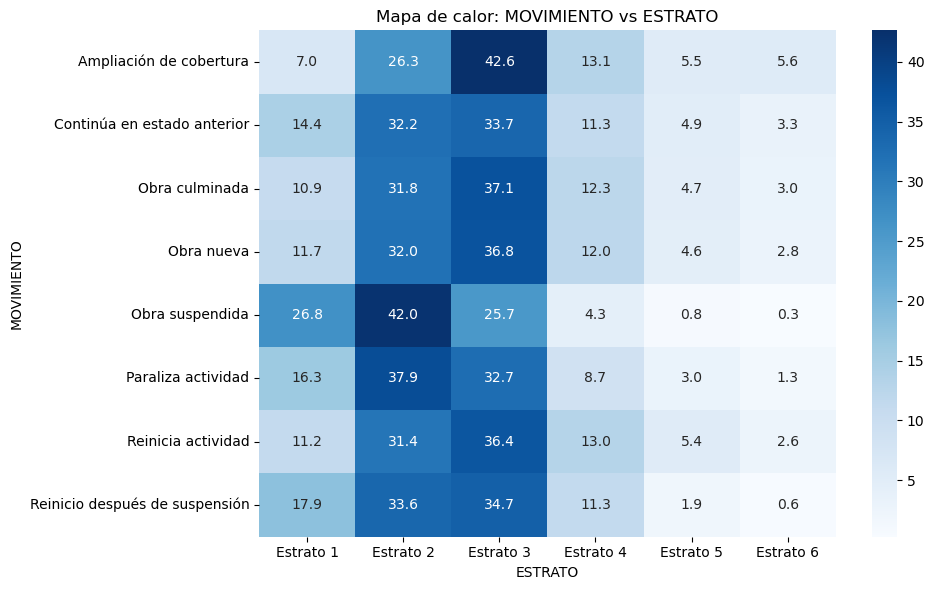


Tabla cruzada: MOVIMIENTO vs USO


USO,No venta,Sí venta
MOVIMIENTO,,
Ampliación de cobertura,65.74,34.26
Continúa en estado anterior,81.20,18.80
Obra culminada,78.77,21.23
Obra nueva,79.72,20.28
Obra suspendida,98.26,1.74
Paraliza actividad,91.81,8.19
Reinicia actividad,84.86,15.14
Reinicio después de suspensión,96.42,3.58


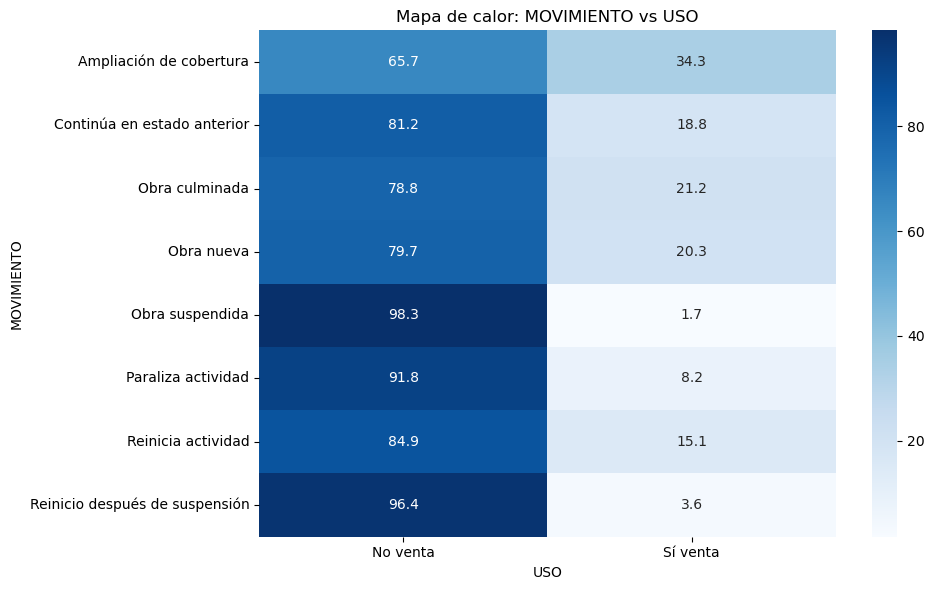


Tabla cruzada: MOVIMIENTO vs USO_DOS


USO_DOS,Arrendamiento,Donación,Uso propio
MOVIMIENTO,,,
Ampliación de cobertura,22.46,1.11,76.43
Continúa en estado anterior,24.62,0.32,75.07
Obra culminada,21.10,0.82,78.08
Obra nueva,24.85,0.74,74.42
Obra suspendida,7.75,0.04,92.21
Paraliza actividad,25.35,0.14,74.51
Reinicia actividad,26.60,0.28,73.12
Reinicio después de suspensión,50.00,0.00,50.00


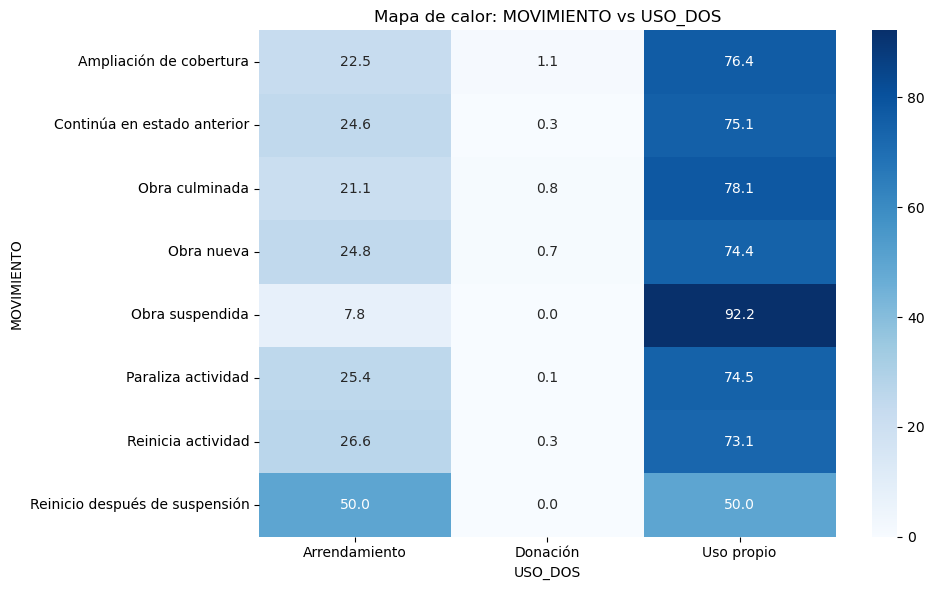


Tabla cruzada: MOVIMIENTO vs TIPOVRDEST


TIPOVRDEST,Código 5440 (revisar),No,Sí
MOVIMIENTO,,,
Ampliación de cobertura,0.0,10.72,89.28
Continúa en estado anterior,0.0,28.78,71.22
Obra culminada,0.0,11.39,88.61
Obra nueva,0.0,7.73,92.27
Obra suspendida,0.0,90.06,9.94
Paraliza actividad,0.0,34.54,65.46
Reinicia actividad,0.0,5.11,94.89
Reinicio después de suspensión,0.0,2.75,97.25


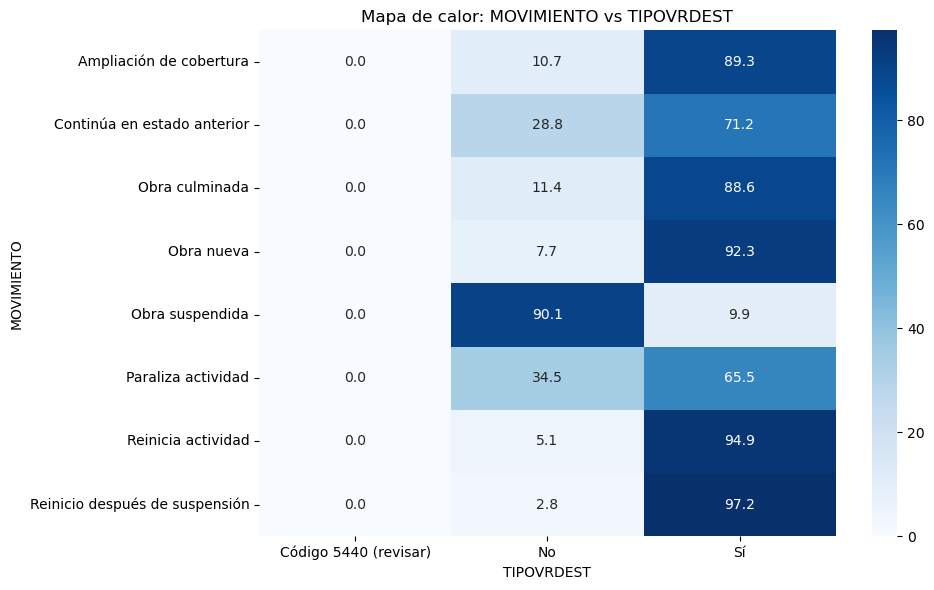


Tabla cruzada: MOVIMIENTO vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 4,Rango 5,Rango 6
MOVIMIENTO,,,,,,,
Ampliación de cobertura,28.88,2.89,5.72,9.14,11.88,22.79,18.71
Continúa en estado anterior,17.70,7.71,13.47,12.47,12.14,24.01,12.50
Obra culminada,18.88,7.49,11.98,12.19,12.71,24.11,12.65
Obra nueva,18.75,7.07,12.61,12.15,12.72,24.20,12.50
Obra suspendida,7.61,17.14,18.83,21.46,14.24,17.79,2.93
Paraliza actividad,15.04,8.85,15.55,14.03,12.91,24.46,9.17
Reinicia actividad,19.94,5.68,10.68,11.09,11.99,27.26,13.37
Reinicio después de suspensión,13.22,5.51,24.24,15.43,15.15,19.83,6.61


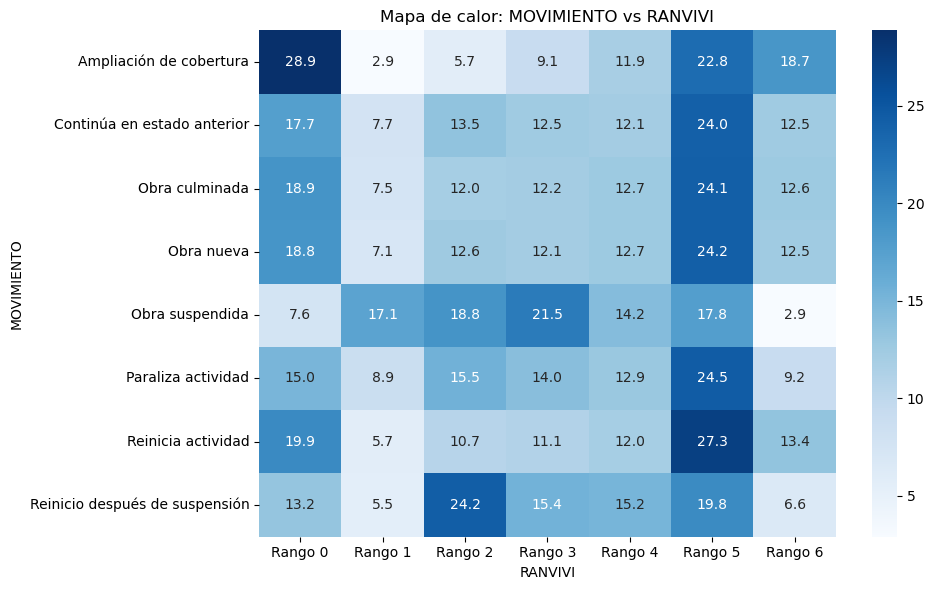


Tabla cruzada: MOVIMIENTO vs CAPITULO


CAPITULO,Acabados nivel 1,Acabados nivel 2,Acabados nivel 3,Estructura y cubierta,Excavación y cimentación,Mampostería y pañete
MOVIMIENTO,,,,,,
Ampliación de cobertura,4.64,1.03,0.15,56.86,10.25,27.07
Continúa en estado anterior,27.45,9.38,1.40,24.20,2.58,34.99
Obra culminada,0.00,0.00,100.00,0.00,0.00,0.00
Obra nueva,0.75,0.10,0.01,61.42,24.55,13.16
Obra suspendida,31.38,6.04,0.12,13.76,0.61,48.09
Paraliza actividad,23.10,7.23,0.94,29.06,2.89,36.78
Reinicia actividad,33.37,11.00,1.64,19.44,1.53,33.02
Reinicio después de suspensión,20.66,3.31,0.00,31.40,0.28,44.35


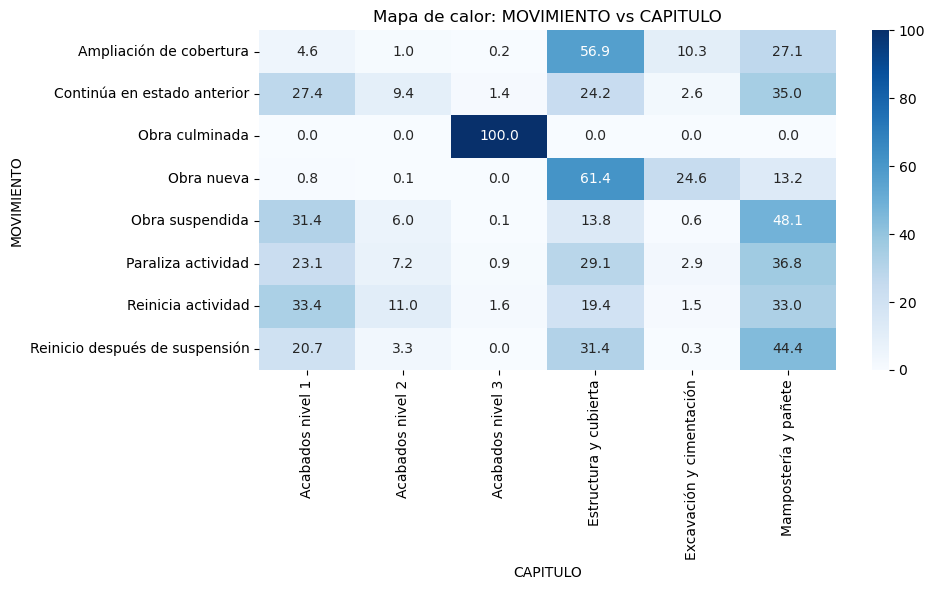


Tabla cruzada: ESTRATO vs USO


USO,No venta,Sí venta
ESTRATO,,
Estrato 1,97.25,2.75
Estrato 2,90.82,9.18
Estrato 3,80.93,19.07
Estrato 4,67.12,32.88
Estrato 5,59.27,40.73
Estrato 6,54.55,45.45


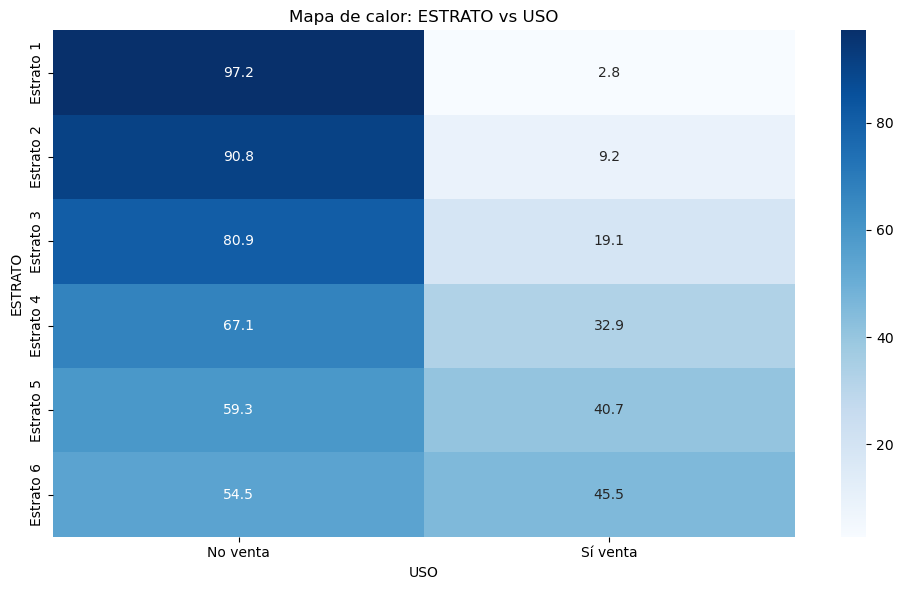


Tabla cruzada: ESTRATO vs USO_DOS


USO_DOS,Arrendamiento,Donación,Uso propio
ESTRATO,,,
Estrato 1,13.74,0.86,85.41
Estrato 2,20.33,0.46,79.21
Estrato 3,28.52,0.11,71.37
Estrato 4,23.22,0.03,76.75
Estrato 5,19.29,0.00,80.71
Estrato 6,11.87,0.02,88.11


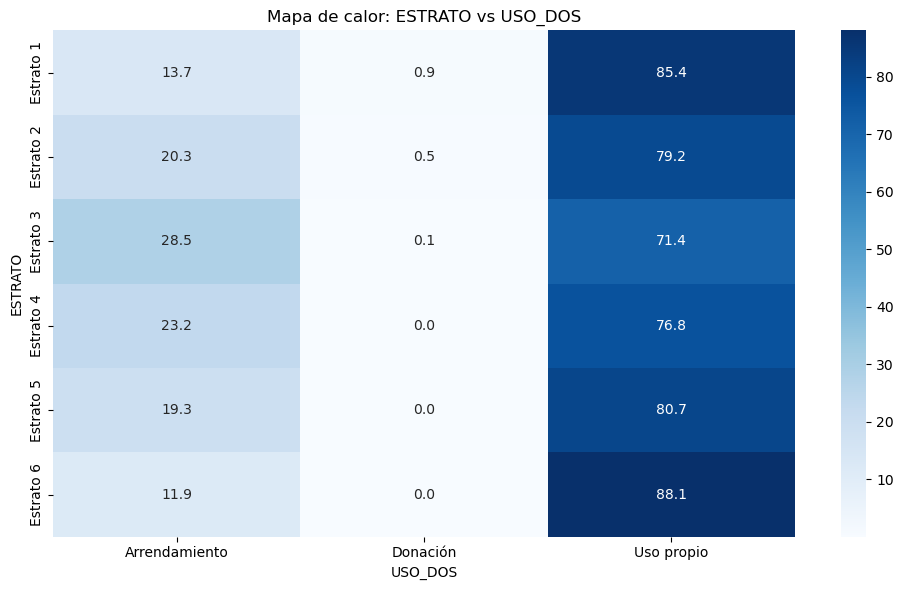


Tabla cruzada: ESTRATO vs TIPOVRDEST


TIPOVRDEST,Código 5440 (revisar),No,Sí
ESTRATO,,,
Estrato 1,0.0,42.91,57.09
Estrato 2,0.0,36.19,63.81
Estrato 3,0.0,28.77,71.23
Estrato 4,0.0,21.82,78.18
Estrato 5,0.0,15.28,84.72
Estrato 6,0.0,12.86,87.14


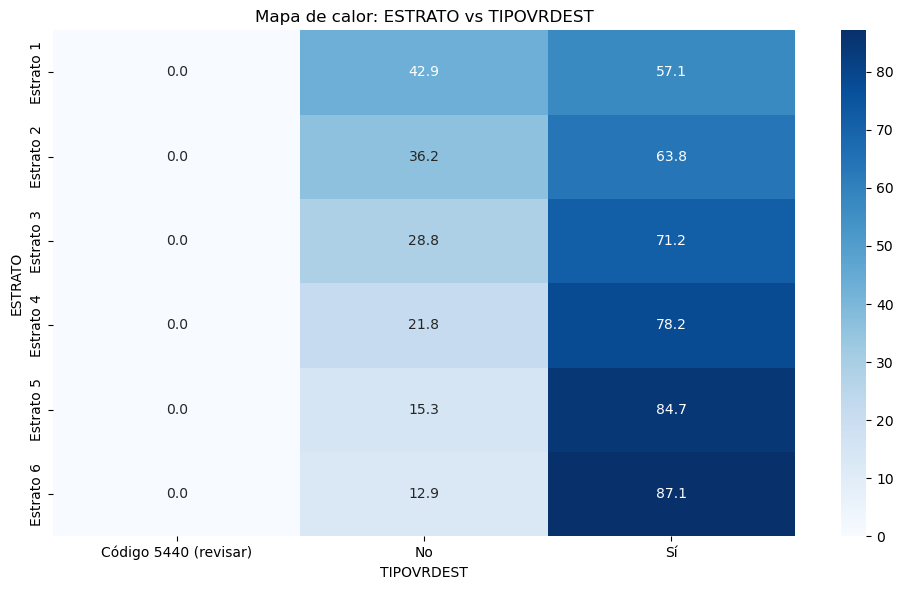


Tabla cruzada: ESTRATO vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 4,Rango 5,Rango 6
ESTRATO,,,,,,,
Estrato 1,9.63,22.90,28.36,19.88,9.93,8.85,0.45
Estrato 2,11.33,12.00,20.99,19.05,15.74,18.66,2.24
Estrato 3,21.16,3.51,7.05,11.25,15.03,33.45,8.55
Estrato 4,23.00,0.63,1.38,2.94,6.24,35.27,30.54
Estrato 5,25.63,0.33,0.27,0.95,1.28,16.70,54.85
Estrato 6,25.64,0.06,0.08,0.10,0.19,4.03,69.91


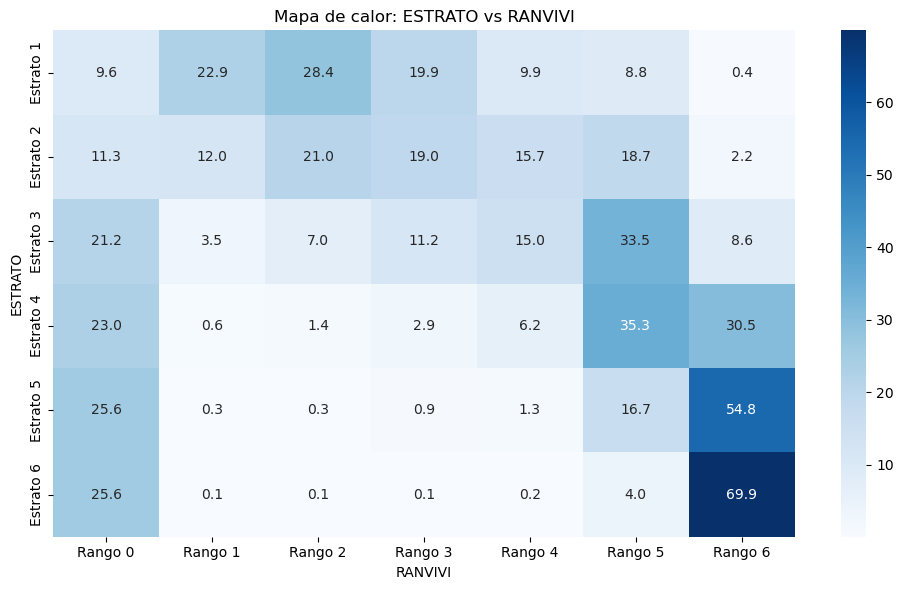


Tabla cruzada: ESTRATO vs CAPITULO


CAPITULO,Acabados nivel 1,Acabados nivel 2,Acabados nivel 3,Estructura y cubierta,Excavación y cimentación,Mampostería y pañete
ESTRATO,,,,,,
Estrato 1,22.53,3.62,8.23,22.55,2.81,40.26
Estrato 2,21.72,5.48,11.05,24.24,3.26,34.25
Estrato 3,21.27,7.54,13.28,26.29,4.92,26.70
Estrato 4,20.98,9.79,14.81,25.41,7.82,21.18
Estrato 5,19.54,10.46,14.89,26.98,9.37,18.76
Estrato 6,18.92,10.15,15.96,26.59,10.89,17.49


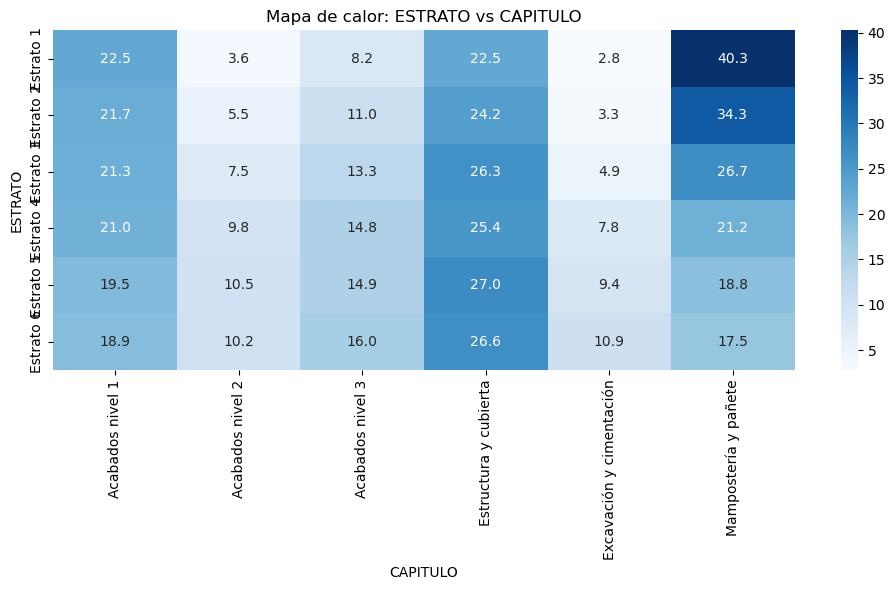


Tabla cruzada: USO vs USO_DOS


USO_DOS,Arrendamiento,Donación,Uso propio
USO,,,
No venta,21.84,0.36,77.8
Sí venta,100.00,0.00,0.0


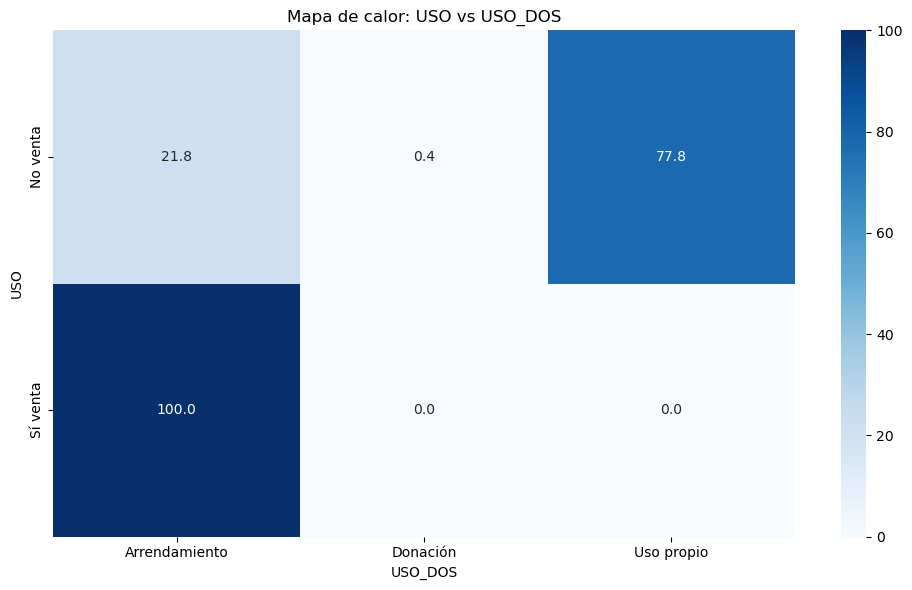


Tabla cruzada: USO vs TIPOVRDEST


TIPOVRDEST,Código 5440 (revisar),No,Sí
USO,,,
No venta,0.0,36.12,63.88
Sí venta,0.0,9.06,90.94


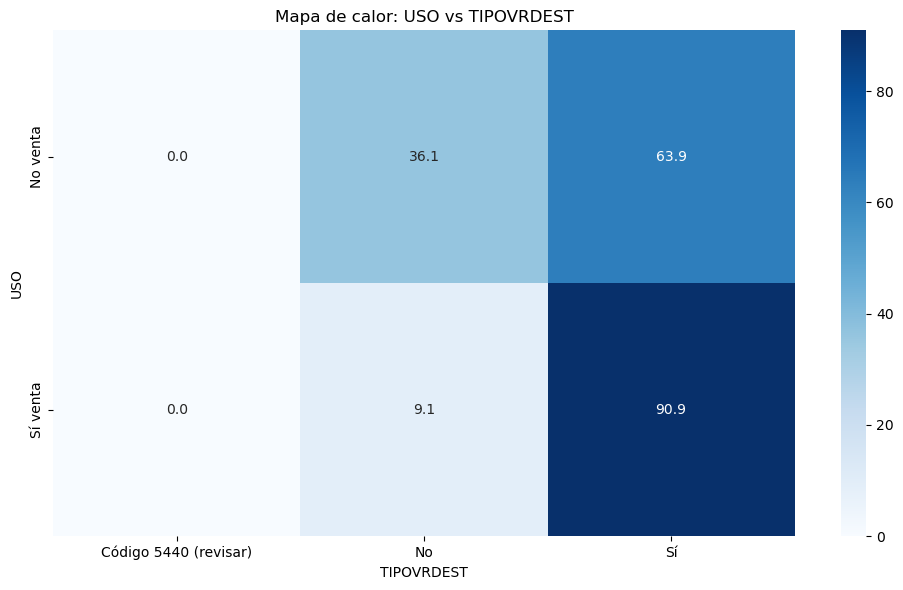


Tabla cruzada: USO vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 4,Rango 5,Rango 6
USO,,,,,,,
No venta,17.77,10.23,15.45,14.6,12.07,21.53,8.34
Sí venta,10.48,1.51,6.15,8.4,15.19,32.87,25.40


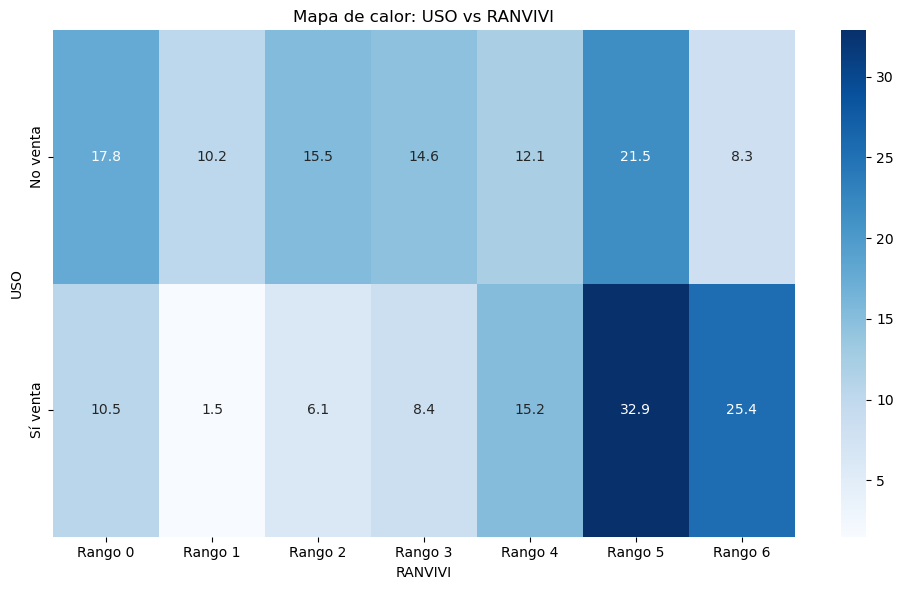


Tabla cruzada: USO vs CAPITULO


CAPITULO,Acabados nivel 1,Acabados nivel 2,Acabados nivel 3,Estructura y cubierta,Excavación y cimentación,Mampostería y pañete
USO,,,,,,
No venta,22.37,6.18,11.14,24.23,3.08,33.00
Sí venta,16.74,9.20,16.79,28.75,12.95,15.56


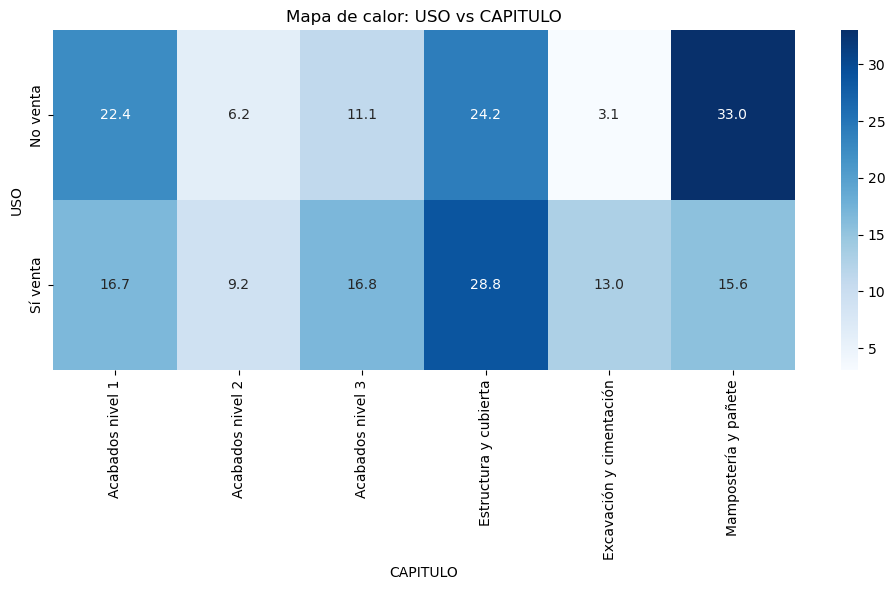


Tabla cruzada: USO_DOS vs TIPOVRDEST


TIPOVRDEST,Código 5440 (revisar),No,Sí
USO_DOS,,,
<NA>,0.0,14.63,85.37
Arrendamiento,0.0,18.48,81.52
Donación,0.0,9.71,90.29
Uso propio,0.0,41.00,59.00


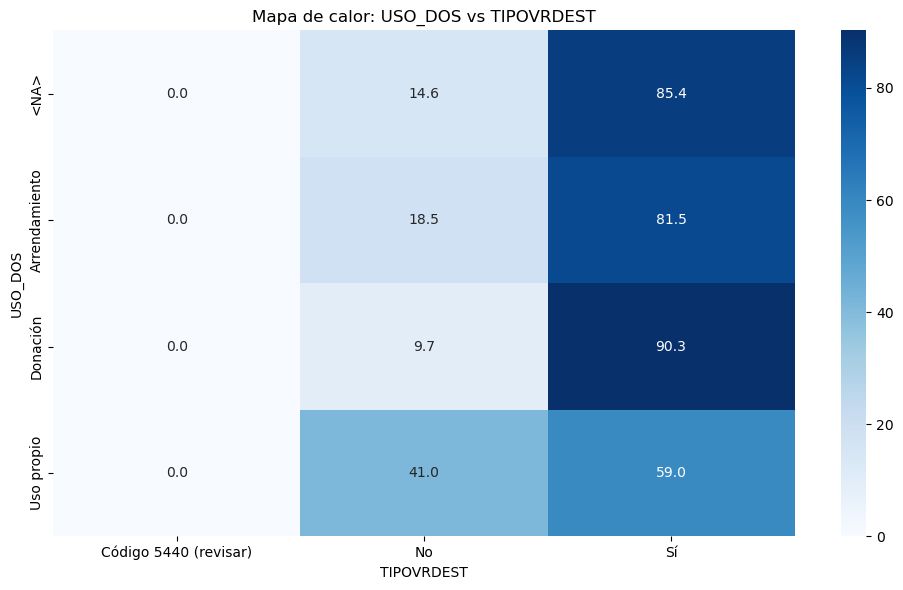


Tabla cruzada: USO_DOS vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 4,Rango 5,Rango 6
USO_DOS,,,,,,,
<NA>,11.39,4.37,7.26,9.27,14.52,30.91,22.28
Arrendamiento,27.35,5.95,16.45,13.87,13.44,20.44,2.50
Donación,10.76,13.96,57.83,12.85,3.11,1.27,0.23
Uso propio,15.28,11.00,15.17,14.89,11.77,21.89,10.00


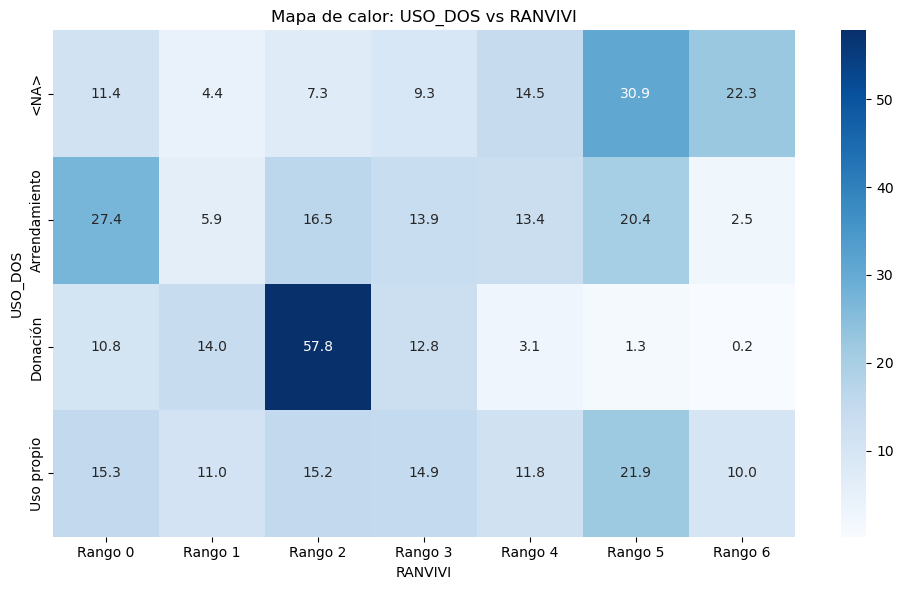


Tabla cruzada: USO_DOS vs CAPITULO


CAPITULO,Acabados nivel 1,Acabados nivel 2,Acabados nivel 3,Estructura y cubierta,Excavación y cimentación,Mampostería y pañete
USO_DOS,,,,,,
<NA>,17.94,9.21,16.15,27.33,11.03,18.34
Arrendamiento,22.04,6.34,10.41,27.07,3.21,30.92
Donación,11.93,8.06,26.23,25.46,13.83,14.47
Uso propio,22.45,5.95,11.14,23.62,3.03,33.80


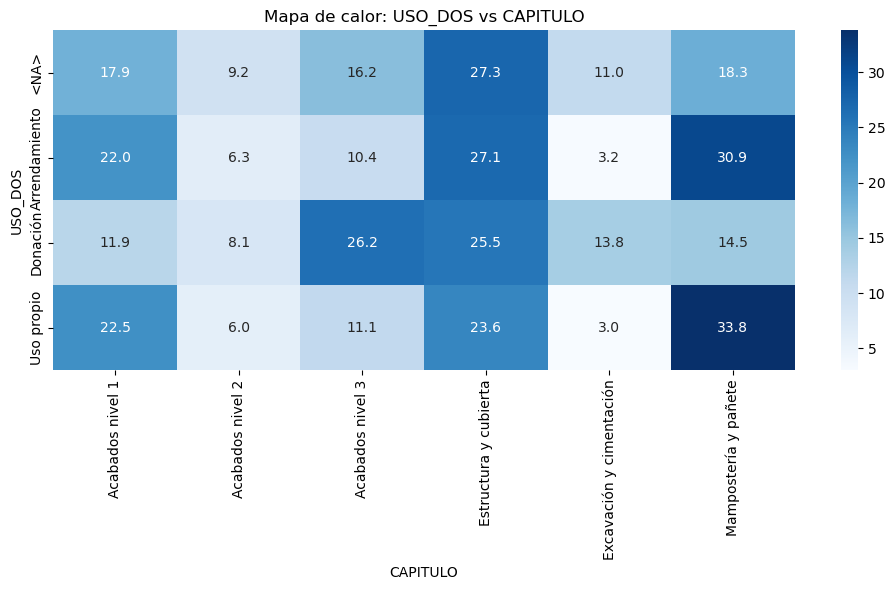


Tabla cruzada: TIPOVRDEST vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 4,Rango 5,Rango 6
TIPOVRDEST,,,,,,,
Código 5440 (revisar),100.00,0.00,0.00,0.00,0.00,0.00,0.00
No,12.10,13.17,15.19,17.82,13.01,21.68,7.04
Sí,18.68,6.77,13.35,11.61,12.38,24.18,13.03


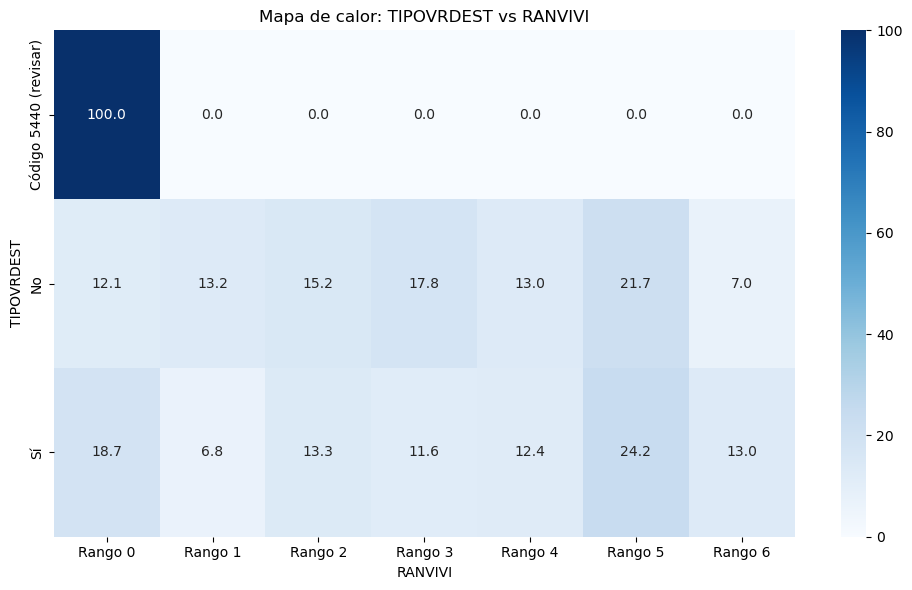


Tabla cruzada: TIPOVRDEST vs CAPITULO


CAPITULO,Acabados nivel 1,Acabados nivel 2,Acabados nivel 3,Estructura y cubierta,Excavación y cimentación,Mampostería y pañete
TIPOVRDEST,,,,,,
Código 5440 (revisar),0.00,0.00,0.00,0.00,100.00,0.00
No,25.33,6.63,4.67,21.50,2.28,39.60
Sí,19.65,6.70,15.49,26.58,5.82,25.77


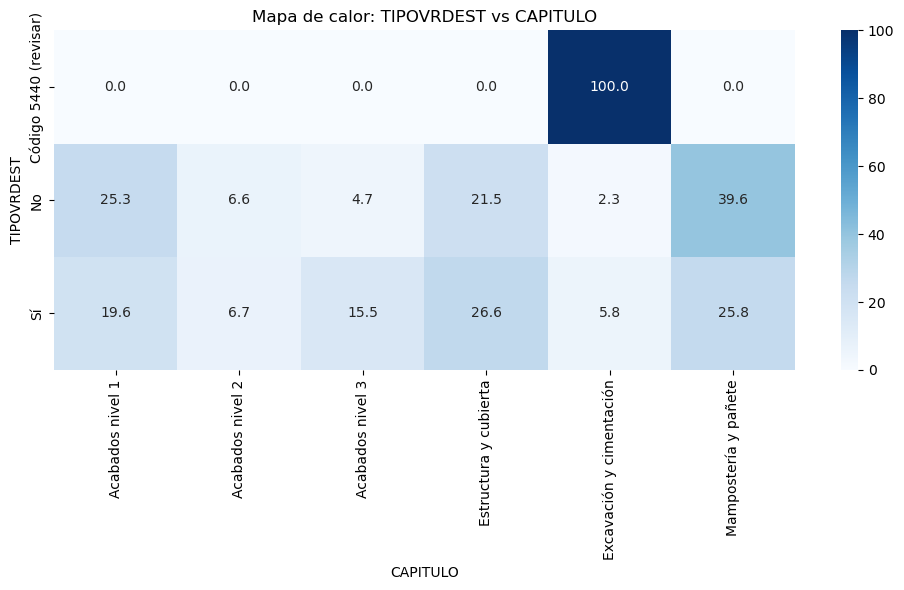


Tabla cruzada: RANVIVI vs CAPITULO


CAPITULO,Acabados nivel 1,Acabados nivel 2,Acabados nivel 3,Estructura y cubierta,Excavación y cimentación,Mampostería y pañete
RANVIVI,,,,,,
<NA>,4.27,0.18,1.34,56.71,22.09,15.40
Rango 0,18.58,8.38,14.44,28.21,6.85,23.54
Rango 1,22.60,4.76,9.92,20.40,1.92,40.40
Rango 2,23.62,4.75,9.97,20.57,2.77,38.31
Rango 3,23.94,5.67,10.47,21.00,3.08,35.85
Rango 4,22.49,6.41,11.85,24.20,4.13,30.91
Rango 5,20.99,7.20,12.48,27.48,4.78,27.06
Rango 6,19.57,8.77,14.59,28.34,7.73,21.00


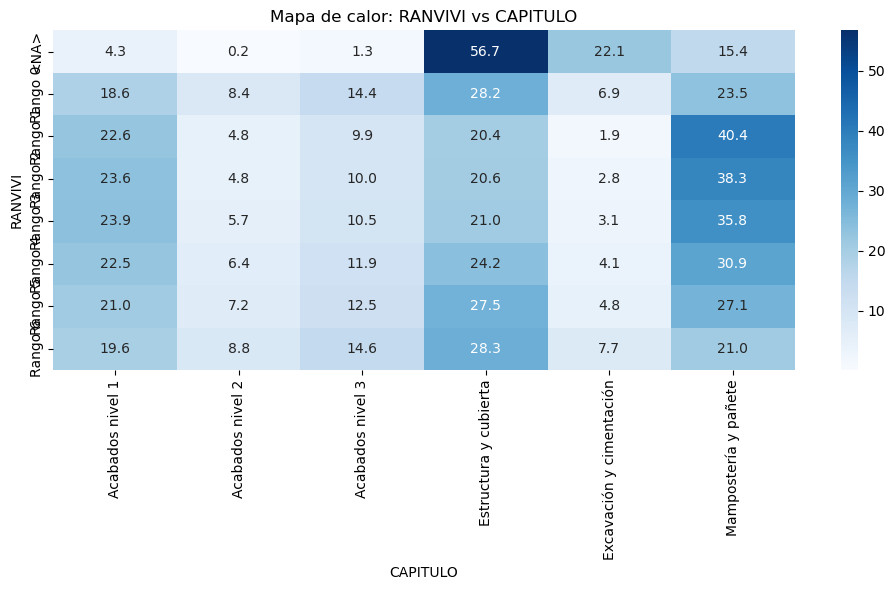

In [55]:
#Se eliminan estas dos variables dado que para el análisis cruzado municipios no es fácil de gráficas se reemplaza inicialmente con departamente y 
# cobertura no aporta información para análisis relevente

categoricas2 = categoricas.drop(columns=["Departamento","Municipio"])

# Cruzar todas las variables categóricas entre sí
for var1, var2 in combinations(categoricas2.columns, 2):

    print(f"\nTabla cruzada: {var1} vs {var2}")

    # Tabla cruzada en porcentajes por fila
    tabla = pd.crosstab(
        df_tratado2[var1],
        df_tratado2[var2],
        normalize="index",
        dropna=False
    ) * 100

    # Mostrar tabla
    display(tabla.round(2))

    # Mapa de calor
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        tabla,
        annot=True,
        fmt=".1f",
        cmap="Blues"
    )
    plt.title(f"Mapa de calor: {var1} vs {var2}")
    plt.xlabel(var2)
    plt.ylabel(var1)
    plt.tight_layout()
    plt.show()


Tabla cruzada: Departamento vs TRIMESTRE


TRIMESTRE,1,2,3,4
Departamento,,,,
Antioquia,25.04,25.25,24.82,24.89
Atlántico,25.01,25.31,24.81,24.87
"Bogotá, D.C.",24.81,25.10,25.04,25.05
Bolívar,25.21,25.45,24.63,24.71
Boyacá,25.79,26.20,23.09,24.92
Caldas,24.94,25.25,24.93,24.88
Caquetá,25.34,25.62,23.82,25.22
Casanare,25.77,26.55,22.95,24.74
Cauca,25.03,25.27,24.77,24.93


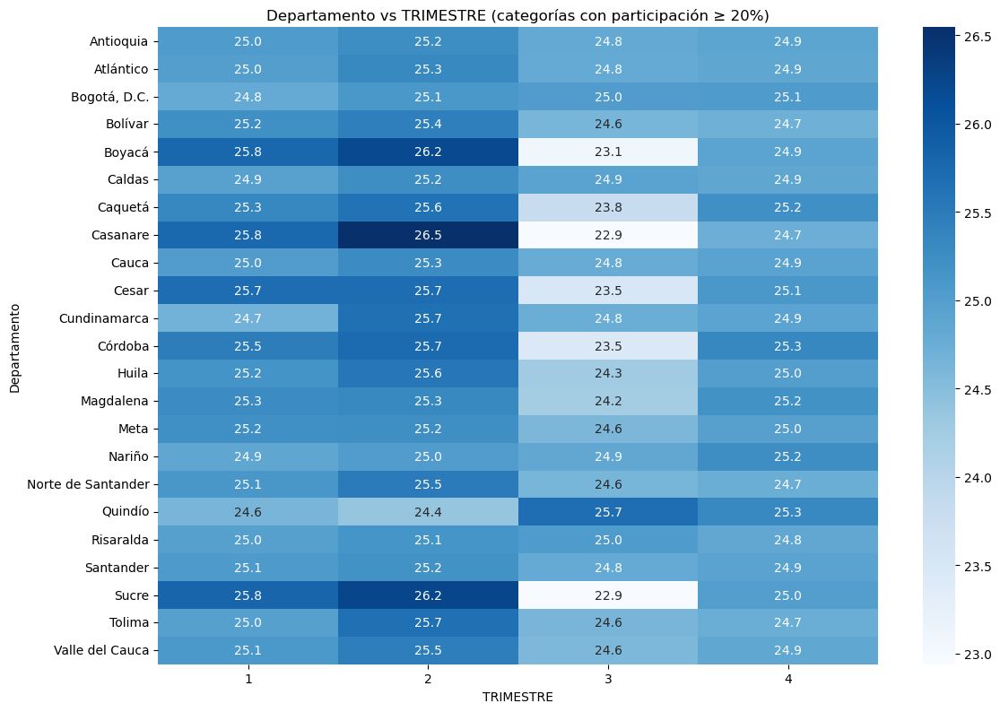


Tabla cruzada: Departamento vs DESTINO2


DESTINO2,Apartamentos,Casas
Departamento,,
Antioquia,54.55,18.43
Atlántico,38.44,43.78
"Bogotá, D.C.",26.96,48.51
Bolívar,29.23,48.80
Boyacá,45.91,35.90
Caldas,21.92,64.43
Caquetá,16.21,69.98
Casanare,21.95,63.95
Cauca,9.74,79.04


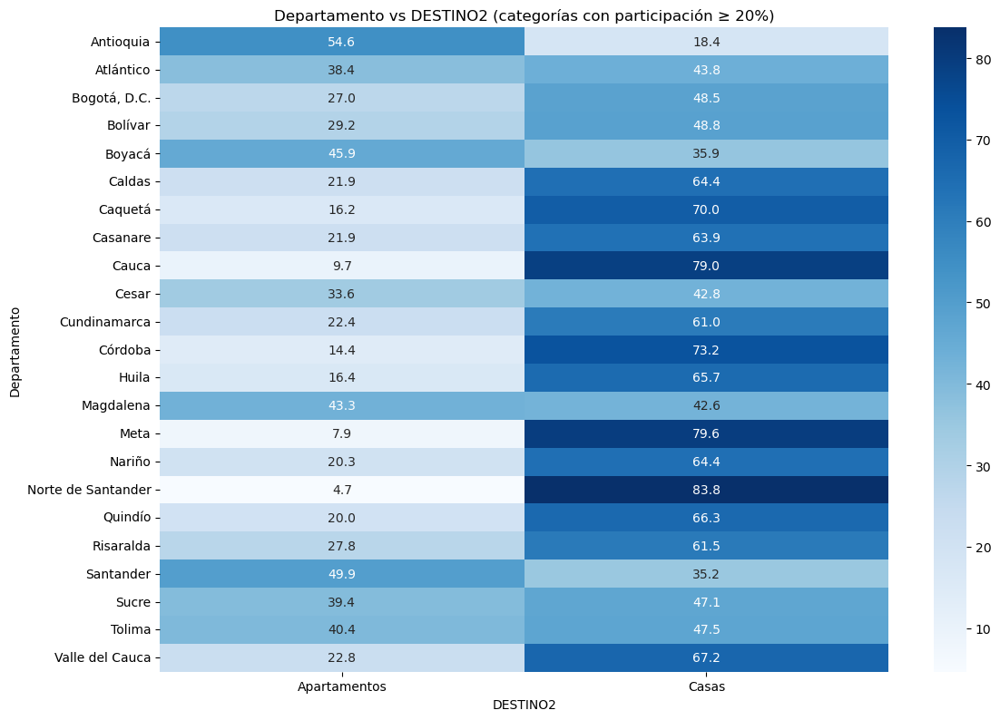


Tabla cruzada: Departamento vs ESTADO_ACT


ESTADO_ACT,En proceso,Paralizada completa,Suspendida
Departamento,,,
Antioquia,49.93,30.34,3.71
Atlántico,27.70,48.16,12.67
"Bogotá, D.C.",42.00,32.24,8.07
Bolívar,36.24,45.82,5.26
Boyacá,43.31,38.69,3.00
Caldas,35.28,41.23,8.70
Caquetá,33.31,51.97,0.00
Casanare,31.18,53.98,0.00
Cauca,29.28,46.85,10.14


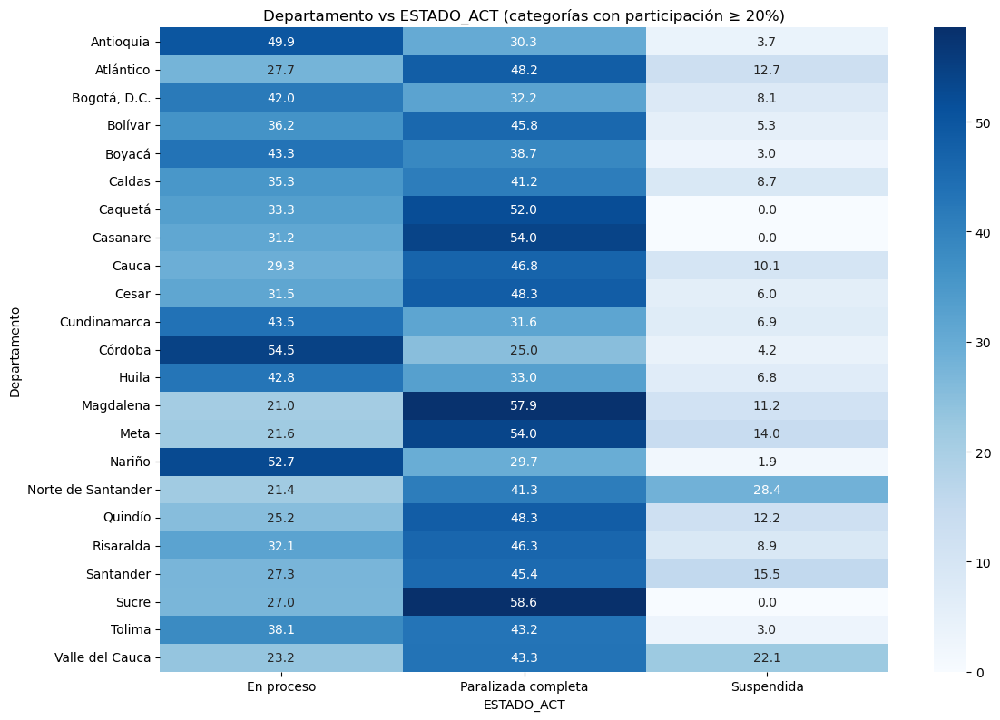


Tabla cruzada: Departamento vs MOVIMIENTO


MOVIMIENTO,Continúa en estado anterior,Obra suspendida
Departamento,,
Antioquia,58.57,3.71
Atlántico,58.24,12.67
"Bogotá, D.C.",54.33,8.07
Bolívar,61.40,5.26
Boyacá,64.58,3.00
Caldas,54.18,8.70
Caquetá,57.59,0.00
Casanare,55.85,0.00
Cauca,52.68,10.14


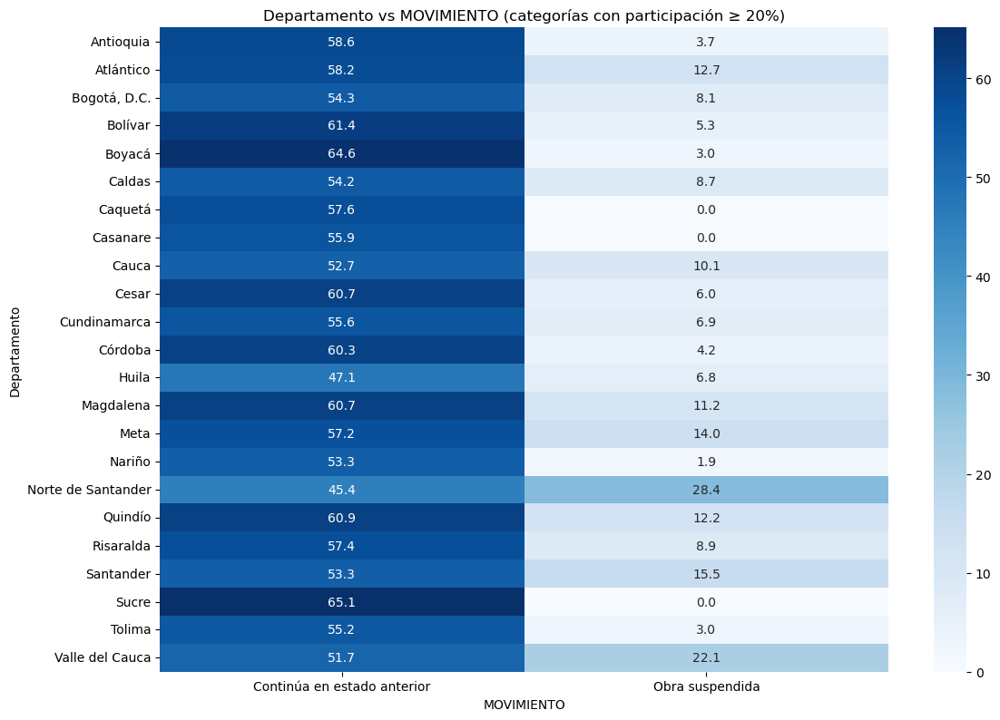


Tabla cruzada: Departamento vs ESTRATO


ESTRATO,Estrato 1,Estrato 2,Estrato 3,Estrato 4
Departamento,,,,
Antioquia,2.40,14.89,46.89,20.22
Atlántico,21.98,40.76,22.21,7.56
"Bogotá, D.C.",10.22,35.32,38.96,7.98
Bolívar,9.82,34.11,29.11,14.84
Boyacá,1.36,29.91,52.90,10.03
Caldas,13.35,34.07,34.27,11.05
Caquetá,53.76,17.65,23.32,5.15
Casanare,29.71,51.75,14.55,3.61
Cauca,19.49,39.51,26.89,10.00


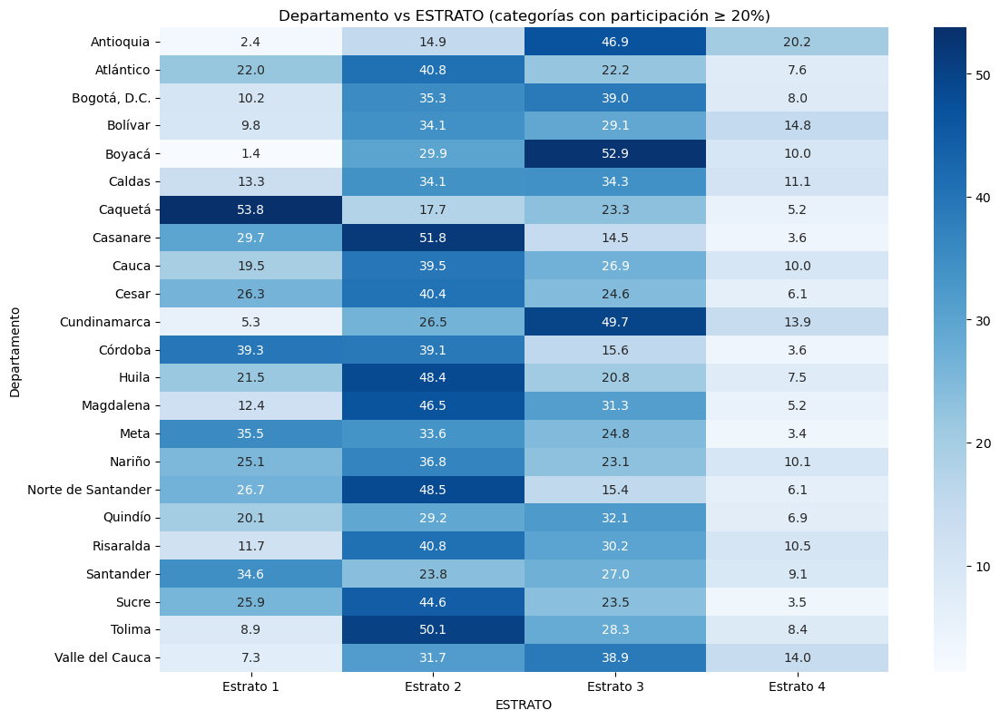


Tabla cruzada: Departamento vs USO


USO,No venta,Sí venta
Departamento,,
Antioquia,67.88,32.12
Atlántico,85.47,14.53
"Bogotá, D.C.",78.57,21.43
Bolívar,78.72,21.28
Boyacá,69.68,30.32
Caldas,83.82,16.18
Caquetá,90.00,10.00
Casanare,91.09,8.91
Cauca,89.39,10.61


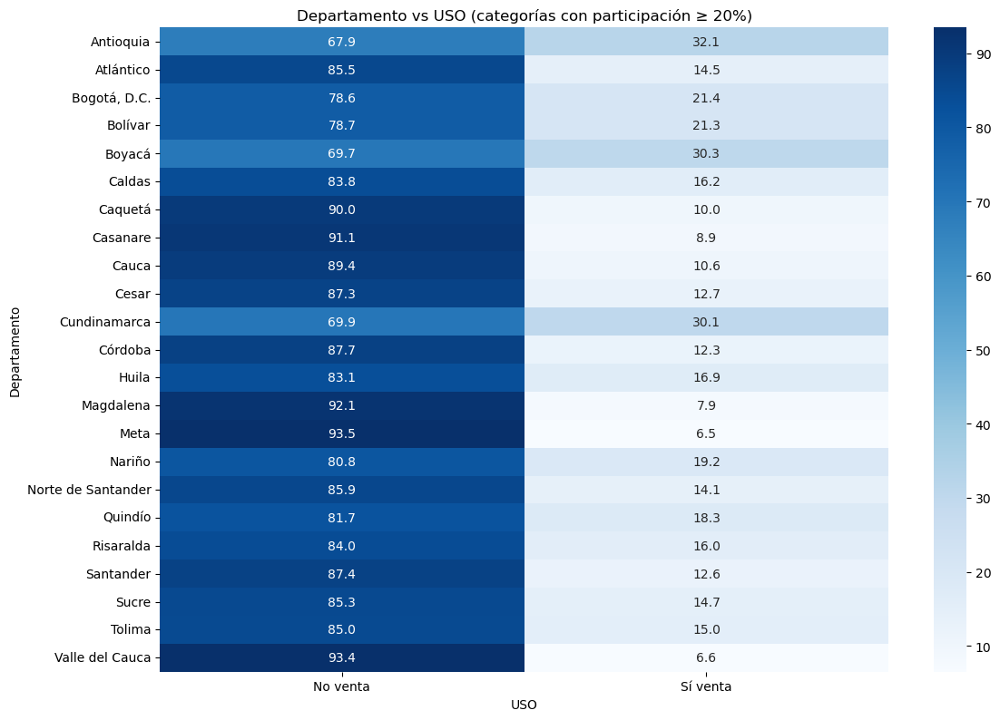


Tabla cruzada: Departamento vs USO_DOS


USO_DOS,Arrendamiento,Uso propio
Departamento,,
Antioquia,30.60,68.48
Atlántico,28.55,71.05
"Bogotá, D.C.",17.33,82.45
Bolívar,21.10,78.15
Boyacá,50.88,49.09
Caldas,8.92,90.33
Caquetá,23.35,76.10
Casanare,14.86,84.21
Cauca,12.27,87.54


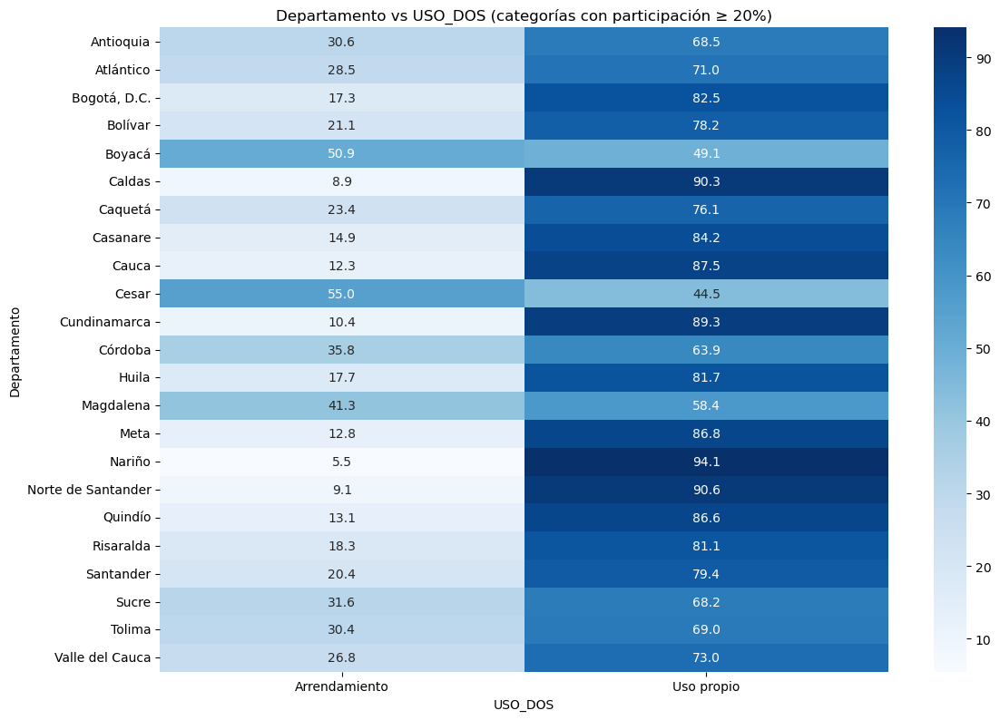


Tabla cruzada: Departamento vs TIPOVRDEST


TIPOVRDEST,No,Sí
Departamento,,
Antioquia,15.20,84.80
Atlántico,27.60,72.40
"Bogotá, D.C.",36.91,63.09
Bolívar,35.43,64.57
Boyacá,2.24,97.76
Caldas,11.93,88.07
Caquetá,2.40,97.60
Casanare,6.94,93.06
Cauca,35.42,64.58


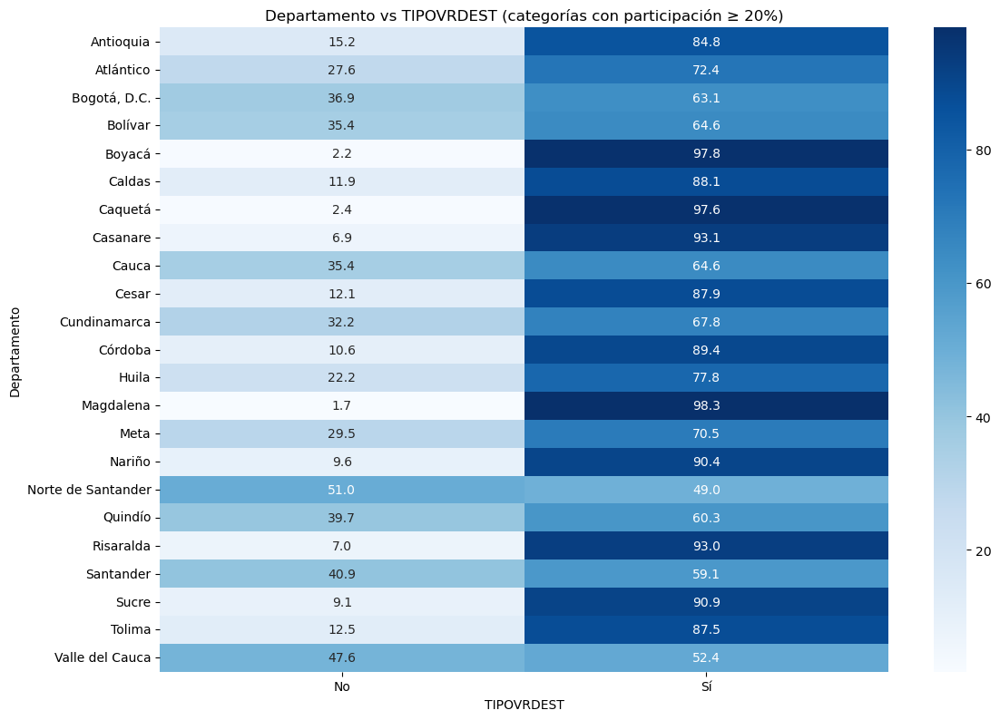


Tabla cruzada: Departamento vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 5,Rango 6
Departamento,,,,,,
Antioquia,27.37,1.25,3.91,6.13,31.87,20.22
Atlántico,18.29,9.90,17.82,15.60,16.94,7.71
"Bogotá, D.C.",25.17,5.47,7.56,7.99,27.04,17.45
Bolívar,21.96,2.25,8.03,10.30,26.60,18.25
Boyacá,18.28,0.14,3.48,4.46,47.52,14.27
Caldas,13.65,20.40,16.73,11.03,21.36,6.74
Caquetá,13.94,12.38,27.97,8.33,25.01,4.22
Casanare,14.15,9.47,25.77,13.06,20.83,5.96
Cauca,11.21,10.06,19.86,17.12,24.48,5.88


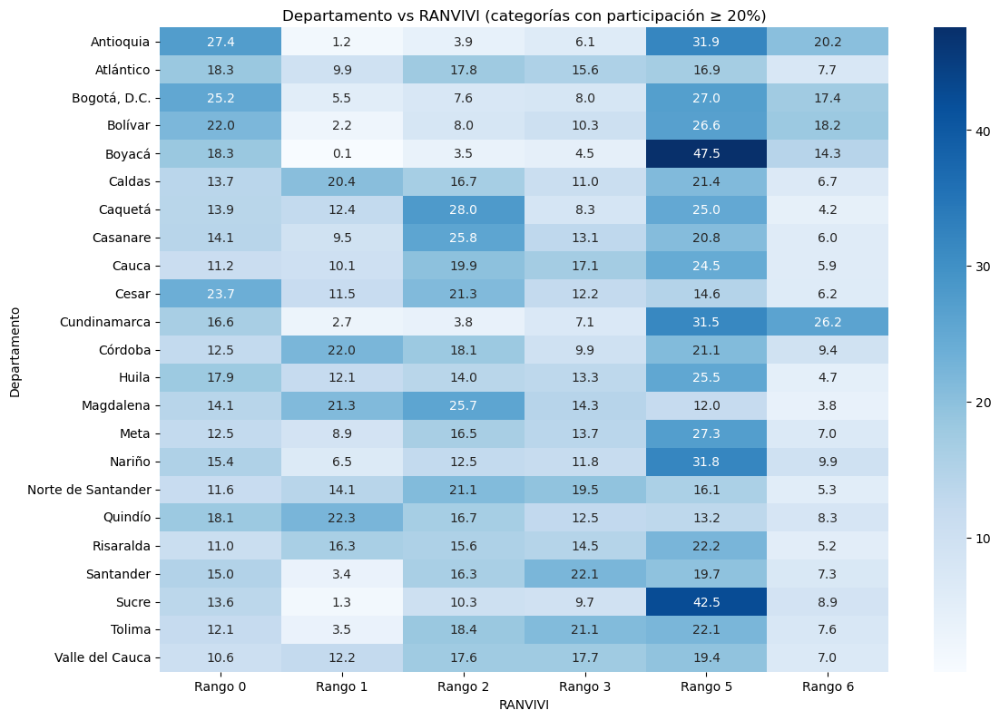


Tabla cruzada: Departamento vs CAPITULO


CAPITULO,Acabados nivel 1,Estructura y cubierta,Mampostería y pañete
Departamento,,,
Antioquia,14.96,33.82,24.02
Atlántico,22.90,21.74,36.74
"Bogotá, D.C.",12.89,33.88,24.39
Bolívar,22.06,25.41,28.27
Boyacá,15.21,37.33,22.19
Caldas,18.48,23.62,35.15
Caquetá,26.26,21.68,26.91
Casanare,29.98,20.83,28.19
Cauca,27.83,20.90,29.34


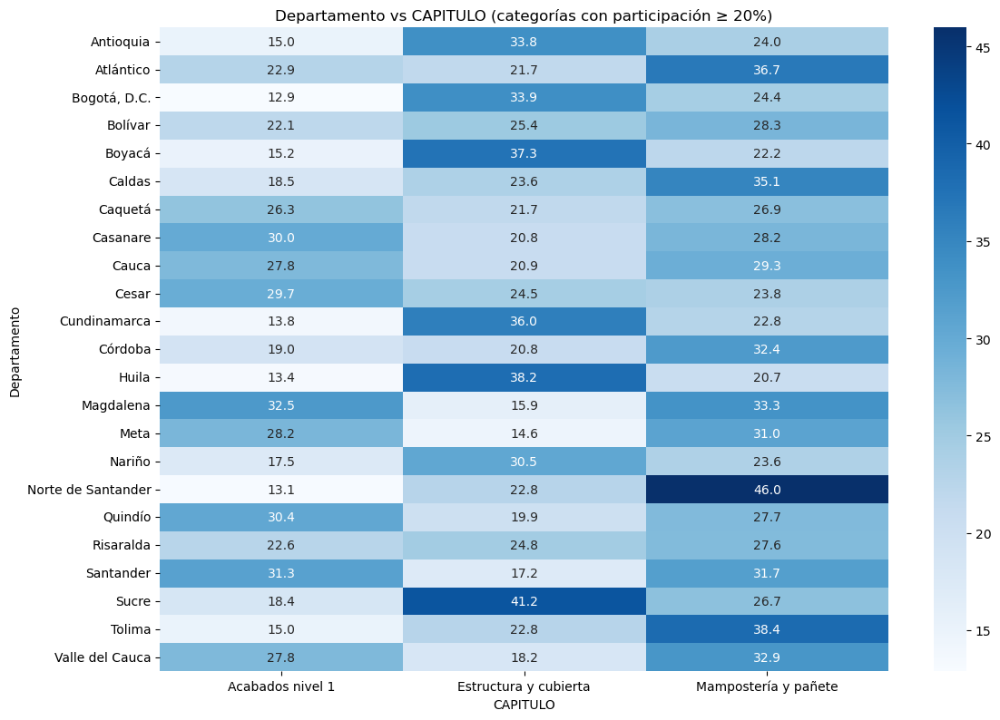


Tabla cruzada: Municipio vs TRIMESTRE


TRIMESTRE,1,2,3,4
Municipio,,,,
Acacías,25.64,26.14,23.67,24.54
Armenia,24.63,24.37,25.68,25.32
Barbosa,25.17,24.98,24.56,25.29
Barranquilla,24.99,25.15,24.97,24.88
Bello,25.26,24.95,24.83,24.96
"Bogotá, D.C.",24.81,25.10,25.04,25.05
Bucaramanga,24.91,24.92,25.13,25.04
Cajicá,25.21,25.60,24.31,24.88
Caldas,24.89,25.40,25.23,24.48


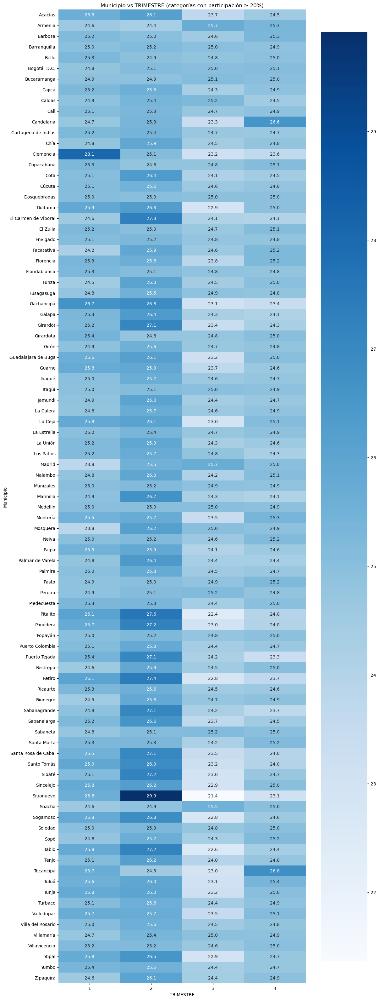


Tabla cruzada: Municipio vs DESTINO2


DESTINO2,Apartamentos,Bodegas,Casas,Comercio,Educación
Municipio,,,,,
Acacías,19.30,3.82,65.36,9.27,2.04
Armenia,19.99,1.78,66.28,7.18,4.00
Barbosa,74.32,0.19,3.78,14.48,7.22
Barranquilla,38.92,3.91,41.08,7.90,6.97
Bello,61.93,2.89,14.21,13.00,6.87
"Bogotá, D.C.",26.96,6.68,48.51,8.81,6.62
Bucaramanga,49.61,3.42,30.04,11.26,4.20
Cajicá,20.31,0.45,65.11,5.66,8.42
Caldas,61.43,3.24,2.83,25.73,6.69


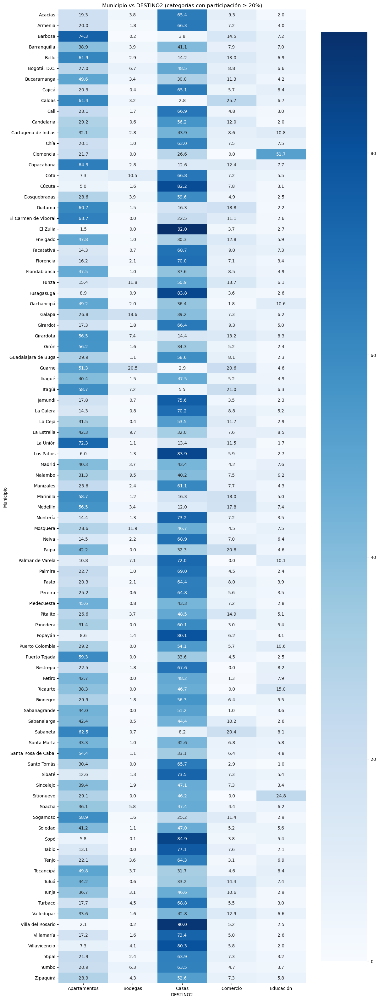


Tabla cruzada: Municipio vs ESTADO_ACT


ESTADO_ACT,En proceso,Paralizada completa,Paralizada incompleta,Suspendida
Municipio,,,,
Acacías,32.23,53.31,1.60,0.00
Armenia,25.22,48.32,4.67,12.16
Barbosa,30.19,47.57,2.66,8.57
Barranquilla,30.19,45.30,2.60,11.81
Bello,42.49,38.01,1.10,4.64
"Bogotá, D.C.",42.00,32.24,3.54,8.07
Bucaramanga,30.37,42.54,1.91,14.86
Cajicá,42.18,32.25,4.16,10.02
Caldas,54.13,27.35,1.14,3.89


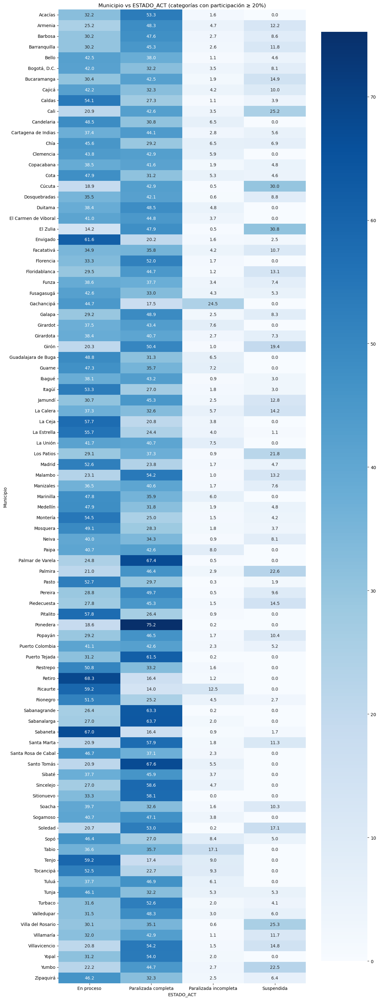


Tabla cruzada: Municipio vs MOVIMIENTO


MOVIMIENTO,Continúa en estado anterior,Obra nueva,Obra suspendida
Municipio,,,
Acacías,57.49,15.10,0.00
Armenia,60.90,8.65,12.16
Barbosa,58.38,11.93,8.57
Barranquilla,58.34,10.56,11.81
Bello,56.82,14.36,4.64
"Bogotá, D.C.",54.33,14.47,8.07
Bucaramanga,54.81,10.46,14.86
Cajicá,57.99,12.10,10.02
Caldas,57.78,14.12,3.89


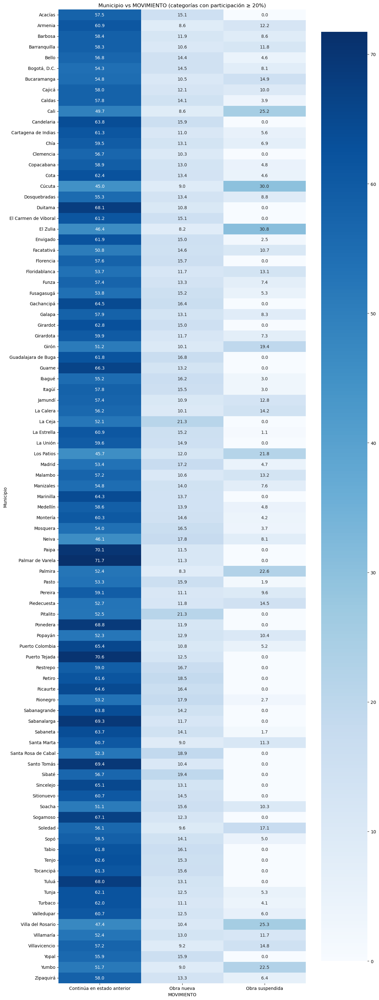


Tabla cruzada: Municipio vs ESTRATO


ESTRATO,Estrato 1,Estrato 2,Estrato 3,Estrato 4,Estrato 5,Estrato 6
Municipio,,,,,,
Acacías,16.95,49.30,30.48,1.56,1.72,0.00
Armenia,20.14,29.23,32.10,6.91,9.67,1.96
Barbosa,0.66,44.17,52.63,2.55,0.00,0.00
Barranquilla,18.37,27.09,32.45,12.41,4.66,5.02
Bello,7.21,24.41,47.45,19.62,1.19,0.13
"Bogotá, D.C.",10.22,35.32,38.96,7.98,3.64,3.88
Bucaramanga,36.66,12.14,29.03,17.63,2.32,2.23
Cajicá,0.81,19.06,50.74,17.18,10.45,1.76
Caldas,0.37,28.71,68.25,2.61,0.06,0.00


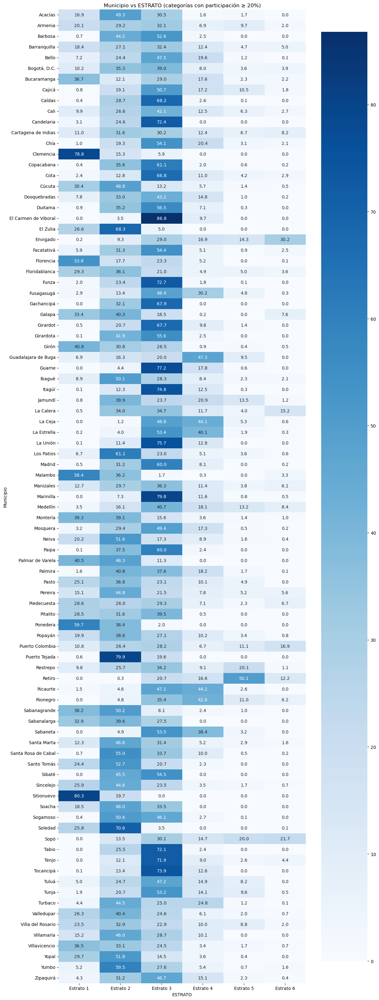


Tabla cruzada: Municipio vs USO


USO,No venta,Sí venta
Municipio,,
Acacías,90.92,9.08
Armenia,81.66,18.34
Barbosa,83.32,16.68
Barranquilla,84.38,15.62
Bello,71.32,28.68
"Bogotá, D.C.",78.57,21.43
Bucaramanga,83.09,16.91
Cajicá,64.85,35.15
Caldas,50.18,49.82


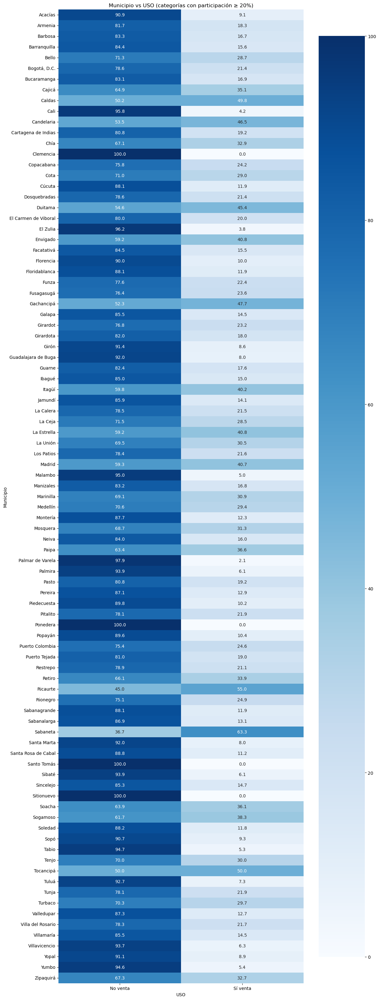


Tabla cruzada: Municipio vs USO_DOS


USO_DOS,Arrendamiento,Uso propio
Municipio,,
Acacías,31.09,68.91
Armenia,13.06,86.56
Barbosa,46.83,52.64
Barranquilla,27.54,72.12
Bello,30.34,68.73
"Bogotá, D.C.",17.33,82.45
Bucaramanga,19.12,80.42
Cajicá,9.88,90.02
Caldas,44.68,53.60


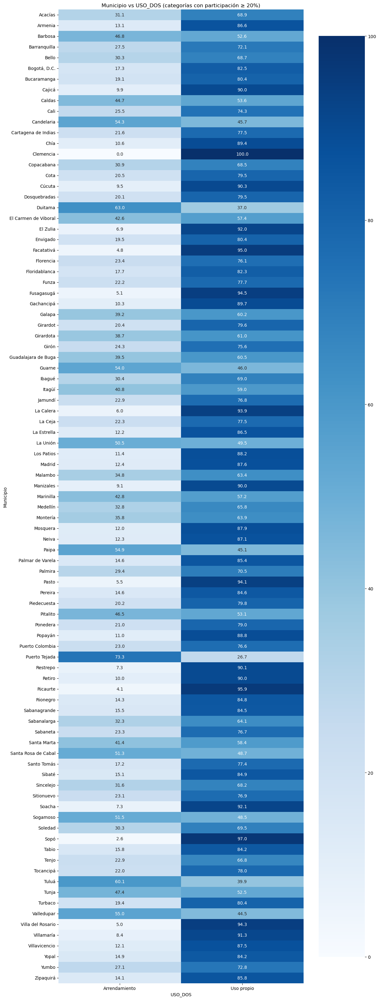


Tabla cruzada: Municipio vs TIPOVRDEST


TIPOVRDEST,No,Sí
Municipio,,
Acacías,8.37,91.63
Armenia,39.65,60.35
Barbosa,26.33,73.67
Barranquilla,27.75,72.25
Bello,17.32,82.68
"Bogotá, D.C.",36.91,63.09
Bucaramanga,40.30,59.70
Cajicá,35.29,64.71
Caldas,12.65,87.35


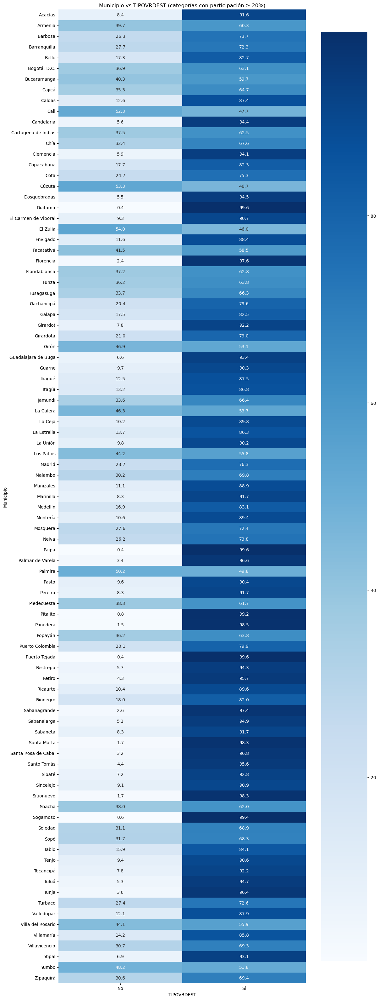


Tabla cruzada: Municipio vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 4,Rango 5,Rango 6
Municipio,,,,,,,
Acacías,14.88,6.07,27.24,11.44,11.91,24.01,4.46
Armenia,18.09,22.31,16.74,12.54,8.88,13.16,8.28
Barbosa,22.86,0.89,7.38,13.24,12.97,42.08,0.58
Barranquilla,20.91,7.20,13.95,13.17,13.21,22.31,9.26
Bello,23.94,2.59,7.19,10.76,14.15,36.64,4.73
"Bogotá, D.C.",25.17,5.47,7.56,7.99,9.33,27.04,17.45
Bucaramanga,20.66,3.80,16.70,15.99,11.49,23.00,8.36
Cajicá,14.63,0.11,0.98,2.37,6.60,29.19,46.13
Caldas,35.70,1.21,2.08,5.61,14.18,40.41,0.80


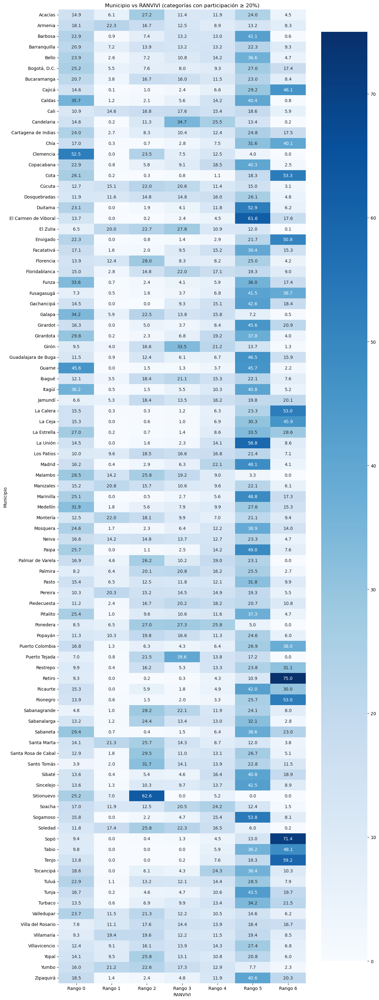


Tabla cruzada: Municipio vs CAPITULO


CAPITULO,Acabados nivel 1,Estructura y cubierta,Mampostería y pañete
Municipio,,,
Acacías,26.43,19.14,30.02
Armenia,30.44,19.95,27.75
Barbosa,11.31,23.51,48.73
Barranquilla,22.23,22.81,34.46
Bello,13.76,34.23,28.11
"Bogotá, D.C.",12.89,33.88,24.39
Bucaramanga,27.82,18.57,32.50
Cajicá,16.42,33.52,24.98
Caldas,15.97,34.64,22.43


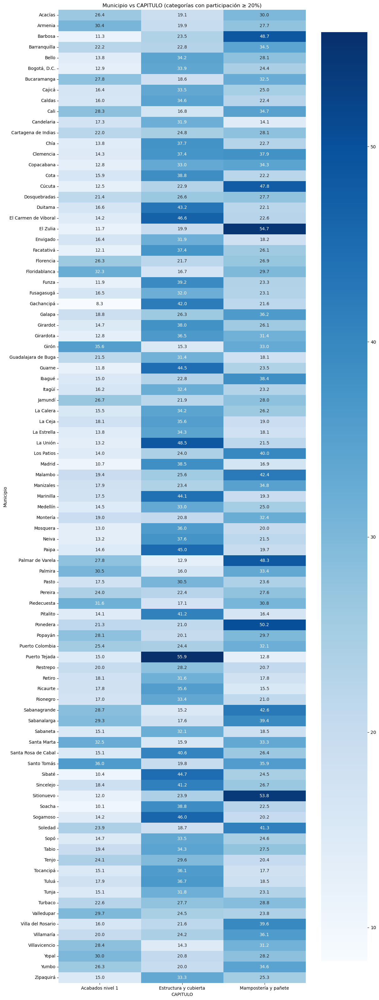

In [56]:
# Umbral mínimo de participación (%)
umbral = 20  # Puedes cambiarlo a 50

# Variables geográficas que queremos conservar
geograficas = ["Departamento", "Municipio"]

# Variables categóricas restantes
otras_categoricas = [
    col for col in categoricas.columns
    if col not in geograficas
]

# Cruces de Departamento y Municipio con las demás variables
for variable_geo in geograficas:

    for variable in otras_categoricas:

        print(f"\nTabla cruzada: {variable_geo} vs {variable}")

        # Tabla cruzada en porcentajes por fila
        tabla = pd.crosstab(
            df_tratado2[variable_geo],
            df_tratado2[variable],
            normalize="index",
            dropna=False
        ) * 100

        # Conservar categorías que alcancen el umbral
        categorias_validas = tabla.columns[
            (tabla >= umbral).any(axis=0)
        ]

        tabla_filtrada = tabla[categorias_validas]

        # Mostrar tabla
        display(tabla_filtrada.round(2))

        # Mapa de calor
        if not tabla_filtrada.empty:

            plt.figure(figsize=(12, max(5, len(tabla_filtrada) * 0.35)))

            sns.heatmap(
                tabla_filtrada,
                annot=True,
                fmt=".1f",
                cmap="Blues"
            )

            plt.title(
                f"{variable_geo} vs {variable} "
                f"(categorías con participación ≥ {umbral}%)"
            )
            plt.xlabel(variable)
            plt.ylabel(variable_geo)
            plt.tight_layout()
            plt.show()


## 7. Relaciones entre variables numéricas

,ANO_CENSO,CENSO_NUMERO,NUMUNIDEST,NUMUNIVEN,NUMUNIXVEN,UNI_DEC_VIP,UNI_DEC_VIS,UNI_DEC_NOVIS,PRECIOVTAX,AREAVENDIB,AREAVENUNI,AREATOTCO2,NRO_EDIFIC,NRO_PISOS,GRADOAVANC,ANOCULMINA,MESCULMINA
ANO_CENSO,1.000000,0.998385,-0.003708,-0.013402,-0.041049,-0.019763,0.042869,-0.028940,0.349504,-0.030712,-0.009849,-0.024906,-0.025783,0.171650,0.003854,0.529798,-0.069746
CENSO_NUMERO,0.998385,1.000000,-0.003679,-0.013515,-0.041157,-0.019798,0.043001,-0.028985,0.349907,-0.030740,-0.009857,-0.024927,-0.025782,0.172038,0.004244,0.529214,-0.032355
NUMUNIDEST,-0.003708,-0.003679,1.000000,0.379747,0.415307,0.281649,0.589707,0.724785,0.285383,0.632632,-0.027810,0.639557,0.222527,0.630602,-0.000787,-0.001952,0.007025
NUMUNIVEN,-0.013402,-0.013515,0.379747,1.000000,0.165623,0.107844,0.267390,0.241740,0.100315,0.220404,-0.011389,0.214349,0.094442,0.238285,-0.054589,-0.019610,0.006203
NUMUNIXVEN,-0.041049,-0.041157,0.415307,0.165623,1.000000,0.115135,0.172534,0.352391,0.134899,0.291310,-0.011768,0.299114,0.132588,0.218791,-0.041973,-0.013843,-0.000197
UNI_DEC_VIP,-0.019763,-0.019798,0.281649,0.107844,0.115135,1.000000,-0.016063,-0.027525,-0.024516,0.154050,-0.084107,0.133211,0.362031,0.062271,0.006346,-0.011669,0.002674
UNI_DEC_VIS,0.042869,0.043001,0.589707,0.267390,0.172534,-0.016063,1.000000,-0.033298,0.113842,0.381976,-0.096422,0.358072,0.133270,0.391459,0.005207,0.019440,0.009100
UNI_DEC_NOVIS,-0.028940,-0.028985,0.724785,0.241740,0.352391,-0.027525,-0.033298,1.000000,0.379709,0.796690,-0.032960,0.803801,0.043907,0.547003,-0.004575,-0.012635,0.001668
PRECIOVTAX,0.349504,0.349907,0.285383,0.100315,0.134899,-0.024516,0.113842,0.379709,1.000000,0.311576,0.079866,0.326065,0.010501,0.400438,0.018899,0.226113,-0.005205
AREAVENDIB,-0.030712,-0.030740,0.632632,0.220404,0.291310,0.154050,0.381976,0.796690,0.311576,1.000000,0.606411,0.962557,0.125592,0.485356,-0.002167,-0.015060,0.004817


KeyboardInterrupt: 

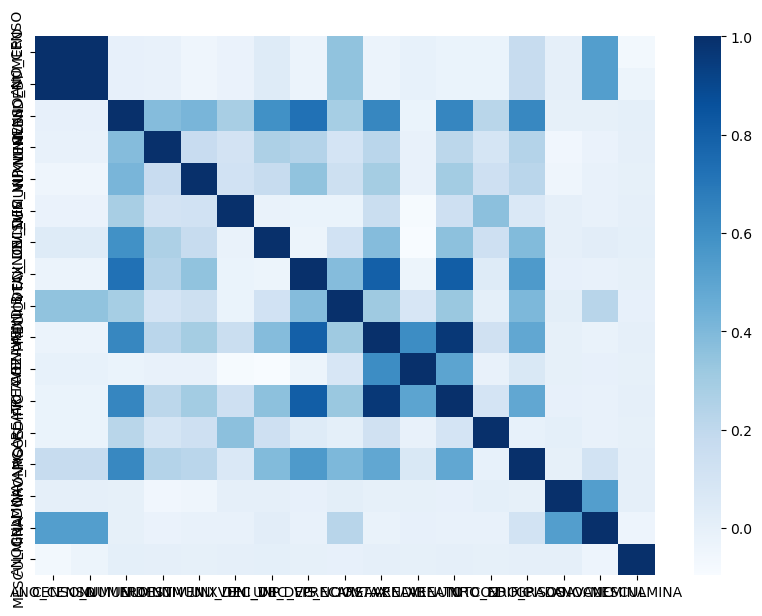

In [57]:
if numericas.shape[1] >= 2:
    correlaciones = numericas.corr()
    display(correlaciones)

    plt.figure(figsize=(10, 7))
    sns.heatmap(correlaciones, cmap="Blues", annot=True)
    plt.title("Correlación de variables numéricas")
    plt.tight_layout()
    plt.show()
else:
    print("No hay suficientes variables numéricas para calcular correlaciones.")

,Variable 1,Variable 2,Correlación,Valor absoluto
0,ANO_CENSO,CENSO_NUMERO,0.998385,0.998385
2,AREAVENDIB,AREATOTCO2,0.962557,0.962557
1,UNI_DEC_NOVIS,AREATOTCO2,0.803801,0.803801


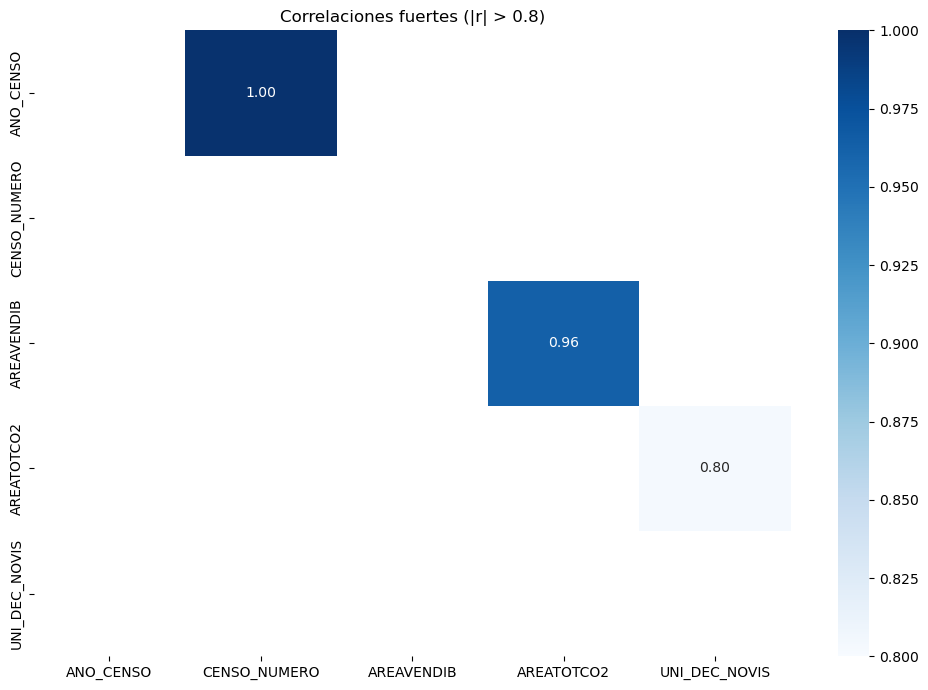

In [64]:

# CORRELACIONES FUERTES (VALOR ABSOLUTO > 0.8)


import numpy as np

# Evitar la diagonal y las parejas repetidas
mascara = np.triu(
    np.ones(correlaciones.shape, dtype=bool),
    k=1
)

# Filtrar correlaciones fuertes en valor absoluto
correlaciones_fuertes = correlaciones.where(
    mascara & (correlaciones.abs() > 0.8)
)

# Crear tabla de parejas de variables
pares_fuertes = (
    correlaciones_fuertes
    .stack()
    .reset_index()
)

pares_fuertes.columns = [
    "Variable 1",
    "Variable 2",
    "Correlación"
]

# Agregar valor absoluto para ordenar
pares_fuertes["Valor absoluto"] = (
    pares_fuertes["Correlación"].abs()
)

pares_fuertes = pares_fuertes.sort_values(
    "Valor absoluto", ascending=False
)

display(pares_fuertes)

# Mapa de calor de correlaciones fuertes
if not pares_fuertes.empty:

    variables_fuertes = pd.unique(
        pares_fuertes[["Variable 1", "Variable 2"]].values.ravel()
    )

    matriz_fuertes = correlaciones.loc[
        variables_fuertes, variables_fuertes
    ]

    # Mostrar solo una vez cada correlación fuerte
    mascara_mapa = ~(
        np.triu(
            np.ones(matriz_fuertes.shape, dtype=bool),
            k=1
        )
        & (matriz_fuertes.abs() > 0.8)
    )

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        matriz_fuertes.abs(),
        mask=mascara_mapa,
        cmap="Blues",
        annot=matriz_fuertes,
        fmt=".2f",
        vmin=0.8,
        vmax=1
    )

    plt.title("Correlaciones fuertes (|r| > 0.8)")
    plt.tight_layout()
    plt.show()

else:
    print("No se encontraron correlaciones con |r| > 0.8.")





In [ ]:
# Obtener todas las combinaciones de variables numéricas
pares = list(combinations(numericas.columns, 2))

if len(pares) > 0:

    columnas = 3
    filas = math.ceil(len(pares) / columnas)

    fig, axes = plt.subplots(
        filas, columnas,
        figsize=(15, 4 * filas)
    )

    axes = np.array(axes).flatten()

    for i, (variable_x, variable_y) in enumerate(pares):

        axes[i].scatter(
            dfprovisional[variable_x],
            dfprovisional[variable_y],
            alpha=0.3
        )

        axes[i].set_title(f"{variable_x} vs. {variable_y}")
        axes[i].set_xlabel(variable_x)
        axes[i].set_ylabel(variable_y)
        axes[i].grid(alpha=0.3)

    # Eliminar espacios sobrantes
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

else:
    print("Se necesitan al menos dos variables numéricas.")

In [58]:

# Análisis residencial: cuarto trimestre de 2025
# Ejecutar después de actualizar df_tratado2

vivienda_2025 = df_tratado2.loc[
    df_tratado2["ANO_CENSO"].eq(2025)
    & df_tratado2["TRIMESTRE"].astype("string").eq("4")
    & df_tratado2["DESTINO2"].isin(["Apartamentos", "Casas"])
].copy()

print("Registros residenciales:", len(vivienda_2025))

# Caracterización por municipio
resumen_municipal = (
    vivienda_2025
    .groupby(
        ["DPTO_MPIO", "Departamento", "Municipio"],
        observed=True
    )
    .agg(
        registros=("NOFORMULAR", "size"),
        formularios_unicos=("NOFORMULAR", "nunique"),
        unidades_registradas=("NUMUNIDEST", "sum")
    )
    .sort_values("unidades_registradas", ascending=False)
)

display(resumen_municipal.head(15))

# Estado de las obras según tipo de vivienda
estado_vivienda = pd.crosstab(
    vivienda_2025["DESTINO2"],
    vivienda_2025["ESTADO_ACT"],
    normalize="index"
).mul(100).round(2)

display(estado_vivienda)


Registros residenciales: 39111


,,,registros,formularios_unicos,unidades_registradas
DPTO_MPIO,Departamento,Municipio,,,
11001,"Bogotá, D.C.","Bogotá, D.C.",3395,3395,110252
76001,Valle del Cauca,Cali,4558,4558,24933
05001,Antioquia,Medellín,820,820,16344
08001,Atlántico,Barranquilla,1344,1344,11690
47001,Magdalena,Santa Marta,1097,1097,11466
13001,Bolívar,Cartagena de Indias,623,623,11304
05088,Antioquia,Bello,253,253,10898
73001,Tolima,Ibagué,1364,1364,10741
05631,Antioquia,Sabaneta,82,82,8078


ESTADO_ACT,Culminada completa,Culminada incompleta,En proceso,Paralizada completa,Paralizada incompleta,Suspendida
DESTINO2,,,,,,
Apartamentos,10.69,0.43,36.47,50.19,1.49,0.74
Casas,10.56,1.71,30.28,43.69,2.26,11.49


In [ ]:
# 1. SELECCIÓN Y VALIDACIÓN COMERCIAL

# Vivienda destinada a venta, IV trimestre 2025
df_comercial = vivienda_2025.loc[
    vivienda_2025["USO"] == "Sí venta"
].copy()

print("Registros residenciales:", len(vivienda_2025))
print("Registros destinados a venta:", len(df_comercial))

# Revisar completitud y valores negativos
variables = ["NUMUNIDEST", "NUMUNIVEN", "NUMUNIXVEN"]

calidad_comercial = pd.DataFrame({
    "Nulos": df_comercial[variables].isna().sum(),
    "% Nulos": (
        df_comercial[variables].isna().mean() * 100
    ).round(2),
    "Negativos": (
        df_comercial[variables] < 0
    ).sum()
})

display(calidad_comercial)

# Validaciones de consistencia
ventas_excedidas = (
    df_comercial["NUMUNIVEN"] >
    df_comercial["NUMUNIDEST"]
).sum()

saldos_excedidos = (
    df_comercial["NUMUNIXVEN"] >
    df_comercial["NUMUNIDEST"]
).sum()

print("Ventas mayores a unidades totales:", ventas_excedidas)
print("Saldo mayor a unidades totales:", saldos_excedidos)


Registros residenciales: 39111
Registros destinados a venta: 7567


,Nulos,% Nulos,Negativos
NUMUNIDEST,0,0.0,0
NUMUNIVEN,0,0.0,0
NUMUNIXVEN,0,0.0,0


Ventas mayores a unidades totales: 0
Saldo mayor a unidades totales: 2


In [60]:
# 2. INDICADORES COMERCIALES POR MUNICIPIO

def suma_valida(serie):
    return serie.sum(min_count=1)

resumen_comercial = (
    df_comercial
    .groupby(
        ["DPTO_MPIO", "Departamento", "Municipio"],
        observed=True
    )
    .agg(
        registros=("NOFORMULAR", "size"),
        unidades=("NUMUNIDEST", suma_valida),
        vendidas_periodo=("NUMUNIVEN", suma_valida),
        saldo_por_vender=("NUMUNIXVEN", suma_valida),
        registros_con_ventas=("NUMUNIVEN", "count"),
        registros_con_saldo=("NUMUNIXVEN", "count")
    )
    .reset_index()
)

# Cobertura de la información comercial
resumen_comercial["% datos ventas"] = (
    resumen_comercial["registros_con_ventas"] /
    resumen_comercial["registros"] * 100
).round(2)

resumen_comercial["% datos saldo"] = (
    resumen_comercial["registros_con_saldo"] /
    resumen_comercial["registros"] * 100
).round(2)

# Municipios con mayor saldo por vender
top_saldo = resumen_comercial.sort_values(
    "saldo_por_vender", ascending=False
).head(15)

display(top_saldo)

# Municipios con mayores ventas en el período
top_ventas = resumen_comercial.sort_values(
    "vendidas_periodo", ascending=False
).head(15)

display(top_ventas)


,DPTO_MPIO,Departamento,Municipio,registros,unidades,vendidas_periodo,saldo_por_vender,registros_con_ventas,registros_con_saldo,% datos ventas,% datos saldo
23,11001,"Bogotá, D.C.","Bogotá, D.C.",1276,101934,9662,8402,1276,1276,100.0,100.0
0,05001,Antioquia,Medellín,279,12480,378,1048,279,279,100.0,100.0
50,25754,Cundinamarca,Soacha,152,5390,265,1026,152,152,100.0,100.0
16,05631,Antioquia,Sabaneta,72,7947,374,860,72,72,100.0,100.0
24,13001,Bolívar,Cartagena de Indias,277,10601,654,794,277,277,100.0,100.0
26,15001,Boyacá,Tunja,170,3620,372,780,170,170,100.0,100.0
27,15238,Boyacá,Duitama,199,1906,125,758,199,199,100.0,100.0
17,08001,Atlántico,Barranquilla,227,9207,1051,741,227,227,100.0,100.0
76,76001,Valle del Cauca,Cali,288,16507,3111,644,288,288,100.0,100.0
29,15759,Boyacá,Sogamoso,193,1584,189,638,193,193,100.0,100.0


,DPTO_MPIO,Departamento,Municipio,registros,unidades,vendidas_periodo,saldo_por_vender,registros_con_ventas,registros_con_saldo,% datos ventas,% datos saldo
23,11001,"Bogotá, D.C.","Bogotá, D.C.",1276,101934,9662,8402,1276,1276,100.0,100.0
76,76001,Valle del Cauca,Cali,288,16507,3111,644,288,288,100.0,100.0
58,47001,Magdalena,Santa Marta,110,9777,1166,430,110,110,100.0,100.0
17,08001,Atlántico,Barranquilla,227,9207,1051,741,227,227,100.0,100.0
6,05266,Antioquia,Envigado,96,4203,777,343,96,96,100.0,100.0
56,41001,Huila,Neiva,120,2809,766,96,120,120,100.0,100.0
75,73001,Tolima,Ibagué,221,9007,728,490,221,221,100.0,100.0
20,08573,Atlántico,Puerto Colombia,78,4097,667,247,78,78,100.0,100.0
24,13001,Bolívar,Cartagena de Indias,277,10601,654,794,277,277,100.0,100.0
15,05615,Antioquia,Rionegro,77,4963,598,464,77,77,100.0,100.0


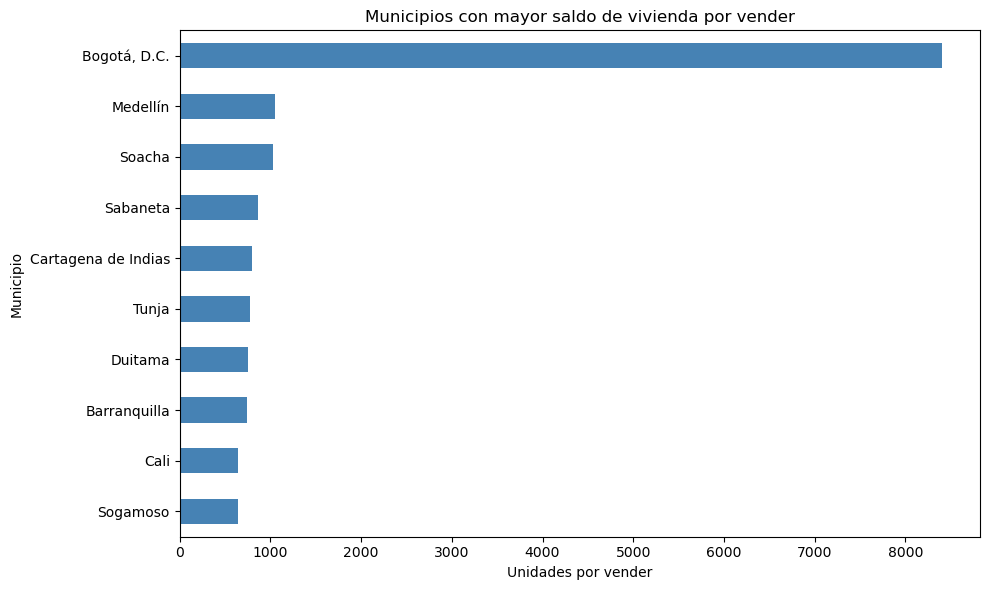

In [61]:

# Top 10 municipios según saldo por vender

top10 = top_saldo.head(10).sort_values(
    "saldo_por_vender"
)

ax = top10.plot(
    x="Municipio",
    y="saldo_por_vender",
    kind="barh",
    figsize=(10, 6),
    color="steelblue",
    legend=False
)

plt.title("Municipios con mayor saldo de vivienda por vender")
plt.xlabel("Unidades por vender")
plt.ylabel("Municipio")
plt.tight_layout()
plt.show()


Cómo se distribuyen las ventas y el inventario de vivienda según el estado de construcción de las edificaciones:

In [62]:

# Comercialización según estado de la obra

comercial_estado = (
    df_comercial
    .groupby("ESTADO_ACT", observed=True)
    .agg(
        registros=("NOFORMULAR", "size"),
        vendidas_periodo=("NUMUNIVEN", suma_valida),
        saldo_por_vender=("NUMUNIXVEN", suma_valida)
    )
)

display(comercial_estado)


,registros,vendidas_periodo,saldo_por_vender
ESTADO_ACT,,,
Culminada completa,1051,554,673
Culminada incompleta,15,15,60
En proceso,4924,29766,22946
Paralizada completa,1487,299,4121
Paralizada incompleta,82,52,1043
Suspendida,8,0,23
